# Hwang Lab Aging PPC figure reproduction

This notebook reproduces the main and supplementary figure panels from the deposited, de-identified data. Run the setup cell first, then use **Run All**. Generated SVG figures and source/statistics tables are written to `outputs/`; plotting mechanics match the paper.

Python 3.12 with `requirements-modern.txt` is the reader-default environment. The archival Python 3.8 environment in `requirements.txt` reproduces the paper output exactly.
The stored outputs in this notebook are retained from the validated Python 3.8 paper-exact run.

The data folder is expected beside this notebook. If it is absent, the setup cell downloads the anticipated publication ZIP from Zenodo (DOI: `10.5281/zenodo.22131935`). When Zenodo metadata provide a checksum, the download is verified; local data are always preferred. See `README.md` for environment setup, expected runtime, and data provenance.


In [1]:
# Publication data and output setup (standard library only)
import hashlib
import json
import os
import shutil
import subprocess
import time
import zipfile
from pathlib import Path


def _find_project_dir(start=None):
    """Find the repository directory even if this cell is re-run from outputs/."""
    start = Path(start or os.environ.get("HWANG_AGING_PROJECT_DIR", Path.cwd())).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "HwangLab_Aging_PPC_Figures.ipynb").exists():
            return candidate
    return start


PROJECT_DIR = _find_project_dir()
DATA_DIR = Path(os.environ.get(
    "HWANG_AGING_DATA_DIR", PROJECT_DIR / "HwangLab_Aging_Data"
)).expanduser().resolve()
OUTPUT_DIR = Path(os.environ.get(
    "HWANG_AGING_OUTPUT_DIR", PROJECT_DIR / "outputs"
)).expanduser().resolve()
MANIFEST_PATH = Path(os.environ.get(
    "HWANG_AGING_DATA_MANIFEST", PROJECT_DIR / "data_manifest.json"
)).expanduser().resolve()
# Zenodo fallback for readers who do not have the ZIP beside the notebook.
ZENODO_ARCHIVE = {
    "filename": "HwangLab_Aging_Data.zip",
    "url": "https://zenodo.org/records/22131935/files/HwangLab_Aging_Data.zip?download=1",
    "size": 2136999570,
    "md5": "bb6789b9a73b200f01a3d6a0f9cd895f",
}


def _file_digest(path, algorithm, chunk_size=8 * 1024 * 1024):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _expected_checksum(item):
    checksum = item.get("checksum", "")
    if checksum:
        algorithm, separator, expected = checksum.partition(":")
        if not separator or not algorithm or not expected:
            raise ValueError("checksum must use the form 'algorithm:hex-digest'")
        return algorithm.lower(), expected.lower()
    for algorithm in ("sha256", "md5"):
        expected = item.get(algorithm) or os.environ.get(
            f"HWANG_AGING_ZENODO_{algorithm.upper()}", ""
        )
        if expected:
            return algorithm, expected.lower()
    return None, None


_RETRYABLE_CURL_ERRORS = {5, 6, 7, 18, 22, 28, 35, 47, 52, 55, 56, 92}


def _download_with_curl(url, target, attempts=10):
    """Download with curl, resuming the retained partial file after failures."""
    curl = shutil.which("curl")
    if curl is None:
        raise RuntimeError(
            "curl was not found. Install curl or place HwangLab_Aging_Data/ "
            "beside this notebook."
        )
    target = Path(target)
    command = [
        curl,
        "--location",
        "--fail",
        "--continue-at",
        "-",
        "--connect-timeout",
        "30",
        "--output",
        str(target),
        url,
    ]
    for attempt in range(1, attempts + 1):
        offset = target.stat().st_size if target.exists() else 0
        if offset:
            print(f"Resuming {target.name} at {offset / 1024**2:.1f} MiB")
        else:
            print(f"Downloading {url}")
        result = subprocess.run(command, check=False)
        if result.returncode == 0:
            return
        if result.returncode not in _RETRYABLE_CURL_ERRORS or attempt == attempts:
            raise RuntimeError(
                f"curl failed with exit code {result.returncode}; partial download "
                f"retained at {target}. Re-run this cell to resume."
            )
        delay = min(5 * attempt, 30)
        print(f"Download interrupted; retrying in {delay} seconds "
              f"({attempt}/{attempts})...")
        time.sleep(delay)


def _download_archive(url, target, item):
    algorithm, expected = _expected_checksum(item)
    expected_size = item.get("size")
    target = Path(target)
    cached_size = target.stat().st_size if target.exists() else None
    cache_has_expected_size = expected_size is None or cached_size == expected_size

    if cached_size is not None and cache_has_expected_size:
        if expected and _file_digest(target, algorithm) == expected:
            print(f"Using verified cached archive: {target}")
            return
        if not expected and zipfile.is_zipfile(target):
            print(f"Using cached archive: {target}")
            return

    _download_with_curl(url, target)
    observed_size = target.stat().st_size
    if expected_size is not None and observed_size != expected_size:
        raise ValueError(
            f"Size mismatch for {target.name}: {observed_size} != {expected_size}"
        )
    if expected:
        observed = _file_digest(target, algorithm)
        if observed != expected:
            raise ValueError(
                f"{algorithm} mismatch for {target.name}: {observed} != {expected}. "
                "Remove the cached archive and re-run this cell to restart it."
            )
        print(f"Verified {algorithm} checksum for {target.name}.")
    else:
        print("No checksum supplied; skipping checksum verification.")


def _safe_extract(archive, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive) as bundle:
        for member in bundle.infolist():
            target = (destination / member.filename).resolve()
            if destination not in target.parents and target != destination:
                raise ValueError(f"Unsafe archive member: {member.filename}")
        bundle.extractall(destination)


def download_data(force=False):
    """Download, verify, and extract every archive in data_manifest.json."""
    marker = DATA_DIR / "release_manifest.json"
    local_required = DATA_DIR / "2026Aging_SubjectDB.npy"
    if DATA_DIR.is_dir() and (marker.exists() or local_required.exists()) and not force:
        print(f"Using verified local data: {DATA_DIR}")
        return DATA_DIR
    if MANIFEST_PATH.exists():
        manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    else:
        # Keep the notebook standalone: use the fixed Zenodo release when no
        # local manifest has been supplied. Set HWANG_AGING_DATA_MANIFEST to
        # override this with a private or newer manifest.
        manifest = {"archives": [ZENODO_ARCHIVE]}
    downloads = PROJECT_DIR / ".data-downloads"
    downloads.mkdir(parents=True, exist_ok=True)
    staging = PROJECT_DIR / ".data-staging"
    if staging.exists():
        shutil.rmtree(staging)
    staging.mkdir(parents=True)

    try:
        for item in manifest["archives"]:
            url = os.environ.get("HWANG_AGING_ZENODO_BASE_URL", item.get("base_url", ""))
            if url:
                url = url.rstrip("/") + "/" + item["filename"]
            else:
                url = item["url"]
            target = downloads / item["filename"]
            _download_archive(url, target, item)
            _safe_extract(target, staging)

        extracted = staging / DATA_DIR.name
        if not extracted.exists():
            raise FileNotFoundError(f"Archives did not contain {DATA_DIR.name}/")
        if DATA_DIR.exists():
            if not force:
                raise FileExistsError(f"Refusing to overwrite {DATA_DIR}")
            shutil.rmtree(DATA_DIR)
        extracted.replace(DATA_DIR)
    finally:
        shutil.rmtree(staging, ignore_errors=True)

    print(f"Installed verified data at {DATA_DIR}")
    return DATA_DIR


# With a local dataset this is a no-op. If data are absent, it downloads the
# published Zenodo release (or a manifest supplied via the environment), then verifies it.
download_data()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Using verified local data: HwangLab_Aging_Data


In [2]:
# Standard library
import os
import logging
import random
import warnings
import json
import re

from itertools import groupby
import itertools
from pathlib import Path

# Scientific Python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.interpolate as interpolate
import scipy.optimize as opt
import scipy.stats as stats
from scipy.signal import butter, filtfilt
from scipy.stats.distributions import chi2

# Statistics
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower

warnings.filterwarnings('ignore')
# Matplotlib reports a missing Arial fallback once per text artist via logging,
# not the warnings module. Keep the requested paper font but silence that noise.
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# Data paths are initialized and optionally downloaded by the setup cell.
root = DATA_DIR
behavior = root / 'Behavior'
imaging = root / '2P_Imaging'
cFos = root / 'cFos'
Qlearning = root / 'Q_learning'

# Keep generated files out of the repository root. All data paths above are
# absolute, so re-running the analysis remains safe after this directory change.
os.chdir(OUTPUT_DIR)

# ============================================================================
# Subject grouping and plotting utilities
# ============================================================================

def combine_criteria(min_age, max_age, keys, key_values):
##### combine subject group criteria including minimum and maximum ages
##### e.g., criteria = combine_criteria(2, 3, ['line'], ['WT']) to create a group of wild-type, 2-3 months old mice 
    criteria = {}
    group_name = str(min_age)+'-'+str(max_age)+' mo'
    for key_value in key_values:
        group_name = group_name + '-'+ key_value
    criteria['group_name']  = group_name
    criteria['min_age'] = min_age
    criteria['max_age'] = max_age
    for key, key_value in zip(keys, key_values):
        criteria[key] = key_value
    return criteria


def group_subjects(group_criteria, SubjectDB):
##### select subjects in SubjectDB that meet group_criteria
    subject_lists = []
    group_names = []
    ages = []
    sexes = []
    dates = []
    for group in group_criteria:
        group_names.append(group['group_name'])
        subject_indices = np.flatnonzero((SubjectDB['age_months']>=group['min_age'])*(SubjectDB['age_months']<=group['max_age']))
        for key in group.keys():
            if not key in ['group_name', 'min_age', 'max_age']:
                subject_indices = np.intersect1d(subject_indices,np.flatnonzero(SubjectDB[key]==group[key]))
        subject_lists.append(SubjectDB['Mouse ID'][subject_indices])
        ages.append(SubjectDB['age_months'][subject_indices])
        sexes.append((SubjectDB['sex'][subject_indices]=='Female')*1)
    return subject_lists, group_names, ages, sexes, dates


def set_rcParams():
##### set global plot parameters
    plt.rcParams['svg.fonttype'] = 'none' # do not convert text to path
    plt.rcParams['svg.hashsalt'] = 'hwang-aging-ppc'
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['font.size'] = 6.5
    plt.rcParams['font.stretch'] = 'normal'


def set_plot(axe):
##### remove the top and right axis lines
    axe.spines['top'].set_visible(False)
    axe.spines['right'].set_visible(False)
    
set_rcParams()

# ============================================================================
# Data search and loading tools
# ============================================================================

def natural_sort_key(path):
    return [
        int(x) if x.isdigit() else x.lower()
        for x in re.split(r'(\d+)', path.name)
    ]

def find_sessions(subject):
    folder = Path(os.path.join(behavior, subject))
    if folder.exists():
        sessions = sorted((x for x in folder.iterdir() if x.is_dir()), key=natural_sort_key)
    else:
        sessions = []
    return sessions


TRIAL_FIELDS = (
    'bitcode0', 'choice', 'contrastLeft', 'contrastRight', 'feedbackType',
    'feedback_times', 'firstMovement_times', 'intervals', 'optocode2',
    'stimOnTrigger_times',
)


def read_trial_data(session_path=None, subject=None, day='day1', keys=None):
    """Load only trial fields used by this notebook from NPZ or legacy ALF files."""
    if session_path is None:
        if subject is None:
            raise ValueError('Provide session_path or subject')
        session_path = behavior / subject / day
    session_path = Path(session_path)
    if not session_path.is_dir():
        raise FileNotFoundError(f'Behavior session not found: {session_path}')

    requested = tuple(keys) if keys else TRIAL_FIELDS
    archive = session_path / 'trials.npz'
    trial_data = Bunch()
    if archive.exists():
        with np.load(archive, allow_pickle=True) as data:
            for key in requested:
                if key in data.files:
                    trial_data[key] = _ensure_flat(data[key])
    else:
        for key in requested:
            filename = session_path / f'_ibl_trials.{key}.npy'
            if filename.exists():
                trial_data[key] = load_file_content(filename)

    required = {'choice', 'contrastLeft', 'contrastRight', 'feedbackType'}
    missing = required.difference(trial_data)
    if missing:
        raise FileNotFoundError(f'Missing required trial fields {sorted(missing)} in {session_path}')
    return trial_data



def read_behavioral_data(subject, date='day1'):
    trial_data = read_trial_data(subject=subject, day=date)
    
    return trial_data


def read_cell_data(Subject, Date='day1', keys=None):
    """Load the neural fields present for one calcium or voltage experiment."""
    directory = imaging / Subject / Date
    archive = directory / 'imaging_data.npz'
    requested = tuple(keys) if keys else ('spks', 'rates', 'iscell', 'SNR')

    if archive.exists():
        with np.load(archive, allow_pickle=True) as data:
            available = set(data.files)
            neural_data = {key: data[key] for key in requested if key in available}
            FrameNum = data['FrameNum']
            TrialNum = data['TrialNum']
    else:
        FrameNum = np.load(directory / 'FrameNum.npy')
        TrialNum = np.load(directory / 'TrialNum.npy')
        neural_data = {}
        for key in requested:
            filename = directory / f'{key}.npy'
            if filename.exists():
                neural_data[key] = np.load(filename)

    if 'iscell' not in neural_data:
        raise FileNotFoundError(f'Missing iscell data in {directory}')
    return neural_data, FrameNum, TrialNum



# ============================================================================
# Behavioral performance and plotting
# ============================================================================

def Get_timeInfo(subject_lists, MaxDay=30):    
    all_time = []
    for i, subject_list in enumerate(subject_lists): 
        yaxis = np.full((len(subject_list), MaxDay, 2), np.nan)
        for si, subject in enumerate(subject_list):
            sessions = find_sessions(subject)
            for ss, session in enumerate(sessions[:MaxDay]):
                td = read_trial_data(session)
                y = td['intervals'][-1][-1]-td['intervals'][0][0]
                x = td['stimOnTrigger_times'][1:]-td['feedback_times'][:-1]
                if y<60*120:
                    yaxis[si][ss] = [y, np.nanmean(x)]
            
        all_time.append(yaxis)
        
    return all_time


def FullContrastPerf(sessions):
#### Compute IBL performance as a function of session number
    y = []
    for session in sessions:
        td = read_trial_data(session)
        inds = np.flatnonzero((td['contrastLeft']==1)+(td['contrastRight']==1)) #select 100% contrast trials
        inds = np.intersect1d(inds, np.arange(200))
        if len(inds)>0:
            y.append(len(np.flatnonzero(td['feedbackType'][inds]==1))/len(inds))
        else:
            y.append(0)    
    return np.array(y)


def PlotMean(subject_lists, MaxDay=30, figscale=0.2, figsize = [8, 10], colors=['red'], ylims=[0.3,1], legends=[]):    
#### Plot IBL performance as a function of session number
    set_rcParams()    
    figure = plt.figure(figsize = figscale*np.array(figsize))
    axe = plt.axes()       
    set_plot(axe)

    all_performance = []
    legend_text = []
    for i, subject_list in enumerate(subject_lists): 
        yaxis = np.full((len(subject_list),MaxDay), np.nan)
        for si, subject in enumerate(subject_list):
            sessions = find_sessions(subject)
            y = FullContrastPerf(sessions)
            
            sub_days = min(len(y),MaxDay)
            
            yaxis[si][:sub_days] = y[:sub_days].flatten()
            
        all_performance.append(yaxis)
        legend_text.append(f'{legends[i]}(n={len(subject_list)})')

        plt.errorbar(np.arange(MaxDay)+1, np.nanmean(yaxis, axis=0), np.nanstd(yaxis, axis=0)/np.sqrt(len(subject_list)), color=colors[i], elinewidth=0.1, linewidth=0.8)

        plt.xlabel('Training day',fontsize=7)
        plt.ylabel('Correct choice rate', fontsize=7)

        plt.ylim(ylims[0], ylims[1])

        plt.xticks(np.arange(0,31,5))
        plt.legend(legend_text, fontsize=6, loc='upper left', bbox_to_anchor=(-0.2, 1.2), borderpad=0.1, labelspacing=0.2)
    return all_performance

def box_smooth(x, period):
    y = np.full_like(x,np.nan)
    half_period = int(period/2)
    if len(x.shape)==1:
        padded_array = np.concatenate((np.concatenate((np.ones(half_period-1)*x[0],x)), np.ones(half_period)*x[-1]))        
        z = np.convolve(padded_array, np.ones(period)/period, mode='valid')
        y = z
    else:
        for i in range(len(x.shape)):
            padded_array = np.concatenate((np.ones(period-2)*(np.nan),x[:,i]))
            padded_array = np.concatenate((np.concatenate((np.ones(half_period)*x[0,i],x[:,i])), np.ones(half_period-1)*x[-1,i]))
            z = np.convolve(padded_array, np.ones(period)/period, mode='valid')
            y[:,i] = z
    return y

def FullContrastPerf_trials(sessions):
#### Compute IBL performance as a function of trial number with 300-trial sliding windows
    y = []
    for session in sessions:
        td = read_trial_data(session)
        inds = np.flatnonzero((td['contrastLeft']==1)+(td['contrastRight']==1)) #select 100% contrast trials
        y = td['feedbackType'][inds] if len(y)==0 else np.hstack((y,td['feedbackType'][inds]))
    y = (y+1)/2 #transform feedback to 0 (error) or 1 (reward)
    return box_smooth(y,300)

def PlotMean_trials(subject_lists, MaxDay=30, figscale=0.2, colors=['red'], ylims=[0.3,1], legends=[]):    
#### Plot IBL performance as a function of trial number with 300-trial sliding windows
        
    plt.rcParams['svg.fonttype'] = 'none' # do not convert text to path
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['font.size'] = 6.5
    
    
    figure = plt.figure(figsize = [figscale*8,figscale*10])
    axe = plt.axes()       
    axe.spines['top'].set_visible(False)
    axe.spines['right'].set_visible(False)
    all_perf = []
    legend_text = []
    NT=3000
    for i, subject_list in enumerate(subject_lists): 
        yaxis = np.full((len(subject_list), NT), np.nan)
        for si, subject in enumerate(subject_list):
            sessions = find_sessions(subject)
            y = FullContrastPerf_trials(sessions)
            sub_day = min(NT, len(y))
            yaxis[si][:sub_day] = y[:sub_day]
            if sub_day<NT:
                yaxis[si][sub_day:] = y[sub_day-1]
            
        all_perf.append(yaxis)
        legend_text.append(f'{legends[i]}(n={len(subject_list)})')
        
        ms = np.nanmean(yaxis, axis=0)
        ss = np.nanstd(yaxis, axis=0)
        xx = np.arange(NT)+1
        t_inds = np.arange(150, NT, 300)

        plt.errorbar(xx[t_inds], ms[t_inds], ss[t_inds]/np.sqrt(len(subject_list)), color=colors[i], elinewidth=0.1, linewidth=1)

        plt.xlabel('Trial number',fontsize=7)
        plt.ylabel('Correct choice rate', fontsize=7)
        plt.ylim(ylims[0],ylims[-1])
        plt.xticks(np.arange(0,NT+1,1000))
        plt.legend(legend_text, fontsize=4.86, loc='upper left', bbox_to_anchor=(-0.2, 1.2), borderpad=0.1, labelspacing=0.2)
    return all_perf


def load_kinematics(session):
    """Load compact release kinematics or the original ten-field object array."""
    session = Path(session)
    compact = session / 'kinematics.npz'
    if compact.exists():
        with np.load(compact, allow_pickle=True) as data:
            return data['reaction_time'], data['choices'], data['optocodes']
    legacy = session / 'Kinematics10.npy'
    if legacy.exists():
        values = np.load(legacy, allow_pickle=True)
        return np.asarray(values[1]), np.asarray(values[6]), np.asarray(values[7])
    raise FileNotFoundError(f'Missing compact and legacy kinematics in {session}')


def Compute_otherParams(sessions, numTR=200, opto=0):
    """Compute reaction time and mean trial count from selected sessions."""
    reaction_times = []
    num_trials = []
    for session in sessions:
        trial_data = read_trial_data(session)
        rts, choices, optocodes = load_kinematics(session)
        if 'optocode2' in trial_data and opto < 2:
            trials = np.flatnonzero(optocodes == opto)
        else:
            trials = np.arange(len(rts))
        reaction_times.append(np.asarray(rts)[trials])
        num_trials.append(len(trial_data['choice']))

    if not reaction_times:
        return np.nan, np.nan
    reaction_times = np.concatenate(reaction_times).astype(float)
    return np.nanmedian(reaction_times[:numTR]), np.nanmean(num_trials)



# ============================================================================
# Wheel and kinematic processing
# ============================================================================


def low_pass(signal, fs = 1000, cutoff = 10 , order = 4):
    t = np.linspace(0, 1, fs, endpoint=False)

    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)

    # Apply zero-phase filter (no time shift)
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


def interpolate_wheel(session_path):
    trial_data = read_trial_data(session_path)  
    wheel_data, wheelMoves_data = read_wheel_data(session_path)
    
    timestamps = wheel_data['timestamps']
    wheel_position = wheel_data['position']

    TimeStamps = np.linspace(timestamps[0],timestamps[-1], int((timestamps[-1]-timestamps[0])*1000))
    wheelPosition = interpolate.interp1d(timestamps, wheel_position)(TimeStamps)
    velocity = np.diff(wheelPosition)/np.diff(TimeStamps)
    TimeStamps = TimeStamps[:-1]
    wheelPosition = wheelPosition[:-1]
    
    return trial_data, TimeStamps, wheelPosition, velocity, wheel_data, wheelMoves_data


def detect_subMovements(session_path):
    COff = 5
    threshold = 0.2
    interval = 10
    sample_freq = 1000
    
    numberOfBouts = []
    peakVelocity = []
    mVelocity = []
    sPeakVelocity = []
    interval_list = []
    fine_velocity = []
    fine_position = []
    TimeStamps = []
    RT = []
    RT2 = []
    choices = []
    optos = []

    trial_data = read_trial_data(session_path)  
    wheel_data, wheelMoves_data = read_wheel_data(session_path)
    trials = np.intersect1d(np.intersect1d(np.intersect1d(np.flatnonzero(trial_data['feedbackType']==1), np.flatnonzero(trial_data['firstMovement_times']>0)), np.flatnonzero(trial_data['feedback_times']-trial_data['stimOnTrigger_times']<60)), np.flatnonzero(np.abs(get_signed_contrast(trial_data))>=0)) # no suffix
    for trial in trials:
        indices = np.intersect1d(np.flatnonzero(wheel_data['timestamps']>=trial_data['stimOnTrigger_times'][trial]), np.flatnonzero(wheel_data['timestamps']<trial_data['feedback_times'][trial]))
        RT.append(trial_data['firstMovement_times'][trial]-trial_data['stimOnTrigger_times'][trial])
        if len(indices)>5:
            timestamps = wheel_data['timestamps'][indices]
            wheel_position = wheel_data['position'][indices]
            velocity = np.diff(wheel_position)/np.diff(timestamps)
            v_timestamps = timestamps[:-1]
            newTimestamps = np.linspace(v_timestamps[0],v_timestamps[-1], int((v_timestamps[-1]-v_timestamps[0])*sample_freq))

            interp_velocity = interpolate.interp1d(v_timestamps, velocity)(newTimestamps)
            smooth_velocity = low_pass(interp_velocity, cutoff = COff)
                            
            accel_ind = np.flatnonzero(np.abs(smooth_velocity) > threshold)
            gb = groupby(enumerate(accel_ind), key=lambda x: x[0] - x[1])
            all_groups = ([i[1] for i in g] for _, g in gb)
            l = list(filter(lambda x: len(x) > interval , all_groups))
            interval_list.append(l)
            numberOfBouts.append(len(l))
            
            if len(l)>0:
                RT2.append(l[0][0]/sample_freq)
            
                indices = np.intersect1d(np.flatnonzero(wheel_data['timestamps']>=trial_data['stimOnTrigger_times'][trial]), np.flatnonzero(wheel_data['timestamps']<trial_data['feedback_times'][trial] + 5))
                timestamps = wheel_data['timestamps'][indices]
                wheel_position = wheel_data['position'][indices]
                velocity = np.diff(wheel_position)/np.diff(timestamps)            
                v_timestamps = timestamps[:-1]
                newTimestamps = np.linspace(v_timestamps[0],v_timestamps[-1], int((v_timestamps[-1]-v_timestamps[0])*sample_freq))
                interp_velocity = interpolate.interp1d(v_timestamps, velocity)(newTimestamps)
                smooth_velocity = low_pass(interp_velocity, cutoff = COff)

                peakVelocity.append(np.max(np.abs(interp_velocity)))
                sPeakVelocity.append(np.max(np.abs(smooth_velocity)))
                mVelocity.append(np.mean(np.abs(smooth_velocity)))

                fine_velocity.append(smooth_velocity)
                fine_position.append(np.cumsum(smooth_velocity))
                choices.append(trial_data['choice'][trial])
                if 'optocode2' in trial_data.keys():
                    optos.append(trial_data['optocode2'][trial])
            else:
                RT2.append(np.nan)
                peakVelocity.append(np.nan)
                sPeakVelocity.append(np.nan)
                mVelocity.append(np.nan)

            
    MoveData = [numberOfBouts, RT, sPeakVelocity, interval_list, fine_position, fine_velocity, choices, optos, peakVelocity, RT2]
    np.save (str(session_path) +'/alf/'+'Kinematics10', MoveData)
    return MoveData


def read_wheel_data(session_path=None, subject=None, date=None, session_num=None,keys=[]):
    if not session_path:
        try:
            session_path = os.path.join('/HwangLab/Behavior', subject, date, session_num)
        except:
            print('Type in correct session_path or mouse/date/session')
    else:
        session_path = Path(str(session_path))
        
#    print(session_path)
    
    if os.path.basename(session_path) == 'All':
        NameSpace = 'Hwang'
    else:
        NameSpace = 'ibl'

    alf_path = os.path.join(session_path,'alf')
    if os.path.isdir(alf_path):
        try:
            if not keys: #if keys are specified, read all trial data
                wheel_data = load_object(alf_path, 'wheel', namespace=NameSpace)
                wheelMoves_data = load_object(alf_path, 'wheelMoves', namespace=NameSpace)
            else:
                trial_data = {}
                for key in keys:
                    filename = os.path.join (alf_path, '_' + NameSpace +'_wheel.' + key + '.npy')
                    wheel_data[key] = load_file_content (filename)
                    filename = os.path.join (alf_path, '_' + NameSpace +'_wheelMoves.' + key + '.npy')
                    wheelMoves_data[key] = load_file_content (filename)
        except:
            print(f"Unable to read processed data {session_path}")
    else: #if alf directory does not exist
        print("Post-processe first")

    return wheel_data, wheelMoves_data


# ============================================================================
# Kinematic summary analysis 
# ============================================================================


def compute_kinematic_summary(control_subjects, numSessions=30):
    """Compute session-wise wheel-kinematic summaries for subject groups.

    This wraps the stand-alone analysis block from ``orignal(1).txt`` so that
    it can be called explicitly rather than executing when the module is
    imported.

    Parameters
    ----------
    control_subjects : sequence of sequences
        Subject names grouped in the same format used by the plotting code.
    numSessions : int, default=30
        Maximum number of sessions analyzed per subject.

    Returns
    -------
    NBmean_list, RTmedian_list, PSmedian_list, CCmean_list : list
        Per-group arrays containing mean number of movement bouts, median
        reaction time, median peak speed, and mean trial-to-trial velocity
        correlation, respectively.
    """
    NBmean_list = []
    RTmedian_list = []
    PSmedian_list = []
    CCmean_list = []

    for subject_list in control_subjects:
        mean_nb = np.full((len(subject_list), numSessions), np.nan)
        median_rt = np.full((len(subject_list), numSessions), np.nan)
        median_ps = np.full((len(subject_list), numSessions), np.nan)
        mean_corr = np.full((len(subject_list), numSessions), np.nan)

        for i, subject in enumerate(subject_list):
            sessions = find_session(session)

            for si, session in enumerate(sessions):
                # Keep this read for consistency with the original analysis;
                # trial_data may also be useful when extending the routine.
                trial_data = read_trial_data(session)
                Kin = np.load(
                    Path(session_path, 'alf/Kinematics10.npy'),
                    allow_pickle=True
                )

                interval_list = Kin[3]
                velocity = Kin[5]
                all_choices = Kin[6]

                trajectories = []
                choices = []
                for interval, vel, choice in zip(interval_list, velocity, all_choices):
                    # Use the first 250 ms of the final movement bout.
                    if len(interval) > 0 and (interval[-1][0] + 250) < len(vel):
                        inds = np.arange(250) + interval[-1][0]
                        trajectories.append(vel[inds])
                        choices.append(choice)

                trajectories = np.asarray(trajectories)
                choices = np.asarray(choices)

                corrs = []
                for choice in [-1, 1]:
                    trials = np.flatnonzero(choices == choice)
                    trjs = trajectories[trials]
                    corr = []
                    if len(trials) > 10:
                        for _ in range(1000):
                            rints = random.sample(range(len(trials)), k=2)
                            r, _ = stats.pearsonr(trjs[rints[0]], trjs[rints[1]])
                            corr.append(r)
                        corrs.append(np.nanmean(corr))
                    else:
                        corrs.append(np.nan)
                mean_corr[i, si] = np.nanmean(corrs)

                bouts = np.asarray(Kin[0], dtype=float)
                bouts[bouts < 1] = np.nan
                mean_nb[i, si] = np.nanmean(bouts)
                median_rt[i, si] = np.nanmedian(np.asarray(Kin[-1], dtype=float))
                median_ps[i, si] = np.nanmedian(np.asarray(Kin[2], dtype=float))

        NBmean_list.append(mean_nb)
        RTmedian_list.append(median_rt)
        PSmedian_list.append(median_ps)
        CCmean_list.append(mean_corr)

    return NBmean_list, RTmedian_list, PSmedian_list, CCmean_list


# ============================================================================
# Switching / exploration metrics
# ============================================================================


def FractionSwitch(sessions, offset=0, numTR=200, opto=2, win_switch=False, lose_switch=False):
    choices = []
    optos = []
    rewards = []
    for si, session in enumerate(sessions):
        td = read_trial_data(session)
        cho = td['choice']
        rew = td['feedbackType']
        pre_cho = np.hstack(([0], cho[:-1]))
        pre_rew = np.hstack(([0], rew[:-1]))
        if 'optocode2' in td.keys():
            opt = td['optocode2']
        else:
            opt = np.full_like(cho, np.nan)

        if len(choices)==0:
            cho = cho[offset:]
            rew = rew[offset:]
            opt = opt[offset:]
            pre_cho = pre_cho[offset:]
            pre_rew = pre_rew[offset:]

            choices = cho
            rewards = rew
            pre_choices = pre_cho
            pre_rewards = pre_rew
            optos = opt
        else:
            choices = np.concatenate((choices, cho), axis=0)
            rewards = np.concatenate((rewards, rew), axis=0)
            pre_choices = np.concatenate((pre_choices, pre_cho), axis=0)
            pre_rewards = np.concatenate((pre_rewards, pre_rew), axis=0)
            optos = np.concatenate((optos, opt), axis=0)
 
    choices = choices[:numTR]
    rewards = rewards[:numTR]
    optos = optos[:numTR]
    pre_choices = pre_choices[:numTR]
    pre_rewards = pre_rewards[:numTR]
    
    if opto<2:
        trials = np.flatnonzero(optos==opto)
        choices = choices[trials]
        pre_choices = pre_choices[trials]
        pre_rewards = pre_rewards[trials]
    if win_switch:
        trials = np.flatnonzero(pre_rewards==1)
        choices = choices[trials]
        pre_choices = pre_choices[trials]
    if lose_switch:
        trials = np.flatnonzero(pre_rewards<1)
        choices = choices[trials]
        pre_choices = pre_choices[trials]
        
    if len(choices)>0:    
        sw = len(np.flatnonzero(choices*pre_choices<0))/len(choices)
    else:
        sw = np.nan
    return np.array(sw), len(choices)


def create_history_mat(sequence, random=False, Nback = 20):
    history_mat = np.zeros((len(sequence), Nback+1))
    for column in range(Nback+1):
        for row in range(len(sequence)-column):
            history_mat[column+row,column] = sequence[row]
    if random:
        history_mat2 = 0*(np.random.randint(2, size=(history_mat.shape[0],history_mat.shape[1]))-0.5)*2
        history_mat2[:,0] = history_mat[:,0]
        history_mat = history_mat2
    
    return history_mat


def fit_history_bias(sessions, trial_data=None, folds=10, one=None, CV=False, random=False, Ntrs=200, Nback=1):
    NumTrs = 0
    new_keys = ['choice_mat', 'outcome_mat','stimulus_mat']  
    keys = ['choice', 'feedbackType','signed_stimulus']
    trial_data = {}
    for i,session in enumerate(sessions):
        if NumTrs<Ntrs:
            current_trial_data = read_trial_data(session)
            current_trial_data['signed_stimulus']  = get_signed_contrast(current_trial_data)/100

            for j, key in enumerate(keys):
                new_key = new_keys[j]
                current_trial_data[new_key] = create_history_mat(current_trial_data[key], random=random, Nback=Nback)
                
            if i==0:        
                for key in keys + new_keys:
                    if len(current_trial_data[key].shape)>1:
                        trial_data[key]= current_trial_data[key]
                    else:
                        trial_data[key]= current_trial_data[key]
            else:
                for key in keys + new_keys:
                    if len(trial_data[key].shape)>1:
                        trial_data[key]= np.concatenate((trial_data[key],current_trial_data[key]),0)
                    else:
                        trial_data[key]= np.concatenate((trial_data[key],current_trial_data[key]),0)
            NumTrs = len(trial_data['choice'])
        else:
            break

    choice_mat = trial_data['choice_mat'][:Ntrs]
    outcome_mat = trial_data['outcome_mat'][:Ntrs]
    stimulus_mat = trial_data['stimulus_mat'][:Ntrs]
    
    stimuli = np.full((stimulus_mat.shape[0],1),np.nan)
    stimuli[:,0] = trial_data['signed_stimulus'][:Ntrs]
    
    reward_mat = (outcome_mat==1)*choice_mat
    error_mat = (outcome_mat==-1)*choice_mat

    #Create predictors: N-1 trial choice, N-1 outcome, and N trial stimulus
    hist = np.concatenate((reward_mat[:,1:2], error_mat[:,1:2], stimuli), axis=1)
    endog = (choice_mat[:,0]+1)/2
    exog = hist
    exog = sm.tools.tools.add_constant(exog)

    logit_model = sm.Logit(endog, exog)
    res = logit_model.fit_regularized(disp=False, alpha=0) # run silently
    y_test_pred = res.predict(exog)
    y_test_pred[endog == 0] = 1 - y_test_pred[endog == 0]
    acc = y_test_pred.mean()
    params = res.params 
    
    fit={}
    fit['Parameters'] = params
    fit['accuracy'] = acc
    
    exog = stimuli
    exog = sm.tools.tools.add_constant(exog)

    logit_model = sm.Logit(endog, exog)
    res = logit_model.fit_regularized(disp=False, alpha=0) # run silently
    y_test_pred = res.predict(exog)
    y_test_pred[endog == 0] = 1 - y_test_pred[endog == 0]
    acc = y_test_pred.mean()
    params = res.params 
    
    fit['Parameters_stimulus'] = params
    fit['accuracy_stimulus'] = acc
    
    return fit


def ComputeModel(SubjectDB, model = 'IBL', interval=3):
 
    SubjectDB[model +'_Fit'+str(interval)] = []
    SubjectDB[model +'_Sig'+str(interval)] = []
    
    for subject in SubjectDB['Mouse ID']:   
        sessions = find_sessions(subject)
        
        if len(sessions)>0:
            FITs = []
            Sigs = []
            for ses_i in range(0,len(sessions)-interval+1, interval):
                NT = 200 if ses_i==0 else 500
                if model == 'IBL':
                    FIT = fit_history_bias(sessions[ses_i:ses_i+interval], folds=10, CV=True, random=False, Ntrs = NT) 
                    pval = np.nan

                FITs.append(FIT)
                Sigs.append(pval)

            SubjectDB[model +'_Fit'+str(interval)].append(FITs)
            SubjectDB[model +'_Sig'+str(interval)].append(Sigs)
            np.save('2026Aging_SubjectDB.npy', SubjectDB) 


# ============================================================================
# Neural imaging data alignment, and plotting
# ============================================================================

def align_cell(cell, trial_data, neural_data, FrameNum, TrialNum, align_to = 'stimOn', window_length = 120, smooth_window=1, offset = 60, FrameRate=30, key='spks'):
    TrialNum = TrialNum -1
    TrialNum_Intersect = np.intersect1d(TrialNum, range(len(trial_data['choice'])))

    bitcode0 = trial_data['bitcode0']
    if align_to == 'stimOn':
        align = trial_data['stimOnTrigger_times']
    elif align_to == 'moveOn':
        align = trial_data['firstMovement_times']
    elif align_to == 'reward':
        align = trial_data['feedback_times']

    NS = neural_data[key][cell,:]
    zNS = (NS-np.nanmean(NS))/np.nanstd(NS)

    last_trial = TrialNum_Intersect[-1]+1
    smooth_signal = np.full((last_trial, window_length - smooth_window + 1), np.nan)
    zsmooth_signal = np.full((last_trial, window_length - smooth_window + 1), np.nan)
    for tr in TrialNum_Intersect:
        if not np.isnan(align[tr]):
            ti = np.flatnonzero(TrialNum==tr)[0]
            frames = FrameNum[ti] + int((align[tr]-bitcode0[tr])*FrameRate) + np.arange(window_length) - offset
            if (frames >=0).all() and (frames <= len(NS)).all(): 
                smooth_signal [tr, :] = np.lib.stride_tricks.sliding_window_view(NS[frames],smooth_window).mean(axis=-1)
                zsmooth_signal [tr, :] = np.lib.stride_tricks.sliding_window_view(zNS[frames],smooth_window).mean(axis=-1)
    
    return smooth_signal,  zsmooth_signal, zNS


def CellMeanSpk(cell, trial_data, neural_data, FrameNum, TrialNum, trials_list = None, align_to = 'stimOn',  window_length = 120, smooth_window = 1, offset = 60, FrameRate=30, key='spks'):
    if  len(trials_list)==0:
        choice = trial_data['choice']
        feedback = trial_data['feedbackType']
        trials_list = np.empty((2), dtype=object)
        for ci, c in enumerate([-1,1]):
            trials_list[ci] = np.flatnonzero(((choice==c)*(feedback==1)))
            
    for ti, trials in enumerate(trials_list):
        trials_list[ti] = np.intersect1d(trials, TrialNum-1)
    
    numCondition = len(trials_list)
    meanSPK = np.empty((numCondition), dtype=object)
    sdSPK = np.empty((numCondition), dtype=object)
    zmeanSPK = np.empty((numCondition), dtype=object)
    zsdSPK = np.empty((numCondition), dtype=object)
    
    signal, zsignal, zNS = align_cell(cell, trial_data, neural_data, FrameNum, TrialNum, align_to, window_length, smooth_window, offset, FrameRate, key)    
    for ci, trials in enumerate(trials_list):
        trials = trials.astype('i')
        meanSPK[ci] = np.nanmean(signal[trials,:], axis=0)
        sdSPK[ci] = np.nanstd(signal[trials,:], axis=0)/np.sqrt(len(trials))
        zmeanSPK[ci] = np.nanmean(zsignal[trials,:],axis=0)
        zsdSPK[ci] = np.nanstd(zsignal[trials,:],axis=0)/np.sqrt(len(trials))
    
    return meanSPK, sdSPK, zmeanSPK, zsdSPK, zNS


def plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = None, trials_list = None, align_to = 'stimOn',  window_length = 120, smooth_window = 1, offset = 60, FrameRate=30, colors = None, zScore = 1, plot = False, key='spks'):
    if  len(cells)==0:
        cells = np.flatnonzero(neural_data['iscell'][:,0])
    
    time = (np.arange(window_length - smooth_window + 1) - offset)/FrameRate + (smooth_window-1)/2/FrameRate

    trials_list2 = []
    for ti, trials in enumerate(trials_list):
        trials_list2.append (np.intersect1d(trials, TrialNum-1))
    trials_list = np.array(trials_list2, dtype=object)
    
    mean_sig = np.empty(len(trials_list), dtype=object)
    sd_sig = np.empty(len(trials_list), dtype=object)
    BigSignal = []
    zBigSignal = []
    for ci in range(len(trials_list)):
        signal = []
        zsignal = []
        for cell in cells:
            meanSPK, sdSPK, zmeanSPK, zsdSPK, zNS  = CellMeanSpk(cell, trial_data, neural_data, FrameNum, TrialNum, trials_list, align_to, window_length, smooth_window, offset, FrameRate, key)
            if zScore:
                signal.append(zmeanSPK[ci])
            else:
                signal.append(meanSPK[ci])
            zsignal.append(zNS)
        BigSignal.append(signal)   
        zBigSignal.append(zsignal)   
        mean_sig[ci] = np.nanmean(signal, axis=0)
        sd_sig[ci] = np.nanstd(signal, axis=0)/np.sqrt(len(cells))
    

    return mean_sig, sd_sig, np.array(BigSignal), np.array(zBigSignal)


# =========
# Opsin opto validation analyses
# ==========
def read_OPTOcell_data(Subject):
    """Load fluorescence and timing fields for a 2P optogenetic experiment."""
    directory = imaging / Subject / 'day1'
    archive = directory / 'imaging_data.npz'
    fields = ('F', 'Fneu', 'iscell', 'FramePulses', 'EpochNum', 'FrameRate', 'bleach_info')
    if archive.exists():
        with np.load(archive, allow_pickle=True) as data:
            values = {key: data[key] for key in fields}
    else:
        values = {
            key: np.load(directory / f'{key}.npy', allow_pickle=(key == 'bleach_info'))
            for key in fields
        }
    bleach_info = values['bleach_info'].item() if isinstance(values['bleach_info'], np.ndarray) else values['bleach_info']
    neural_data = {
        'F': values['F'] - 0.7 * values['Fneu'],
        'Fneu': values['Fneu'],
        'iscell': values['iscell'],
    }
    return neural_data, values['FramePulses'], values['EpochNum'], values['FrameRate'], bleach_info



def PlotOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells=[0,1,2],   
                     pre_stim_time = 1, post_stim_time = 6.1,
                     ylims1 = [-0.2, 0.8],  ylims2 = [-0.5, 4.5], manualEpoch=None, Plot=False, CellTypes=[0,1,2],
                     CellLabels = ['ChRmine+', 'ChRmine-']):
    
    set_rcParams()
    
    neural_data, FramePulses, EpochNum, FrameRate, bleach_info = read_OPTOcell_data(Subject)
    if manualEpoch:
        EpochNum = np.floor(np.arange(len(FramePulses))/manualEpoch)
    
    numEpochs = len(np.unique(EpochNum)) 
    pulsesPerEpoch = len(FramePulses)/numEpochs

    #Extract stimulation configuation information
    pmtCloseTime = float(bleach_info['pmtCloseTime'])/1000
    packetTime = (
        (float(bleach_info['bleachTime'])+float(bleach_info['bleachIdleTime']))*(float(bleach_info['bleachIteration'])-1)+
        float(bleach_info['bleachTime'])+
        float(bleach_info['outDelayTime'])
        )/1000

    stim_duration = packetTime #stimulation duration
    post_stim_length = int(post_stim_time*FrameRate) # time in seconds to frames
    pre_stim_length = int(pre_stim_time*FrameRate)
    baseline_length = int(pre_stim_time*FrameRate)
    stim_end = int((pre_stim_time+stim_duration )*FrameRate)

    packets = np.flatnonzero(FramePulses[1:]-FramePulses[:-1]>0.1*FrameRate)+1
    packets = np.concatenate(([0], packets), axis=0)
    AllCellSig = []
    stimEvokedResponse = []
    for cell in range(neural_data['iscell'].shape[0]):
        CellSig = []
        delta = []
        f = neural_data['F'][cell] 
        for epoch in range(NumPMTopenEpochs): 
            BigSig = []
            j = 0
            for pi in packets:
                if (EpochNum[pi]==epoch) & (j<15) :
                    stim_frame = int(FramePulses[pi])
                    inds = np.arange(-1*pre_stim_length, post_stim_length, 1) + stim_frame #Align to the first pulse of each stimulus patcket
                    f0 = np.mean(f[stim_frame-baseline_length:stim_frame])
                    signal = (f[inds]-f0)/f0
                    
                    if j>2:
                        BigSig.append(signal)
                    j = j + 1

            BigSig = np.array(BigSig)
            meanSig = np.mean(BigSig, axis=0)
            baseline_mean = np.nanmean(meanSig[:baseline_length])
            stim_mean = np.nanmean(meanSig[baseline_length:stim_end])
            
            delta.append((stim_mean-baseline_mean))
            CellSig.append(np.mean(BigSig, axis=0))

    ### DO NOT COMMENT OUT THE BELOW
        CellSig = np.array(CellSig)
        AllCellSig.append(CellSig)
        stimEvokedResponse.append(np.array(delta))
    stimEvokedResponse = np.array(stimEvokedResponse)
    AllCellSig = np.array(AllCellSig)

    if Plot:#Plot average responses for each cell type
        fig = plt.figure(figsize=np.array([6, 1.5])*1)
        colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
        for celltype in CellTypes:
            if celltype == 2:
                cells = np.flatnonzero(neural_data['iscell'][:,0])
                ttl = 'All neurons'
            elif celltype == 0:
                cells = redCells
                ttl = CellLabels[0]
            elif celltype ==1:
                cells = np.setdiff1d(np.flatnonzero(neural_data['iscell'][:,0]), redCells)
                ttl = CellLabels[1]

            ax = plt.axes((0.33*celltype+0.1, 0, 0.25, 1))
            set_plot(ax)
            time = (inds-inds[0])/FrameRate-pre_stim_time
            time = time - time[pre_stim_length] #make the beginning of the first pulse occur exactly at time=0
            for epoch in range(AllCellSig.shape[1]):
                EpochSignal = AllCellSig[cells,epoch,:]
                factor = np.sqrt(len(cells))
                plt.plot(time, np.mean(EpochSignal, axis=0))
            plt.ylim(ylims1)
            plt.title (ttl+f' (n={len(cells)})')

            for epoch in range(NumPMTopenEpochs):
                EpochSignal = AllCellSig[cells,epoch,:]
                factor = np.sqrt(len(cells))
                plt.fill_between(time, np.mean(EpochSignal, axis=0)+np.std(EpochSignal, axis=0)/factor, np.mean(EpochSignal, axis=0)-np.std(EpochSignal, axis=0)/factor,
                                color = colors[epoch], alpha = 0.5, linewidth=0)
            x = [0, stim_duration]+time[pre_stim_length]
            ylims1 = plt.gca().get_ylim()
            y1 = np.array([ylims1[0], ylims1[0]])
            y2 = np.array([ylims1[1], ylims1[1]])
            plt.fill_between(x, y1, y2, color='red', alpha=0.1, linewidth=0)
            plt.xlabel('Time from stimulation onset(sec)')
            plt.ylabel('dF/F')
            plt.xlim(-1*pre_stim_time, post_stim_time-1) 

    
    EvRes = stimEvokedResponse[:,[0,-1]]
    numStim = EvRes.shape[1]
    

    if Plot:
        fig = plt.figure(figsize=[4, 1.5])
    for celltype in CellTypes:
        if celltype == 2:
            cells = np.flatnonzero(neural_data['iscell'][:,0])
            ttl = 'All neurons'
            opto_effect = (stimEvokedResponse[cells,-1] - stimEvokedResponse[cells,0])
        elif celltype == 0:
            cells = redCells
            ttl = CellLabels[0]
            opto_effect_RedCells = (stimEvokedResponse[cells,-1] - stimEvokedResponse[cells,0]) #RedCells
        elif celltype ==1:
            cells = np.setdiff1d(np.flatnonzero(neural_data['iscell'][:,0]), redCells)
            ttl = CellLabels[1]
            opto_effect_nonRedCells = (stimEvokedResponse[cells,-1] - stimEvokedResponse[cells,0]) #RedCells

        # normality test
        p_normal = stats.shapiro(stimEvokedResponse[cells,-1] - stimEvokedResponse[cells,0]).pvalue
        if p_normal > 0.05: #data has a normal distribution
            t, p = stats.ttest_rel(stimEvokedResponse[cells,-1], stimEvokedResponse[cells,0])
            print(ttl,'dF/F(0 mW vs 22 mW): [T-test] t_val:', t, ', p_val: ', p)
        else: #reject normality
            r, p = stats.wilcoxon(stimEvokedResponse[cells,-1], stimEvokedResponse[cells,0])
            print(ttl,'dF/F(0 mW vs 22 mW): [Wilcoxon] r_val:', r, ', p_val: ', p)
            
        if Plot:
            ax = plt.axes((0.33*celltype+0.1, 0, 0.2, 1))
            set_plot(ax)
            for response in EvRes[cells,:]:
                if np.diff(response)>0:
                    color = 'red'
                else:
                    color = 'green'
                plt.plot(range(numStim), response, linewidth=0.3, color=color)

            vp = plt.violinplot(EvRes[cells,:], range(numStim), showextrema=False, showmeans=True)
            plt.ylim(ylims2)
            for pc in vp['bodies']:
                pc.set_facecolor('black')
            vp['cmeans'].set_color('black')

            ylims2 = plt.gca().get_ylim()
            plt.text(0.2, ylims2[1], f'p={p:0.2f}')

            plt.xticks(range(numStim), labels=[EpochLegends[0], EpochLegends[-1]])
            plt.title(ttl)
            plt.ylabel('Stimulation-evoked activity')
            
    if len(CellTypes)<3:
        return opto_effect
    else:    
        return opto_effect_RedCells, opto_effect_nonRedCells, opto_effect
    
def StatOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells=[0,1,2],   
                     pre_stim_time = 1, post_stim_time = 6.1,
                     ylims1 = [-0.2, 0.8],  ylims2 = [-0.5, 4.5], manualEpoch=None, Plot=False, CellTypes=[0,1,2],
                     CellLabels = ['ChRmine+', 'ChRmine-']):
    
    set_rcParams()
    
    neural_data, FramePulses, EpochNum, FrameRate, bleach_info = read_OPTOcell_data(Subject)
    if manualEpoch:
        EpochNum = np.floor(np.arange(len(FramePulses))/manualEpoch)
    
    numEpochs = len(np.unique(EpochNum)) 
    pulsesPerEpoch = len(FramePulses)/numEpochs

    #Extract stimulation configuation information
    pmtCloseTime = float(bleach_info['pmtCloseTime'])/1000
    packetTime = (
        (float(bleach_info['bleachTime'])+float(bleach_info['bleachIdleTime']))*(float(bleach_info['bleachIteration'])-1)+
        float(bleach_info['bleachTime'])+
        float(bleach_info['outDelayTime'])
        )/1000

    stim_duration = packetTime #stimulation duration
    post_stim_length = int(post_stim_time*FrameRate) # time in seconds to frames
    pre_stim_length = int(pre_stim_time*FrameRate)
    baseline_length = int(pre_stim_time*FrameRate)
    stim_end = int((pre_stim_time+stim_duration )*FrameRate)

    packets = np.flatnonzero(FramePulses[1:]-FramePulses[:-1]>0.1*FrameRate)+1
    packets = np.concatenate(([0], packets), axis=0)
    AllCellSig = []
    stimEvokedResponse = []
    for cell in range(neural_data['iscell'].shape[0]):
        CellSig = []
        delta = []
        f = neural_data['F'][cell] 
        for epoch in range(NumPMTopenEpochs): 
            BigSig = []
            j = 0
            for pi in packets:
                if (EpochNum[pi]==epoch) & (j<15) :
                    stim_frame = int(FramePulses[pi])
                    inds = np.arange(-1*pre_stim_length, post_stim_length, 1) + stim_frame #Align to the first pulse of each stimulus patcket
                    f0 = np.mean(f[stim_frame-baseline_length:stim_frame])
                    signal = (f[inds]-f0)/f0
                    
                    if j>2:
                        BigSig.append(signal)
                    j = j + 1

            BigSig = np.array(BigSig)
            meanSig = np.mean(BigSig, axis=0)
            baseline_mean = np.nanmean(meanSig[:baseline_length])
            stim_mean = np.nanmean(meanSig[baseline_length:stim_end])
            
            delta.append((stim_mean-baseline_mean))
            CellSig.append(np.mean(BigSig, axis=0))

    ### DO NOT COMMENT OUT THE BELOW
        CellSig = np.array(CellSig)
        AllCellSig.append(CellSig)
        stimEvokedResponse.append(np.array(delta))
    stimEvokedResponse = np.array(stimEvokedResponse)
    AllCellSig = np.array(AllCellSig)

    EvRes = stimEvokedResponse[:,[0,-1]]
    numStim = EvRes.shape[1]
    
    results=[]
    for celltype in CellTypes:
        if celltype == 2:
            cells = np.flatnonzero(neural_data['iscell'][:,0])
        elif celltype == 0:
            cells = redCells
        elif celltype ==1:
            cells = np.setdiff1d(np.flatnonzero(neural_data['iscell'][:,0]), redCells)

        results.append(pairedTest(stimEvokedResponse[cells,-1], stimEvokedResponse[cells,0]))        
    return results

def stats_info(EvRes_0mW,EvRes_22mW):
    mean = np.mean(EvRes_0mW)
    std = np.std(EvRes_0mW, ddof=1)
    median = np.median(EvRes_0mW)
    Q1 = np.percentile(EvRes_0mW, 25)
    Q3 = np.percentile(EvRes_0mW, 75)

    mean_2 = np.mean(EvRes_22mW)
    std_2 = np.std(EvRes_22mW, ddof=1)
    median_2 = np.median(EvRes_22mW)
    Q1_2 = np.percentile(EvRes_22mW, 25)
    Q3_2 = np.percentile(EvRes_22mW, 75)
    return mean,std,median,Q1,Q3,mean_2,std_2,median_2,Q1_2,Q3_2

#Find auditory-responsive cells in Jaws mouse
def Aud_responsive(Subject, EpochLegends, NumPMTopenEpochs,   
                     pre_stim_time = 1, post_stim_time = 6.1, manualEpoch=None):
    neural_data, FramePulses, EpochNum, FrameRate, bleach_info = read_OPTOcell_data(Subject)
    if manualEpoch:
        EpochNum = np.floor(np.arange(len(FramePulses))/manualEpoch)

    numEpochs = len(np.unique(EpochNum)) 
    pulsesPerEpoch = len(FramePulses)/numEpochs

    #Extract stimulation configuation information
    pmtCloseTime = float(bleach_info['pmtCloseTime'])/1000
    packetTime = (
        (float(bleach_info['bleachTime'])+float(bleach_info['bleachIdleTime']))*(float(bleach_info['bleachIteration'])-1)+
        float(bleach_info['bleachTime'])+
        float(bleach_info['outDelayTime'])
        )/1000

    stim_duration = packetTime #stimulation duration
    post_stim_length = int(post_stim_time*FrameRate) # time in seconds to frames
    pre_stim_length = int(pre_stim_time*FrameRate)
    baseline_length = int(pre_stim_time*FrameRate)
    stim_end = int((pre_stim_time+stim_duration )*FrameRate)

    packets = np.flatnonzero(FramePulses[1:]-FramePulses[:-1]>0.1*FrameRate)+1 #Find the beginning of each stimulus packet
    packets = np.concatenate(([0], packets), axis=0)
    AllCellSig = []
    stimEvokedResponse = []
    cell_BigSig = []
    redCells = []
    for cell in (np.flatnonzero(neural_data['iscell'][:,0])): 
        CellSig = []
        delta = []
        epoch = 0 # 0 mW condition
        BigSig = []
        pre_stim_values = []
        f = neural_data['F'][cell] 
        for j, pi in enumerate(packets):
            if (EpochNum[pi]==epoch) & (j<15) :
                stim_frame = int(FramePulses[pi])

                inds = np.arange(-1*pre_stim_length, post_stim_length, 1) + stim_frame #Align to the first pulse of each stimulus patcket            
                f0 = np.mean(f[stim_frame-baseline_length:stim_frame])
                signal = (f[inds]-f0)/f0
                pre_stim =  np.mean(signal[:baseline_length])
                during_stim =  np.mean(signal[baseline_length:stim_end])

                if j>2:
                    BigSig.append(signal-0*pre_stim)
                    pre_stim_values.append([pre_stim,during_stim])
        pre_stim_values=np.asarray(pre_stim_values)

        # check normality
        p_normal = stats.shapiro(pre_stim_values[:,0] - pre_stim_values[:,1]).pvalue

        if p_normal > 0.05: #data has a normal distribution
            p = stats.ttest_rel(pre_stim_values[:,0], pre_stim_values[:,1],alternative='less').pvalue
        else: #reject normality
            p = stats.wilcoxon(pre_stim_values[:,0], pre_stim_values[:,1],alternative='less').pvalue
        if (p < 0.05):
            redCells.append(cell)

    return redCells

########################################################################
##### Source data helper for Figure S7c-f #####
########################################################################

def extract_opto_response_source(
        Subject,
        NumPMTopenEpochs=4,
        redCells=None,
        manualEpoch=15,
        pre_stim_time=1,
        post_stim_time=6.1):

    if redCells is None:
        redCells = []

    neural_data, FramePulses, EpochNum, FrameRate, bleach_info = \
        read_OPTOcell_data(Subject)

    if manualEpoch:
        EpochNum = np.floor(
            np.arange(len(FramePulses)) / manualEpoch
        )

    # ------------------------------------------------------------
    # Stimulation timing
    # ------------------------------------------------------------
    packetTime = (
        (
            float(bleach_info['bleachTime']) +
            float(bleach_info['bleachIdleTime'])
        )
        * (float(bleach_info['bleachIteration']) - 1)
        +
        float(bleach_info['bleachTime'])
        +
        float(bleach_info['outDelayTime'])
    ) / 1000

    stim_duration = packetTime

    post_stim_length = int(
        post_stim_time * FrameRate
    )

    pre_stim_length = int(
        pre_stim_time * FrameRate
    )

    baseline_length = pre_stim_length

    stim_end = int(
        (pre_stim_time + stim_duration) * FrameRate
    )

    # First frame of each stimulation packet
    packets = (
        np.flatnonzero(
            FramePulses[1:] - FramePulses[:-1]
            > 0.1 * FrameRate
        ) + 1
    )

    packets = np.concatenate(
        ([0], packets)
    )

    # ------------------------------------------------------------
    # Extract per-neuron traces
    # ------------------------------------------------------------
    AllCellSig = []
    stimEvokedResponse = []

    for cell in range(neural_data['iscell'].shape[0]):

        CellSig = []
        delta = []

        f = neural_data['F'][cell]

        for epoch in range(NumPMTopenEpochs):

            BigSig = []
            j = 0

            for pi in packets:

                if (
                    EpochNum[pi] == epoch
                    and j < 15
                ):

                    stim_frame = int(
                        FramePulses[pi]
                    )

                    inds = (
                        np.arange(
                            -pre_stim_length,
                            post_stim_length
                        )
                        + stim_frame
                    )

                    f0 = np.mean(
                        f[
                            stim_frame - baseline_length:
                            stim_frame
                        ]
                    )

                    signal = (
                        f[inds] - f0
                    ) / f0

                    # Same exclusion used in PlotOptoResponse:
                    # discard first 3 trials after changing power
                    if j > 2:
                        BigSig.append(signal)

                    j += 1

            BigSig = np.asarray(BigSig)

            # Mean across retained stimulation trials
            meanSig = np.mean(
                BigSig,
                axis=0
            )

            baseline_mean = np.nanmean(
                meanSig[:baseline_length]
            )

            stim_mean = np.nanmean(
                meanSig[
                    baseline_length:stim_end
                ]
            )

            CellSig.append(meanSig)

            # Same quantity used in the figure
            delta.append(
                stim_mean - baseline_mean
            )

        AllCellSig.append(
            np.asarray(CellSig)
        )

        stimEvokedResponse.append(
            np.asarray(delta)
        )

    AllCellSig = np.asarray(AllCellSig)

    stimEvokedResponse = np.asarray(
        stimEvokedResponse
    )

    # ------------------------------------------------------------
    # Time vector
    # ------------------------------------------------------------
    time = (
        np.arange(AllCellSig.shape[-1])
        / FrameRate
        - pre_stim_time
    )

    # Force stimulation onset exactly to 0,
    # consistent with PlotOptoResponse()
    time = time - time[pre_stim_length]

    return {
        'AllCellSig': AllCellSig,
        'stimEvokedResponse': stimEvokedResponse,
        'time': time,
        'FrameRate': FrameRate,
        'stim_duration': stim_duration,
        'iscell': neural_data['iscell']
    }




# ============================================================================
# Statistical analyses
# ============================================================================


def _mannwhitneyu_asymptotic(x, y, alternative='two-sided'):
    """Use the historical asymptotic method across SciPy versions."""
    try:
        return stats.mannwhitneyu(
            x, y, alternative=alternative, method='asymptotic'
        )
    except TypeError:  # SciPy 1.6 used this method without an option.
        return stats.mannwhitneyu(x, y, alternative=alternative)


def twoSampleTest(x, y, label='', group1='Group1', group2='Group2',
                  alternative='two-sided', equal_var=False):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]

    n1, n2 = len(x), len(y)

    mean1, std1 = np.mean(x), np.std(x, ddof=1)
    mean2, std2 = np.mean(y), np.std(y, ddof=1)

    median1 = np.median(x)
    q1_1, q3_1 = np.percentile(x, [25, 75])

    median2 = np.median(y)
    q1_2, q3_2 = np.percentile(y, [25, 75])

    _, p1 = stats.shapiro(x)
    _, p2 = stats.shapiro(y)

    if (p1 < 0.05) or (p2 < 0.05):
        stat, p = _mannwhitneyu_asymptotic(
            x, y, alternative=alternative
        )
        test_name = 'Mann-Whitney U'
    else:
        stat, p = stats.ttest_ind(
            x, y,
            alternative=alternative,
            equal_var=equal_var
        )
        test_name = "Welch's t-test" if not equal_var else "Student's t-test"

    return {
        'Comparison': label,
        'Group 1': group1,
        'Group 2': group2,
        'n1': n1,
        'n2': n2,
        'mean1': mean1,
        'SD1': std1,
        'median1': median1,
        'Q1_1': q1_1,
        'Q3_1': q3_1,
        'mean2': mean2,
        'SD2': std2,
        'median2': median2,
        'Q1_2': q1_2,
        'Q3_2': q3_2,
        'test': test_name,
        'statistic': stat,
        'p': p
    }


def pairedTest(x, y, label='', group1='Condition1', group2='Condition2',
               alternative='two-sided'):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = ~np.isnan(x) & ~np.isnan(y)
    x = x[valid]
    y = y[valid]

    n1 = n2 = len(x)

    mean1, std1 = np.mean(x), np.std(x, ddof=1)
    mean2, std2 = np.mean(y), np.std(y, ddof=1)

    median1 = np.median(x)
    q1_1, q3_1 = np.percentile(x, [25, 75])

    median2 = np.median(y)
    q1_2, q3_2 = np.percentile(y, [25, 75])

    diff = x - y
    _, p_norm = stats.shapiro(diff)

    if p_norm < 0.05:
        stat, p = stats.wilcoxon(
            x, y, alternative=alternative
        )
        test_name = 'Wilcoxon signed-rank'
    else:
        stat, p = stats.ttest_rel(
            x, y, alternative=alternative
        )
        test_name = 'Paired t-test'

    return {
        'Comparison': label,
        'Group 1': group1,
        'Group 2': group2,
        'n1': n1,
        'n2': n2,
        'mean1': mean1,
        'SD1': std1,
        'median1': median1,
        'Q1_1': q1_1,
        'Q3_1': q3_1,
        'mean2': mean2,
        'SD2': std2,
        'median2': median2,
        'Q1_2': q1_2,
        'Q3_2': q3_2,
        'test': test_name,
        'statistic': stat,
        'p': p
    }

def oneSampleTest(x, popmean=0, label='', group='Condition1',
                  alternative='two-sided'):

    x = np.asarray(x, dtype=float)

    # Remove NaNs
    x = x[~np.isnan(x)]

    n = len(x)

    # Descriptive statistics
    mean = np.mean(x)
    std = np.std(x, ddof=1)

    median = np.median(x)
    q1, q3 = np.percentile(x, [25, 75])

    # Test normality of deviations from the hypothesized value
    diff = x - popmean
    _, p_norm = stats.shapiro(diff)

    if p_norm < 0.05:
        # Nonparametric one-sample test
        stat, p = stats.wilcoxon(
            diff,
            alternative=alternative
        )
        test_name = 'Wilcoxon signed-rank'
    else:
        # Parametric one-sample test
        stat, p = stats.ttest_1samp(
            x,
            popmean=popmean,
            alternative=alternative
        )
        test_name = 'One-sample t-test'

    return {
        'Comparison': label,
        'Group': group,
        'Reference value': popmean,
        'n': n,
        'mean': mean,
        'SD': std,
        'median': median,
        'Q1': q1,
        'Q3': q3,
        'normality_p': p_norm,
        'test': test_name,
        'statistic': stat,
        'p': p
    }

def spearmanTest(x, y, label='', n_boot=10000, confidence=0.95,
                 random_state=None):
    """
    Spearman rank correlation with bootstrap confidence interval.

    Returns
    -------
    dict with:
        Analysis
        n
        rho
        CI_low
        CI_high
        p
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Remove observations where either value is NaN/inf
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    n = len(x)

    # Spearman correlation
    rho, p = stats.spearmanr(x, y)

    # ------------------------------------------------------------
    # Bootstrap 95% CI
    # ------------------------------------------------------------
    rng = np.random.default_rng(random_state)

    boot_rho = []

    for _ in range(n_boot):

        # Resample paired observations
        idx = rng.integers(0, n, size=n)

        xb = x[idx]
        yb = y[idx]

        # Some bootstrap samples can be constant
        if np.unique(xb).size > 1 and np.unique(yb).size > 1:
            r, _ = stats.spearmanr(xb, yb)

            if np.isfinite(r):
                boot_rho.append(r)

    boot_rho = np.asarray(boot_rho)

    alpha = 1 - confidence

    ci_low, ci_high = np.percentile(
        boot_rho,
        [100 * alpha / 2, 100 * (1 - alpha / 2)]
    )

    return {
        'Analysis': label,
        'n': n,
        'rho': rho,
        'CI_low': ci_low,
        'CI_high': ci_high,
        'test': 'Spearman corr.',
        'p': p
    }


def chiSquareTest(
        positive1, total1,
        positive2, total2,
        label='',
        group1='Group1',
        group2='Group2'):
    """
    Chi-square test comparing proportions between two independent groups.

    Parameters
    ----------
    positive1, positive2 : int
        Number of observations meeting the criterion in each group.

    total1, total2 : int
        Total number of observations in each group.

    label : str
        Analysis/figure label.

    group1, group2 : str
        Group names.

    Returns
    -------
    dict containing:
        Analysis
        Group 1, Group 2
        n1, positive1, negative1, fraction1, percent1
        n2, positive2, negative2, fraction2, percent2
        test
        statistic
        df
        p
    """

    positive1 = int(positive1)
    positive2 = int(positive2)
    total1 = int(total1)
    total2 = int(total2)

    negative1 = total1 - positive1
    negative2 = total2 - positive2

    fraction1 = positive1 / total1
    fraction2 = positive2 / total2

    percent1 = 100 * fraction1
    percent2 = 100 * fraction2

    # Contingency table:
    #
    #              Positive    Negative
    # Group 1
    # Group 2
    #
    table = np.array([
        [positive1, negative1],
        [positive2, negative2]
    ])

    chi2, p, df, expected = stats.chi2_contingency(
        table,
        correction=False
    )

    return {
        'Analysis': label,

        'Group 1': group1,
        'Group 2': group2,

        'n1': total1,
        'n2': total2,

        'positive1': positive1,
        'negative1': negative1,
        'fraction1': fraction1,
        'percent1': percent1,

        'positive2': positive2,
        'negative2': negative2,
        'fraction2': fraction2,
        'percent2': percent2,

        'test': 'Chi-square test',
        'statistic': chi2,
        'df': df,
        'p': p
    }

def ksTest(x, y, label='', alternative='two-sided'):
    """
    Two-sample Kolmogorov-Smirnov test with descriptive statistics.

    Returns
    -------
    dict with:
        Analysis
        n1, n2
        mean1, SD1, median1, Q1_1, Q3_1
        mean2, SD2, median2, Q1_2, Q3_2
        test
        statistic
        p
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Remove NaN and infinite values independently
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]

    # Sample sizes
    n1 = len(x)
    n2 = len(y)

    # Descriptive statistics: group 1
    mean1 = np.mean(x)
    sd1 = np.std(x, ddof=1)
    median1 = np.median(x)
    q1_1, q3_1 = np.percentile(x, [25, 75])

    # Descriptive statistics: group 2
    mean2 = np.mean(y)
    sd2 = np.std(y, ddof=1)
    median2 = np.median(y)
    q1_2, q3_2 = np.percentile(y, [25, 75])

    # Two-sample KS test
    stat, p = stats.ks_2samp(
        x,
        y,
        alternative=alternative
    )

    return {
        'Analysis': label,

        'n1': n1,
        'n2': n2,

        'mean1': mean1,
        'SD1': sd1,
        'median1': median1,
        'Q1_1': q1_1,
        'Q3_1': q3_1,

        'mean2': mean2,
        'SD2': sd2,
        'median2': median2,
        'Q1_2': q1_2,
        'Q3_2': q3_2,

        'test': 'Two-sample Kolmogorov-Smirnov',
        'statistic': stat,
        'p': p
    }


def postHoc_mutipleComparisons(
        groups,
        test='auto',
        method='fdr_bh',
        alternative='two-sided',
        normality_alpha=0.05):

    """
    Omnibus test followed by pairwise multiple comparisons.

    Returns
    -------
    results_df : pandas.DataFrame
        One row per pairwise comparison with columns:

        Comparison
        Group 1
        Group 2
        n1
        n2
        mean1
        SD1
        median1
        Q1_1
        Q3_1
        mean2
        SD2
        median2
        Q1_2
        Q3_2
        test
        statistic
        p
        p_adj
    """

    # ------------------------------------------------------------
    # Clean data: convert to float and remove NaNs
    # ------------------------------------------------------------
    clean_groups = {}

    for name, x in groups.items():
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        clean_groups[name] = x

    groups = clean_groups

    # ------------------------------------------------------------
    # Normality tests
    # ------------------------------------------------------------
    if test == 'auto':

        print("Shapiro-Wilk normality tests:")

        normality_results = {}

        for name, x in groups.items():

            if len(x) >= 3:
                W, p = stats.shapiro(x)
                normal = p >= normality_alpha

                normality_results[name] = normal

                print(
                    f"{name}: W = {W:.3f}, "
                    f"n = {len(x)}, p = {p:.3f} "
                    f"({'normal' if normal else 'non-normal'})"
                )

            else:
                normality_results[name] = False

                print(
                    f"{name}: n = {len(x)}; "
                    "too few observations for Shapiro-Wilk -> "
                    "treated as non-normal"
                )

        all_normal = all(normality_results.values())

        if all_normal:
            selected_test = 'ttest'
            print("\nAll groups passed normality.")
            print("Using ANOVA + pairwise Welch's t-tests.")

        else:
            selected_test = 'MW'
            print("\nAt least one group failed normality.")
            print("Using Kruskal-Wallis + pairwise Mann-Whitney U tests.")

    else:
        selected_test = test

    # ------------------------------------------------------------
    # Omnibus test
    # ------------------------------------------------------------
    if selected_test == 'MW':

        omnibus_stat, p_omnibus = stats.kruskal(*groups.values())

        print(
            f"\nKruskal-Wallis H-test: "
            f"H = {omnibus_stat:.3f}, p = {p_omnibus:.4g}"
        )

    elif selected_test == 'ttest':

        omnibus_stat, p_omnibus = stats.f_oneway(*groups.values())

        print(
            f"\nOne-way ANOVA: "
            f"F = {omnibus_stat:.3f}, p = {p_omnibus:.4g}"
        )

    else:
        raise ValueError("test must be 'auto', 'MW', or 'ttest'")

    # ------------------------------------------------------------
    # Pairwise comparisons
    # ------------------------------------------------------------
    comparisons = list(itertools.combinations(groups.keys(), 2))

    results = []
    p_values = []

    for g1, g2 in comparisons:

        x1 = groups[g1]
        x2 = groups[g2]

        # Descriptive statistics
        n1 = len(x1)
        n2 = len(x2)

        mean1 = np.mean(x1)
        sd1 = np.std(x1, ddof=1)
        median1 = np.median(x1)
        q1_1, q3_1 = np.percentile(x1, [25, 75])

        mean2 = np.mean(x2)
        sd2 = np.std(x2, ddof=1)
        median2 = np.median(x2)
        q1_2, q3_2 = np.percentile(x2, [25, 75])

        # Statistical test
        if selected_test == 'MW':

            stat, p = _mannwhitneyu_asymptotic(
                x1,
                x2,
                alternative=alternative
            )

            test_name = 'Mann-Whitney U'

        else:

            stat, p = stats.ttest_ind(
                x1,
                x2,
                equal_var=False,
                alternative=alternative
            )

            test_name = "Welch's t-test"

        p_values.append(p)

        results.append({
            'Comparison': f'{g1} vs {g2}',
            'Group 1': g1,
            'Group 2': g2,

            'n1': n1,
            'n2': n2,

            'mean1': mean1,
            'SD1': sd1,
            'median1': median1,
            'Q1_1': q1_1,
            'Q3_1': q3_1,

            'mean2': mean2,
            'SD2': sd2,
            'median2': median2,
            'Q1_2': q1_2,
            'Q3_2': q3_2,

            'test': test_name,
            'statistic': stat,
            'p': p
        })

    # ------------------------------------------------------------
    # Multiple-comparison correction
    # ------------------------------------------------------------
    reject, p_adj, _, _ = multipletests(
        p_values,
        method=method
    )

    # Add adjusted p as LAST column
    for result, corrected_p in zip(results, p_adj):
        result['p_adj'] = corrected_p

    # ------------------------------------------------------------
    # Convert to DataFrame
    # ------------------------------------------------------------
    results_df = pd.DataFrame(results)

    # ------------------------------------------------------------
    # Print pairwise results
    # ------------------------------------------------------------
    print(f"\nPairwise comparisons ({method} correction):")

    for _, row in results_df.iterrows():

        print(
            f"{row['Comparison']}: "
            f"{row['test']}, "
            f"stat = {row['statistic']:.3f}, "
            f"n1 = {row['n1']}, n2 = {row['n2']}, "
            f"p = {row['p']:.4g}, "
            f"p_adj = {row['p_adj']:.4g}"
        )

    return results_df



# ============================================================================
# Replacing IBL repo functions with stand-alone functions to faciliate using code
# ============================================================================

# ============================================================
# 1. Bunch
#    Replacement for:
#       from iblutil.util import Bunch
# ============================================================

class Bunch(dict):
    """
    Dictionary that also supports attribute-style access.

    Example
    -------
    b = Bunch(choice=np.array([1, -1]))
    b['choice']     # works
    b.choice        # also works
    """

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.__dict__ = self

    def copy(self, deep=False):
        """Return a shallow or deep Bunch copy."""
        if deep:
            import copy
            return copy.deepcopy(self)

        return Bunch(super().copy())

    def save(self, npz_file, compress=False):
        """Save Bunch contents to an NPZ file."""
        if compress:
            np.savez_compressed(npz_file, **self)
        else:
            np.savez(npz_file, **self)

    @staticmethod
    def load(npz_file):
        """Load an NPZ file into a Bunch."""
        npz_file = Path(npz_file)

        if not npz_file.exists():
            raise FileNotFoundError(npz_file)

        with np.load(npz_file, allow_pickle=True) as data:
            return Bunch({key: data[key] for key in data.files})


# ============================================================
# Helper used by load_file_content
# ============================================================

def _ensure_flat(arr):
    """
    Convert an (N, 1) array to an (N,) vector.

    This matches the behavior used by ONE's ALF loader.
    """
    if isinstance(arr, np.ndarray):
        if arr.ndim == 2 and arr.shape[1] == 1:
            return arr.flatten()

    return arr


# ============================================================
# 2. load_file_content
#    Replacement for:
#       aio.load_file_content(filename)
# ============================================================

def load_file_content(filename):
    """
    Load the contents of a local ALF data file.

    Supported formats
    -----------------
    .npy
    .npz
    .csv
    .tsv
    .htsv
    .ssv
    .json
    .yaml / .yml
    .pqt / .parquet

    Returns
    -------
    numpy array, pandas object, dict, or other loaded object
        depending on file format.
    """

    if not filename:
        return None

    filename = Path(filename)

    if not filename.exists():
        raise FileNotFoundError(filename)

    if filename.stat().st_size == 0:
        return None

    suffix = filename.suffix.lower()

    # ---------- NumPy ----------
    if suffix == '.npy':
        return _ensure_flat(
            np.load(filename, allow_pickle=True)
        )

    if suffix == '.npz':
        data = np.load(filename, allow_pickle=True)

        # Match ONE behavior for normal np.savez(array)
        if set(data.files) == {'arr_0'}:
            return data['arr_0']

        return data

    # ---------- Tables ----------
    if suffix == '.csv':
        return pd.read_csv(filename).squeeze('columns')

    if suffix in ('.tsv', '.htsv'):
        return pd.read_csv(
            filename,
            delimiter='\t'
        ).squeeze('columns')

    if suffix == '.ssv':
        return pd.read_csv(
            filename,
            delimiter=' '
        ).squeeze('columns')

    # ---------- JSON ----------
    if suffix == '.json':
        with open(filename, 'r') as f:
            return json.load(f)

    # ---------- YAML ----------
    if suffix in ('.yaml', '.yml'):
        try:
            import yaml
        except ImportError:
            raise ImportError(
                "YAML files require PyYAML: pip install pyyaml"
            )

        with open(filename, 'r') as f:
            return yaml.safe_load(f)

    # ---------- Parquet ----------
    if suffix in ('.pqt', '.parquet'):
        return pd.read_parquet(filename)

    raise ValueError(
        f"Unsupported file type: {filename.suffix}"
    )


# ============================================================
# Helpers for load_object
# ============================================================

def _parse_alf_filename(filename):
    """
    Parse the common IBL ALF filename convention.

    Examples
    --------
    _ibl_trials.choice.npy
        namespace = 'ibl'
        object    = 'trials'
        attribute = 'choice'

    _ibl_wheel.position.npy
        namespace = 'ibl'
        object    = 'wheel'
        attribute = 'position'

    trials.choice.npy
        namespace = None
        object    = 'trials'
        attribute = 'choice'

    Returns
    -------
    dict or None
    """

    name = Path(filename).name

    # Strip extension first
    suffixes = [
        '.sparse_npz',
        '.jsonable',
        '.parquet',
        '.htsv',
        '.yaml',
        '.json',
        '.csv',
        '.tsv',
        '.ssv',
        '.npz',
        '.npy',
        '.pqt',
        '.yml',
    ]

    extension = None

    for suffix in suffixes:
        if name.endswith(suffix):
            extension = suffix
            stem = name[:-len(suffix)]
            break
    else:
        return None

    # Namespace is optional and has the form "_ibl_"
    namespace = None

    if stem.startswith('_'):
        m = re.match(r'^_([^_]+)_(.+)$', stem)

        if m is None:
            return None

        namespace = m.group(1)
        stem = m.group(2)

    # ALF object and attribute are separated by a dot
    parts = stem.split('.')

    if len(parts) < 2:
        return None

    obj = parts[0]
    attribute = parts[1]

    # Extra ALF parts are retained in the output key.
    # This is sufficient for the ordinary IBL files used in your code.
    extra = '.'.join(parts[2:]) if len(parts) > 2 else None

    return {
        'namespace': namespace,
        'object': obj,
        'attribute': attribute,
        'extra': extra,
        'extension': extension
    }


# ============================================================
# 3. load_object
#    Replacement for:
#       aio.load_object(alf_path, 'trials', namespace='ibl')
# ============================================================

def load_object(
        alfpath,
        object_name,
        namespace=None,
        short_keys=False):
    """
    Load all local ALF files belonging to one object.

    This is a lightweight standalone replacement for
    one.alf.io.load_object intended for standard local IBL ALF
    directories.

    Parameters
    ----------
    alfpath : str or pathlib.Path
        Directory containing ALF files.

    object_name : str
        ALF object name, e.g.:
            'trials'
            'wheel'
            'wheelMoves'

    namespace : str or None
        Optional namespace such as:
            'ibl'
            'Hwang'

    short_keys : bool
        If True, omit extra ALF filename parts from dictionary keys.

    Returns
    -------
    Bunch
        Dictionary-like object containing loaded attributes.

    Examples
    --------
    trials = load_object(
        '/path/session/alf',
        'trials',
        namespace='ibl'
    )

    choice = trials.choice
    contrast_left = trials.contrastLeft
    """

    alfpath = Path(alfpath)

    if not alfpath.exists():
        raise FileNotFoundError(alfpath)

    if not alfpath.is_dir():
        raise NotADirectoryError(alfpath)

    output = Bunch()

    matched_files = []

    for filename in sorted(alfpath.iterdir()):

        if not filename.is_file():
            continue

        parts = _parse_alf_filename(filename)

        if parts is None:
            continue

        if parts['object'] != object_name:
            continue

        # Require exact namespace if one was requested
        if namespace is not None:
            if parts['namespace'] != namespace:
                continue

        matched_files.append((filename, parts))

    if len(matched_files) == 0:
        raise FileNotFoundError(
            f'No ALF object "{object_name}" '
            f'found in {alfpath}'
            + (
                f' with namespace "{namespace}"'
                if namespace is not None
                else ''
            )
        )

    for filename, parts in matched_files:

        attribute = parts['attribute']

        if (
            not short_keys
            and parts['extra'] is not None
        ):
            key = f"{attribute}.{parts['extra']}"
        else:
            key = attribute

        if key in output:
            raise ValueError(
                f'Duplicate ALF attribute "{key}" '
                f'for object "{object_name}" in {alfpath}'
            )

        output[key] = load_file_content(filename)

    return output


# ============================================================
# 4. get_signed_contrast
#    Replacement for:
#       ReadAlyx.get_signed_contrast(trials)
# ============================================================

def get_signed_contrast(trials):
    """
    Compute signed visual contrast from an IBL trials object.

    Parameters
    ----------
    trials : dict or Bunch
        Must contain:
            contrastLeft
            contrastRight

    Returns
    -------
    numpy.ndarray
        Signed contrast in percent.

        Negative = stimulus on left
        Positive = stimulus on right

    Notes
    -----
    This follows the current IBL implementation:
        (contrastRight - contrastLeft) * 100

    NaNs are treated as zero.
    """

    contrast = np.nan_to_num(
        np.c_[
            trials['contrastLeft'],
            trials['contrastRight']
        ]
    )

    return np.diff(
        contrast,
        axis=1
    ).flatten() * 100

## Human to mouse age
Based on Cottam et al, JN 2025

[ 2.  3.  4.  5.  6.  8. 12. 19. 21.]


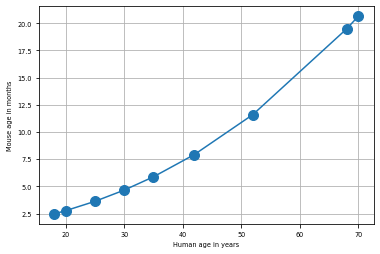

In [3]:
def human2mouse(human_age_in_years):
    x = np.log10(human_age_in_years)
    y = -1.1289 + 0.1667*x - 0.183*np.power(x,2) + 0.1471*np.power(x,3) + 0.121*np.power(x,4) - 0.0068*np.power(x,5) - 0.0127*np.power(x,6)
    mouse_age_in_months = np.power(10,y)*12
    return mouse_age_in_months
X = [18, 20, 25, 30, 35, 42, 52, 68, 70] # human age in years
Y = []
for x in X:
    Y.append(human2mouse(x))
print(np.round(Y)) # mouse age in months
plt.plot(X, Y, '.-', markersize=20)
plt.xlabel('Human age in years')
plt.ylabel('Mouse age in months')
plt.grid('on')

# Figures 1-2 and Supplementary Figures 1-3: Control Subjects Learning

## Run this before Figures 1-2, S1-3 
Load subject database for control experiment

In [4]:
##### Load subject database and comple wild type mice in 4 different age groups that were trained in IBL task

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 3,   ['experiment', 'genotype'], ['Control', 'WT']),
    combine_criteria(4, 5,   ['experiment', 'genotype'], ['Control', 'WT']),
    combine_criteria(5, 8,   ['experiment', 'genotype'], ['Control', 'WT']),
    combine_criteria(19, 22, ['experiment', 'genotype'], ['Control', 'WT']),
] 

control_subjects, control_group_names, ages, sexes, _, = group_subjects(group_criteria, SubjectDB)

Ages = []
for age in ages:
    Ages.append([(np.nanmin(age)), (np.nanmax(age))])
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 3.0]
Age: [4.0, 5.0]
Age: [6.0, 8.0]
Age: [19.0, 21.0]


## Figure 1b
Age and sex distribution of control mice

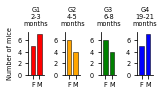

In [5]:
########################################################################
##### Figure 1b ##### 
########################################################################

titles = [f'G1\n2-3\nmonths', f'G2\n4-5\nmonths', f'G3\n6-8\nmonths', f'G4\n19-21\nmonths']
colors = ['red', 'orange', 'green', 'blue']
pvals=[]
set_rcParams()

plt.figure(figsize=np.array([1.8,0.6]))
for group in range(4):
    group_criteria3 = [
        combine_criteria(Ages[group][0], Ages[group][1], ['experiment', 'sex', 'genotype'], ['Control', 'Female', 'WT']),
        combine_criteria(Ages[group][0], Ages[group][1], ['experiment', 'sex', 'genotype'], ['Control', 'Male', 'WT']),
    ] 
    subjects3, group_names3, ages3, sexes3, _, = group_subjects(group_criteria3, SubjectDB)
    axe = plt.axes([0.28*group,0,0.12,1])
    set_plot(axe)
    
    for ai, ages in enumerate(ages3):
        plt.bar(ai, len(ages), facecolor=colors[group], edgecolor='black', linewidth=0.5, width=0.7)
    plt.xlim([-0.7, 1.7])
    plt.xticks([0, 1], labels=['F', 'M'])
    plt.ylim([0, 7.5])
    plt.yticks([0,2,4,6])
    if group==0:
        plt.ylabel('Number of mice')
    plt.title(titles[group], fontsize=6.5)
plt.savefig('Fig1b_AllControlAnimalDistribution.svg')

In [6]:
####################################################################
##### Source data: Figure 1b #####
########################################################################
source_rows = []

titles_clean = [
    "G1 2-3 months",
    "G2 4-5 months",
    "G3 6-8 months",
    "G4 19-21 months"
]

for group in range(4):

    group_criteria3 = [
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Female', 'WT']
        ),
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Male', 'WT']
        ),
    ]

    subjects3, group_names3, ages3, sexes3, _, = group_subjects(
        group_criteria3,
        SubjectDB
    )

    # ages3[0] = females
    # ages3[1] = males
    source_rows.append({
        "Age_group": titles_clean[group],
        "Sex": "Female",
        "Number_of_mice": len(ages3[0])
    })

    source_rows.append({
        "Age_group": titles_clean[group],
        "Sex": "Male",
        "Number_of_mice": len(ages3[1])
    })


fig1b_source = pd.DataFrame(source_rows)

fig1b_source.to_csv(
    "Fig1b_source_data.csv",
    index=False
)

print(fig1b_source)

         Age_group     Sex  Number_of_mice
0    G1 2-3 months  Female               5
1    G1 2-3 months    Male               7
2    G2 4-5 months  Female               6
3    G2 4-5 months    Male               4
4    G3 6-8 months  Female               6
5    G3 6-8 months    Male               4
6  G4 19-21 months  Female               5
7  G4 19-21 months    Male               7


### ITI distribution

In [7]:
#### Compute the ITI distribution in control subjects
all_time_info = np.array(Get_timeInfo(control_subjects, MaxDay=30), dtype=object)

bigmat=[]
ti=1 #0 for session duration, 1 for iti length
for at in all_time_info:
    bigmat = at[:,:,ti] if len(bigmat)==0 else np.concatenate((bigmat, at[:,:,ti]), axis=0)

print('Mean ITI, SD ITI, min ITI, max ITI')
print(np.nanmean(bigmat),np.nanstd(bigmat), np.nanmin(bigmat), np.nanmax(bigmat))

Mean ITI, SD ITI, min ITI, max ITI
4.10747789121021 0.5870485526437839 3.137014869888473 8.811723035230349


## Figure 1c
Learning curves of control mice

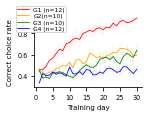

In [8]:
########################################################################
##### Figure 1c ##### 
########################################################################
all_learningCurves = PlotMean(control_subjects, figsize=[12,8], colors=['red','orange','green','blue'], legends=['G1 ','G2','G3 ','G4 '], ylims = [0.3, 0.95], figscale=0.16)
plt.savefig('Fig1c_AllControlLearningCurves.svg')

In [9]:
########################################################################
##### Source data: Figure 1c #####
########################################################################

group_labels = ['G1', 'G2', 'G3', 'G4']

source_rows = []

for gi, (subjects, learning_curves) in enumerate(
        zip(control_subjects, all_learningCurves)):

    for si, subject in enumerate(subjects):

        for day in range(learning_curves.shape[1]):

            value = learning_curves[si, day]

            # Only export sessions for which data exist
            if not np.isnan(value):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Age_group': group_labels[gi],
                    'Training_day': day + 1,
                    'Correct_choice_rate': value
                })

Fig1c_source = pd.DataFrame(source_rows)

Fig1c_source.to_csv(
    'Fig1c_source_data.csv',
    index=False
)

## Figure 1d left
Early-phase performance comparision

Shapiro-Wilk normality tests:
G1: W = 0.960, n = 12, p = 0.779 (normal)
G2: W = 0.879, n = 10, p = 0.127 (normal)
G3: W = 0.908, n = 10, p = 0.269 (normal)
G4: W = 0.961, n = 12, p = 0.800 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 5.781, p = 0.002213

Pairwise comparisons (fdr_bh correction):
G1 vs G2: Welch's t-test, stat = 1.639, n1 = 12, n2 = 10, p = 0.1205, p_adj = 0.1807
G1 vs G3: Welch's t-test, stat = 2.529, n1 = 12, n2 = 10, p = 0.0204, p_adj = 0.04081
G1 vs G4: Welch's t-test, stat = 3.456, n1 = 12, n2 = 12, p = 0.002582, p_adj = 0.01549
G2 vs G3: Welch's t-test, stat = 1.431, n1 = 10, n2 = 10, p = 0.1712, p_adj = 0.2054
G2 vs G4: Welch's t-test, stat = 2.727, n1 = 10, n2 = 12, p = 0.0132, p_adj = 0.03961
G3 vs G4: Welch's t-test, stat = 1.068, n1 = 10, n2 = 12, p = 0.2986, p_adj = 0.2986


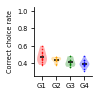

In [10]:
########################################################################
##### Figure 1d left ##### 
########################################################################

colors1=['red', 'orange', 'green', 'blue']
labels=['G1','G2','G3','G4']

set_rcParams()
plt.figure(figsize=np.array([1,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

Frac =[]
for i, subject_list in enumerate(control_subjects): 
    Perf = []
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[:3])
        Perf.append(learning)

    Perf = np.array(Perf)
    Frac.append(Perf)
    plt.plot(i*np.ones(Perf.shape[0]), Perf, '.', color=colors1[i], markersize=1)
    vp = plt.violinplot(Perf, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')

plt.ylabel('Correct choice rate')
plt.xticks(range(len(labels)), labels, fontsize=7)
plt.ylim(0.25, 1.05)
plt.savefig('Fig1dLeft_AllControlEarlyLearning.svg')


groups = {
    "G1": Frac[0],
    "G2": Frac[1],
    "G3": Frac[2],
    "G4": Frac[3]
}

results=postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_fig1dLeft.csv', index=False)

In [11]:
########################################################################
##### Source data: Figure 1d left #####
########################################################################

group_labels = ['G1', 'G2', 'G3', 'G4']

source_rows = []

for gi, (subjects, perf_values) in enumerate(
        zip(control_subjects, Frac)):

    for subject, value in zip(subjects, perf_values):

        if not np.isnan(value):
            source_rows.append({
                'Mouse_ID': subject,
                'Age_group': group_labels[gi],
                'Mean_correct_choice_rate_first_3_sessions': value
            })

Fig1dLeft_source = pd.DataFrame(source_rows)

Fig1dLeft_source.to_csv(
    'Fig1dLeft_source_data.csv',
    index=False
)

## Figure 1d right
Late-phase performance comparision

Shapiro-Wilk normality tests:
Group 1: W = 0.859, n = 12, p = 0.048 (non-normal)
Group 2: W = 0.892, n = 10, p = 0.179 (normal)
Group 3: W = 0.908, n = 10, p = 0.269 (normal)
Group 4: W = 0.864, n = 12, p = 0.054 (normal)

At least one group failed normality.
Using Kruskal-Wallis + pairwise Mann-Whitney U tests.

Kruskal-Wallis H-test: H = 25.118, p = 1.459e-05

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Mann-Whitney U, stat = 107.000, n1 = 12, n2 = 10, p = 0.002162, p_adj = 0.004325
Group 1 vs Group 3: Mann-Whitney U, stat = 118.000, n1 = 12, n2 = 10, p = 0.0001491, p_adj = 0.0004474
Group 1 vs Group 4: Mann-Whitney U, stat = 144.000, n1 = 12, n2 = 12, p = 3.644e-05, p_adj = 0.0002187
Group 2 vs Group 3: Mann-Whitney U, stat = 58.000, n1 = 10, n2 = 10, p = 0.5708, p_adj = 0.5708
Group 2 vs Group 4: Mann-Whitney U, stat = 90.000, n1 = 10, n2 = 12, p = 0.05175, p_adj = 0.07763
Group 3 vs Group 4: Mann-Whitney U, stat = 86.000, n1 = 10, n2 = 12, p = 0.09268, p_adj = 0.

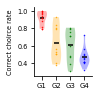

In [12]:
########################################################################
##### Figure 1d right ##### 
########################################################################

colors1=['red', 'orange', 'green', 'blue']
labels=['G1','G2','G3','G4']

set_rcParams()
plt.figure(figsize=np.array([1,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

Frac =[]
for i, subject_list in enumerate(control_subjects): 
    Perf = []
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])
        Perf.append(learning)

    Perf = np.array(Perf)
    Frac.append(Perf)
    plt.plot(i*np.ones(Perf.shape[0]), Perf, '.', color=colors1[i], markersize = 1)
    vp = plt.violinplot(Perf, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')

plt.ylabel('Correct choirce rate')
plt.xticks(range(len(labels)), labels, fontsize=7)
plt.ylim(0.25, 1.05)
plt.savefig('Fig1dRight_AllControlLateLearning.svg')


groups = {
    "Group 1": Frac[0],
    "Group 2": Frac[1],
    "Group 3": Frac[2],
    "Group 4": Frac[3]
}

results=postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_fig1dRight.csv', index=False)

In [13]:
########################################################################
##### Source data: Figure 1d right #####
########################################################################

group_labels = ['G1', 'G2', 'G3', 'G4']

source_rows = []

for gi, (subjects, perf_values) in enumerate(
        zip(control_subjects, Frac)):

    for subject, value in zip(subjects, perf_values):

        if not np.isnan(value):
            source_rows.append({
                'Mouse_ID': subject,
                'Age_group': group_labels[gi],
                'Mean_correct_choice_rate_sessions_26_30': value
            })

Fig1dRight_source = pd.DataFrame(source_rows)

Fig1dRight_source.to_csv(
    'Fig1dRight_source_data.csv',
    index=False
)

## Figure 1e
Learning curves as a function of trial numbers

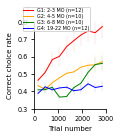

In [14]:
########################################################################
##### Figure 1e ##### 
########################################################################
all_learningCurvesByTrials = PlotMean_trials(control_subjects, colors=['red','orange','green','blue'], legends=['G1: 2-3 MO ','G2: 4-5 MO ','G3: 6-8 MO ','G4: 19-22 MO '], ylims = [0.3, 0.8], figscale=0.16)
plt.savefig('AllControlLearningCurvesTrials.svg')

In [15]:
########################################################################
##### Source data: Figure 1e #####
########################################################################

group_labels = ['G1', 'G2', 'G3', 'G4']

# Same indices actually plotted by PlotMean_trials()
t_inds = np.arange(150, 3000, 300)
trial_numbers = t_inds + 1

source_rows = []

for gi, (subjects, learning_curves) in enumerate(
        zip(control_subjects, all_learningCurvesByTrials)):

    for si, subject in enumerate(subjects):

        for idx, trial_number in zip(t_inds, trial_numbers):

            value = learning_curves[si, idx]

            if not np.isnan(value):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Age_group': group_labels[gi],
                    'Trial_number': trial_number,
                    'Correct_choice_rate': value
                })

Fig1e_source = pd.DataFrame(source_rows)

Fig1e_source.to_csv(
    'Fig1e_source_data.csv',
    index=False
)

## Supplementary Figure 1 Block

## Supplementary Figure 1a
Sex comparision for learning performance

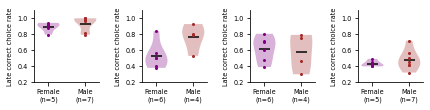

In [16]:
########################################################################
##### Figure S1a #####
########################################################################

source_rows = []

age_group_labels = ['G1', 'G2', 'G3', 'G4']
sex_labels = ['Female', 'Male']

results = []
pvals = []

set_rcParams()
plt.figure(figsize=np.array([6,1]))

for group in range(4):

    group_criteria3 = [
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Female', 'WT']
        ),
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Male', 'WT']
        ),
    ]

    subjects3, group_names3, ages3, sexes3, dates3 = group_subjects(
        group_criteria3,
        SubjectDB
    )

    axe = plt.axes([0.25*group, 0, 0.15, 1])
    set_plot(axe)

    colors1 = ['purple', 'brown']
    labels = ['Female', 'Male']
    place = [0, 1]

    Frac = []
    lb = []

    for i, subject_list in enumerate(subjects3):

        Perf = []

        for subject in subject_list:

            sessions = find_sessions(subject)

            y = FullContrastPerf(sessions)

            learning = np.nanmean(y[25:30])

            Perf.append(learning)

            # Source-data row
            source_rows.append({
                'Mouse_ID': subject,
                'Age_group': age_group_labels[group],
                'Sex': sex_labels[i],
                'Mean_correct_choice_rate_sessions_26_30': learning
            })

        Perf = np.array(Perf)

        Frac.append(Perf)

        plt.plot(
            place[i] * np.ones(Perf.shape[0]),
            Perf,
            '.',
            color=colors1[i],
            alpha=1,
            markersize=4
        )

        vp = plt.violinplot(
            Perf,
            [place[i]],
            showmeans=True,
            showextrema=False,
            widths=0.6
        )

        for pc in vp['bodies']:
            pc.set_facecolor(colors1[i])

        vp['cmeans'].set_color('black')

        lb.append(f'{labels[i]}\n(n={len(Perf)})')

    plt.ylabel('Late correct choice rate', fontsize=6.5)
    plt.xticks(place, lb)
    plt.ylim(0.2, 1.1)

    test = twoSampleTest(
        Frac[0],
        Frac[1],
        label=f'{age_group_labels[group]} Female vs Male',
        group1='Female',
        group2='Male'
    )

    results.append(test)
    pvals.append(test['p'])


plt.savefig('FigS1a_AllControlLateLearningFvM.svg')

In [17]:
# ------------------------------------------------------------
# Save source data
# ------------------------------------------------------------

FigS1a_source = pd.DataFrame(source_rows)

FigS1a_source.to_csv(
    'FigS1a_source_data.csv',
    index=False
)


# ------------------------------------------------------------
# Multiple-comparison correction
# ------------------------------------------------------------

corrected = multipletests(
    pvals,
    method='fdr_bh'
)

corrected_ps = corrected[1]

for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]

df = pd.DataFrame(results)

df.to_csv(
    'statistical_results_figS1a.csv',
    index=False
)

## Supplementary Figure 1b
Sex comparision for early switching

(array([False, False, False, False]), array([0.37994239, 0.61180831, 0.61180831, 0.27728294]), 0.012741455098566168, 0.0125)


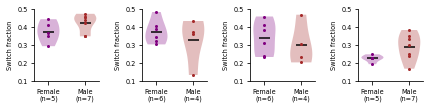

In [18]:
########################################################################
##### Figure S1b ##### 
########################################################################
results=[]
pvals=[]
set_rcParams()
plt.figure(figsize=np.array([6,1]))
for group in range(4):
    group_criteria3 = [
        combine_criteria(Ages[group][0], Ages[group][1], ['experiment', 'sex', 'genotype'], ['Control', 'Female', 'WT']),
        combine_criteria(Ages[group][0], Ages[group][1], ['experiment', 'sex', 'genotype'], ['Control', 'Male', 'WT']),
    ] 
    subjects3, group_names3, ages3, sexes3, dates3 = group_subjects(group_criteria3, SubjectDB)

    axe = plt.axes([0.25*group,0,0.15,1])
    set_plot(axe)

    colors1=['purple', 'brown']
    labels=['Female','Male']
    place = [0, 1]
    Frac =[]
    lb=[]
    for i, subject_list in enumerate(subjects3): 
        fractions = []
        for subject in subject_list:
            sessions = find_sessions(subject)
            fraction, trs = FractionSwitch(sessions[:3], numTR=200)

            fractions.append(fraction)
        fractions = np.array(fractions)
        Frac.append(fractions)
        plt.plot(place[i]*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], alpha = 1, markersize=4)
        vp = plt.violinplot(fractions, [place[i]], showmeans=True, showextrema=False, widths=0.6)
        for pc in vp['bodies']:
            pc.set_facecolor(colors1[i])
        vp['cmeans'].set_color('black')
        lb.append(f'{labels[i]}\n(n={len(fractions)})')

    plt.ylabel('Switch fraction', fontsize=6.5)
    plt.xticks(place, lb)
    plt.ylim(0.1, 0.5)

    test=twoSampleTest(Frac[0], Frac[1])
    results.append(test)
    pvals.append(test['p'])
plt.savefig('FigS1a_AllControlSwitchingFvM.svg')
corrected = multipletests(pvals, method='fdr_bh')
corrected_ps = corrected[1]
print(corrected)

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('statistical_results_figS1a.csv', index=False)

In [19]:
########################################################################
##### Source data: Figure S1b #####
########################################################################

source_rows = []

group_labels = ['G1', 'G2', 'G3', 'G4']
sex_labels = ['Female', 'Male']

for group in range(4):

    group_criteria3 = [
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Female', 'WT']
        ),
        combine_criteria(
            Ages[group][0], Ages[group][1],
            ['experiment', 'sex', 'genotype'],
            ['Control', 'Male', 'WT']
        ),
    ]

    subjects3, group_names3, ages3, sexes3, dates3 = group_subjects(
        group_criteria3,
        SubjectDB
    )

    for i, subject_list in enumerate(subjects3):

        for subject in subject_list:

            sessions = find_sessions(subject)

            fraction, nTrs = FractionSwitch(
                sessions[:3],
                numTR=200
            )

            if np.isfinite(fraction):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Age_group': group_labels[group],
                    'Sex': sex_labels[i],
                    'Trial_window': 200,
                    'Num_trials_used': nTrs,
                    'Switch_fraction': fraction
                })


FigS1b_source = pd.DataFrame(source_rows)

FigS1b_source.to_csv(
    'FigS1b_source_data.csv',
    index=False
)

## Supplementary Figure 1c
Relationsship between early switch fraction and learning performance per age group

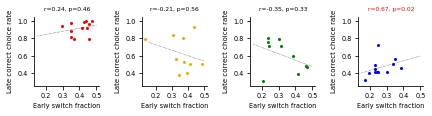

In [20]:
########################################################################
##### Figure S1c #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

set_rcParams()
plt.figure(figsize=np.array([6,0.96]))

colors1 = ['red', 'orange', 'green', 'blue']
sig_color = ['black', 'red']

NT = 200
pvals = []
results = []

for i, subject_list in enumerate(control_subjects):

    axe = plt.axes([0.25*i, 0, 0.15, 1])
    set_plot(axe)

    fractions = []
    Perf = []

    for subject in subject_list:

        sessions = find_sessions(subject)

        # Early switching
        fraction, trs = FractionSwitch(
            sessions[:3],
            numTR=NT
        )

        # Late learning
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])

        fractions.append(fraction)
        Perf.append(learning)

        # Source-data row
        source_rows.append({
            'Mouse_ID': subject,
            'Age_group': group_labels[i],
            'Early_switch_fraction': fraction,
            'Num_trials_used_for_switch_fraction': trs,
            'Late_correct_choice_rate_sessions_26_30': learning
        })

    fractions = np.asarray(fractions, dtype=float)
    Perf = np.asarray(Perf, dtype=float)

    # Remove mice lacking either measurement
    valid = np.isfinite(fractions) & np.isfinite(Perf)

    x = fractions[valid]
    y = Perf[valid]

    # Plot individual mice
    plt.plot(
        x,
        y,
        '.',
        color=colors1[i],
        markersize=4
    )

    # Linear line shown for visualization
    res = stats.linregress(x, y)

    x2 = np.arange(0.15, 0.55, 0.05)

    plt.plot(
        x2,
        res.intercept + res.slope*x2,
        'k:',
        linewidth=0.5
    )

    # Spearman correlation
    test = spearmanTest(
        x,
        y,
        label=f'Fig. S1c {group_labels[i]}',
        random_state=1
    )

    pvals.append(test['p'])
    results.append(test)

    plt.xlabel('Early switch fraction', fontsize=6.5)
    plt.xticks([0.2, 0.3, 0.4, 0.5])
    plt.ylim(0.25, 1.05)
    plt.ylabel('Late correct choice rate', fontsize=7)

    plt.title(
        f"r={test['rho']:1.2f}, p={test['p']:1.2f}",
        color=sig_color[int(test['p'] < 0.05)],
        fontsize=6
    )


########################################################################
##### Multiple-comparison correction #####
########################################################################

corrected = multipletests(
    pvals,
    method='fdr_bh'
)

corrected_ps = corrected[1]

for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]

results_df = pd.DataFrame(results)

results_df.to_csv(
    'posthoc_statistics_figS1c.csv',
    index=False
)

In [21]:
########################################################################
##### Save source data #####
########################################################################

FigS1c_source = pd.DataFrame(source_rows)

FigS1c_source.to_csv(
    'FigS1c_source_data.csv',
    index=False
)

plt.savefig(
    'FigS1c_ExploreLearningCorrPerGroup.svg'
)

<Figure size 432x288 with 0 Axes>

## Supplementary Figure 2
Motor learning curves

Early-phase Reaction time:p=0.001
Early-phase Peak speed:p=0.010
Early-phase Movement correlation:p=0.065
Late-phase Reaction time:p=0.002
Late-phase Peak speed:p=0.684
Late-phase Movement correlation:p=0.282
[0.00118408 0.00172881]
[0.02038621 0.68399063]
[0.13057487 0.281626  ]


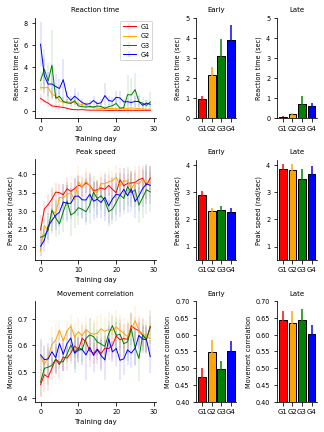

In [22]:
########################################################################
#### Figure S2 ####
########################################################################

import scipy
import matplotlib.gridspec as gridspec
import scipy.stats as stats

set_rcParams()

colors1=['red','orange','green','blue']


mean_lists = np.load(root / 'Kinmean10.npy',allow_pickle=True)[:]
fig = plt.figure(tight_layout=True, figsize=np.array([4.5,6]))
gs = gridspec.GridSpec(len(mean_lists)-1,4)

titles=['Reaction time', 'Peak speed','Movement correlation','Number of bouts']
ylabels=['Reaction time (sec)', 'Peak speed (rad/sec)','Movement correlation','Number of bouts']
for i, mean_list in enumerate(mean_lists[:-1]):
    axe = fig.add_subplot(gs[i, :2])
    set_plot(axe)

    for j, mean_nb in enumerate(mean_list): 
        x = mean_nb
        y = np.nanmean(x,axis=0)[:]
        ye = (np.nanstd(x, axis=0)/np.sqrt(len(mean_list)))[:]
        plt.errorbar(range(len(y)), y, ye, color=colors1[j], linewidth=1, elinewidth=0.2, errorevery=1)
    plt.title(titles[i],fontsize=7)
    plt.ylabel(ylabels[i])
    plt.xlabel('Training day', fontsize=7)

    if i==0:
        plt.legend(['G1','G2','G3','G4'])

pvals1=[]
for i, mean_list in enumerate(mean_lists[:-1]):
    axe = fig.add_subplot(gs[i, 2])
    set_plot(axe)
    
    LRs = []
    for j, mean_nb in enumerate(mean_list): 
        Taus = []
        for k, x in enumerate(mean_nb):
            tau=np.nanmean(x[:3])
            Taus.append(tau)

        LRs.append(Taus)
        plt.bar(j,np.nanmean(Taus), color=colors1[j], edgecolor='black', linewidth=1)
        plt.errorbar(j, np.nanmean(Taus), np.nanstd(Taus)/np.sqrt(len(Taus)),color=colors1[j])
    plt.xticks(range(len(LRs)),labels=['G1','G2','G3','G4'],fontsize=7)
    plt.title('Early', fontsize=7)
    plt.ylabel(ylabels[i])
    if i==0:
        plt.ylim(0,5)
    elif i==1:
        plt.ylim(0.5,4.2)
    elif i==2:
        plt.ylim(0.4,0.7)
    elif i==3:
        plt.ylim(0, 3)
        

    x = LRs[0]
    y = LRs[3]

    test = twoSampleTest(x,y)
    p = test['p']
    pvals1.append(p)
    print(f'Early-phase {titles[i]}:p={p:1.3f}')
    df = pd.DataFrame([test])
    df.to_csv(f'posthoc_statistics_figS2Early{i}.csv', index=False)

pvals2=[]
for i, mean_list in enumerate(mean_lists[:-1]):
    axe = fig.add_subplot(gs[i, 3])
    set_plot(axe)

    
    LRs = []
    for j, mean_nb in enumerate(mean_list): 
        Taus = []
        for k, x in enumerate(mean_nb):
            tau = np.nanmean(x[-3:])
   
            Taus.append(tau)

        LRs.append(Taus)
        plt.bar(j,np.nanmean(Taus), color=colors1[j], edgecolor='black', linewidth=1)
        plt.errorbar(j, np.nanmean(Taus), np.nanstd(Taus)/np.sqrt(len(Taus)),color=colors1[j])
    plt.xticks(range(len(LRs)),labels=['G1','G2','G3','G4'],fontsize=7)
    plt.ylabel(ylabels[i])
    plt.title('Late', fontsize=7)
    if i==0:
        plt.ylim(0,5)
    elif i==1:
        plt.ylim(0.5,4.2)
    elif i==2:
        plt.ylim(0.4, 0.7)
    elif i==3:
        plt.ylim(0, 3)

    x = LRs[0]
    y = LRs[3]

    
    test = twoSampleTest(x,y)
    p = test['p']
    pvals2.append(p)
    print(f'Late-phase {titles[i]}:p={p:1.3f}')
    df = pd.DataFrame([test])
    df.to_csv(f'posthoc_statistics_figS2Late{i}.csv', index=False)

plt.savefig('FigS2_Kinematics.svg')

for i in range(3):
    pvals = [pvals1[i], pvals2[i]]
    corrected = multipletests(pvals, method='fdr_bh')
    print(corrected[1])
    

In [23]:
########################################################################
##### Source data: Figure S2 daily kinematics #####
########################################################################

metric_names = [
    'Reaction_time_sec',
    'Peak_speed_rad_per_sec',
    'Movement_correlation',
    'Number_of_bouts'
]

group_labels = ['G1', 'G2', 'G3', 'G4']

source_rows = []

for mi, mean_list in enumerate(mean_lists):

    for gi, group_data in enumerate(mean_list):

        # group_data: mice x training days
        for si, subject in enumerate(control_subjects[gi]):

            for day, value in enumerate(group_data[si]):

                if np.isfinite(value):
                    source_rows.append({
                        'Mouse_ID': subject,
                        'Age_group': group_labels[gi],
                        'Metric': metric_names[mi],
                        'Training_day': day + 1,
                        'Value': value
                    })

FigS2_daily_source = pd.DataFrame(source_rows)

FigS2_daily_source.to_csv(
    'FigS2_daily_source_data.csv',
    index=False
)

########################################################################
##### Source data: Figure S2 early/late summaries #####
########################################################################

summary_rows = []

for mi, mean_list in enumerate(mean_lists):

    for gi, group_data in enumerate(mean_list):

        for si, subject in enumerate(control_subjects[gi]):

            x = np.asarray(group_data[si], dtype=float)

            early = np.nanmean(x[:3])
            late = np.nanmean(x[-3:])

            summary_rows.append({
                'Mouse_ID': subject,
                'Age_group': group_labels[gi],
                'Metric': metric_names[mi],
                'Early_mean_first_3_sessions': early,
                'Late_mean_last_3_sessions': late
            })

FigS2_summary_source = pd.DataFrame(summary_rows)

FigS2_summary_source.to_csv(
    'FigS2_early_late_source_data.csv',
    index=False
)

# Figure 2 and Supplementary Figure 3: Q-learning and Switch Fraction

### Q-learning simulation

In [24]:
def regenerate_q_learning_simulations():
    """Regenerate the deposited Q-learning arrays (slow; optional)."""
    # Simulated reward function: define some environment logic
    def get_reward(state, action):
        # Define "correct" action per state
        if state == 0 and action == 1:
            return 1
        elif state == 1 and action == 0:
            return 1
        else:
            return 0

    # Environment setup
    num_states = 2
    num_actions = 2

    # Initialize Q-table

    # Hyperparameters
    alpha = 0.1     # learning rate
    gamma = 0     # discount factor
    episodes = 10000

    QlearningCurves = []
    QEarlySwitch = []
    QLateSwitch = []
    for epsilon in [0, 0.0002, 0.0005, 0.0015]:
        # Training loop
        Rewards = []
        switches = []
        Reverse_switches = []
        for rep in range(1000):
            Q = np.zeros((num_states, num_actions))
            rewards = []
            switch = []
            preaction = 0
            for episode in range(episodes):
                # Start at random state
                state = random.choice([0, 1])
                noise = random.gauss(0,1)

                # ε-greedy action selection
                if random.random() < epsilon:
                    action = random.choice([0, 1])
                else:
                    action = np.argmax(Q[state])

                # Get reward
                reward = get_reward(state, action)
                
                switch.append(1) if not(action == preaction) else switch.append(0)
                preaction = action
                rewards.append(reward)

                # No next state since it's a single-step environment, but we'll follow standard Q-learning update
                Q[state, action] += alpha * (reward + gamma * np.max(Q[state]) - Q[state, action])
            switches.append(np.array(np.cumsum(switch)/(np.arange(len(switch))+1)))
            Reverse_switches.append(np.cumsum(np.array(switch)[np.arange(len(switch)-1, -1, -1)])/(np.arange(len(switch))+1))
            Rewards.append(np.array(rewards))
        mRewards = np.nanmean(np.array(Rewards), axis=0)
        mSwitch = np.nanmean(np.array(switches), axis=0)
        sSwitch = np.nanmean(np.array(Reverse_switches), axis=0)

        QlearningCurves.append(mRewards)
        QEarlySwitch.append(mSwitch)
        QLateSwitch.append(sSwitch)
        #plt.plot(np.lib.stride_tricks.sliding_window_view(mRewards,1).mean(axis=-1))

        # Display learned Q-values
        print("Learned Q-table:")
        print(Q)

        # Show policy
        print("\nLearned policy (best action per state):")
        for state in range(num_states):
            print(f"State {state}: Take action {np.argmax(Q[state])}")


    # np.save('QStimulation_rewards.npy', QlearningCurves)
    # np.save('QStimulation_mean_cum_switch.npy', QEarlySwitch)
    # np.save('QStimulation_reverse_mean_cum_switch.npy', QLateSwitch)
    return QlearningCurves, QEarlySwitch, QLateSwitch

# Figure cells below load the deposited simulations from Q_learning/.
# To regenerate them explicitly, run:
# QlearningCurves, QEarlySwitch, QLateSwitch = regenerate_q_learning_simulations()


## Figure 2b
Simulated Q-learning curves

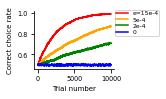

In [25]:
########################################################################
##### Figure 2b ##### 
########################################################################

set_rcParams()

colors = ['red', 'orange', 'green','blue']
epsilon = np.array([0.0015, 0.0005, 0.0002, 0])*1000

QlearningCurves = np.load(Path(Qlearning,'QStimulation_rewards.npy'), allow_pickle=True)
QEarlySwitch = np.load(Path(Qlearning, 'QStimulation_mean_cum_switch.npy'), allow_pickle=True)
QLateSwitch = np.load(Path(Qlearning, 'QStimulation_reverse_mean_cum_switch.npy'), allow_pickle=True)

QlearningCurves = np.array(QlearningCurves)
QEarlySwitch = np.array(QEarlySwitch)
QLateSwitch = np.array(QLateSwitch)

###### Learning curves for different exploration rates
plt.figure(figsize=[3.7,0.8])
ax = plt.axes((0,0,0.3, 1))
set_plot(ax)
for i, r, s in zip (np.arange(len(QlearningCurves)), reversed(QlearningCurves), reversed(QEarlySwitch)):
    plt.plot(np.lib.stride_tricks.sliding_window_view(r,20).mean(axis=-1), color=colors[i])
plt.legend(labels=['e=15e-4', '5e-4', '2e-4', '0'], loc='right', bbox_to_anchor=(1.6, 0.8), borderpad=0.1, labelspacing=0.2, fontsize=6)
plt.xlabel('Trial number', fontsize=7)
plt.ylabel('Correct choice rate', fontsize=7)

plt.savefig('Fig2b_LearningSimul1.svg')

In [26]:
########################################################################
##### Source data: Figure 2b #####
########################################################################

epsilon_values = [15e-4, 5e-4, 2e-4, 0]

source_rows = []

# reversed(QlearningCurves) matches the order used in the figure
for eps, rewards in zip(epsilon_values, reversed(QlearningCurves)):

    rewards = np.asarray(rewards, dtype=float)

    # Same 20-trial moving average used for plotting
    smoothed = np.lib.stride_tricks.sliding_window_view(
        rewards, 20
    ).mean(axis=-1)

    # Each value summarizes the preceding 20 trials
    trial_numbers = np.arange(20, len(rewards) + 1)

    for trial, value in zip(trial_numbers, smoothed):
        source_rows.append({
            'Exploration_rate_epsilon': eps,
            'Trial_number': trial,
            'Correct_choice_rate_20_trial_mean': value
        })

Fig2b_source = pd.DataFrame(source_rows)

Fig2b_source.to_csv(
    'Fig2b_source_data.csv',
    index=False
)

## Figure 2c-d
Simulated early- and late-phase exploration and late-phase exploration versus task performance

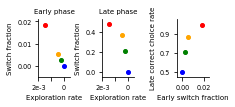

In [27]:
########################################################################
##### Figure 2c-d #####
########################################################################

##### Early Exploration rate VS Early phase switch
set_rcParams()
plt.figure(figsize=[3.7,0.8])
ax = plt.axes((0, 0, 0.12, 1))
set_plot(ax)
for i, ms, ss in zip (range(len(QEarlySwitch)), reversed(QEarlySwitch), reversed(QLateSwitch)):
    plt.plot(epsilon[i], ms[200], '.', markersize=8, color=colors[i])
plt.ylabel('Switch fraction', fontsize=7)
plt.xlabel('Exploration rate', fontsize=7)
plt.xticks(np.arange(0, 2.1, 1), labels=['0','', '2e-3'])
plt.xlim(-0.5, 2)
ax.invert_xaxis()
plt.ylim(-0.005, 0.021)
plt.title('Early phase', fontsize=7)

##### Late Exploration rate VS Late phase switch
ax = plt.axes((0.24, 0, 0.12, 1))
set_plot(ax)
for i, ms, ss in zip (range(len(QEarlySwitch)), reversed(QEarlySwitch), reversed(QLateSwitch)):
    plt.plot(epsilon[i], ss[200], '.', markersize=8, color=colors[i])
plt.ylabel('Switch fraction', fontsize=7)
plt.xlabel('Exploration rate', fontsize=7)
plt.xticks(np.arange(0, 2.1, 1), labels=['0','', '2e-3'])
plt.xlim(-0.5, 2)
ax.invert_xaxis()
plt.ylim(-0.05, 0.53)
plt.title('Late phase', fontsize=7)

##### Early phase switch VS Learning
ax = plt.axes((0.52, 0, 0.12, 1))
set_plot(ax)
for i, r, ms in zip (range(len(QEarlySwitch)), reversed(QlearningCurves), reversed(QEarlySwitch)):
    plt.plot(ms[200], np.mean(r[-500:]), '.', markersize=8, color=colors[i])
plt.ylabel('Late correct choice rate', fontsize=7)
plt.xlabel('Early switch fraction', fontsize=7)
plt.xticks(np.arange(0, 0.025, 0.02))
plt.yticks(np.arange(0.5, 1, 0.2))
plt.xlim(-0.005, 0.025)
plt.ylim(0.45, 1.05)

plt.savefig('Fig2cd_QLearningSimulation.svg')

In [28]:
########################################################################
##### Source data: Figure 2c-d #####
########################################################################

epsilon_values = np.array([15e-4, 5e-4, 2e-4, 0])

source_rows = []

for eps, early_switch, late_switch, rewards in zip(
        epsilon_values,
        reversed(QEarlySwitch),
        reversed(QLateSwitch),
        reversed(QlearningCurves)):

    source_rows.append({
        'Exploration_rate_epsilon': eps,
        'Early_switch_fraction_trial_200': early_switch[200],
        'Late_switch_fraction_trial_200': late_switch[200],
        'Late_correct_choice_rate_mean_last_9000_trials': np.mean(rewards[-9000:])
    })

Fig2cd_source = pd.DataFrame(source_rows)

Fig2cd_source.to_csv(
    'Fig2cd_source_data.csv',
    index=False
)

## Figure 2e & Supplementary Figure 2a
Early exploration comparison of control mice

Shapiro-Wilk normality tests:
Group 1: W = 0.912, n = 12, p = 0.224 (normal)
Group 2: W = 0.897, n = 10, p = 0.202 (normal)
Group 3: W = 0.896, n = 10, p = 0.200 (normal)
Group 4: W = 0.925, n = 12, p = 0.327 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 6.389, p = 0.001219

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Welch's t-test, stat = 1.325, n1 = 12, n2 = 10, p = 0.2059, p_adj = 0.2471
Group 1 vs Group 3: Welch's t-test, stat = 2.129, n1 = 12, n2 = 10, p = 0.05191, p_adj = 0.1038
Group 1 vs Group 4: Welch's t-test, stat = 5.553, n1 = 12, n2 = 12, p = 1.486e-05, p_adj = 8.918e-05
Group 2 vs Group 3: Welch's t-test, stat = 0.704, n1 = 10, n2 = 10, p = 0.4908, p_adj = 0.4908
Group 2 vs Group 4: Welch's t-test, stat = 2.649, n1 = 10, n2 = 12, p = 0.01783, p_adj = 0.0535
Group 3 vs Group 4: Welch's t-test, stat = 1.712, n1 = 10, n2 = 12, p = 0.1075, p_adj = 0.1613


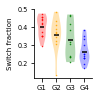

In [29]:
########################################################################
#####  Figure 2e #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

set_rcParams()
plt.figure(figsize=np.array([1,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

colors1 = ['red', 'orange', 'green', 'blue']
labels = ['G1','G2','G3','G4']
NT = 200
Frac = []

for i, subject_list in enumerate(control_subjects):

    fractions = []

    for subject in subject_list:
        sessions = find_sessions(subject)

        fraction, Ntrs = FractionSwitch(
            sessions[:3],
            numTR=NT
        )

        fractions.append(fraction)

        source_rows.append({
            'Mouse_ID': subject,
            'Age_group': group_labels[i],
            'Early_switch_fraction': fraction,
            'Num_trials_used': Ntrs
        })

    fractions = np.asarray(fractions, dtype=float)

    if len(fractions) > 0:
        Frac.append(fractions)

        plt.plot(
            i*np.ones(fractions.shape[0]),
            fractions,
            '.',
            color=colors1[i],
            markersize=1
        )

        vp = plt.violinplot(
            fractions,
            [i],
            showmeans=True,
            showextrema=False,
            widths=0.7
        )

        for pc in vp['bodies']:
            pc.set_facecolor(colors1[i])

        vp['cmeans'].set_color('black')

plt.ylabel('Switch fraction', fontsize=7)
plt.xticks(range(len(labels)), labels, fontsize=7)

plt.savefig('Fig2e_AgeSwitch.svg')

########################################################################
##### Statistics #####
########################################################################

groups = {
    "Group 1": Frac[0],
    "Group 2": Frac[1],
    "Group 3": Frac[2],
    "Group 4": Frac[3]
}

results = postHoc_mutipleComparisons(
    groups,
    method='fdr_bh'
)

results.to_csv(
    'posthoc_statistics_fig2e.csv',
    index=False
)

In [30]:
########################################################################
##### Save source data: Figure 2e #####
########################################################################

Fig2e_source = pd.DataFrame(source_rows)

Fig2e_source.to_csv(
    'Fig2e_source_data.csv',
    index=False
)

## Figure 2f-g
Early exploration versus learning

0.23675502897988995 0.4587667967284501
-0.2121212121212121 0.5563057751029299
-0.34650615989763683 0.3266572580343008
0.6702200632484068 0.01708121778630635
0.37492075055355584 0.01215675741014912 44


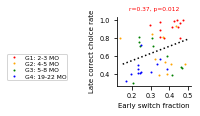

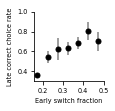

In [31]:
########################################################################
##### Figure 2f #####
########################################################################

set_rcParams()
plt.figure(figsize=np.array([2.6,1.2])*0.8)
axe = plt.axes([0.5,0,0.5,1])
set_plot(axe)

colors1=['red', 'orange', 'green', 'blue']
NT = 200 #Vary this number 100-400 for Supplementary Figure2
Frac = []
PerfMat = []
results2 =[]
pvals=[]
for i, subject_list in enumerate(control_subjects): 
    fractions = np.array([])
    Perf = []
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        fraction, Ntrs = FractionSwitch(sessions[:3], numTR=NT)
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
        
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])
        Perf.append(learning)
    Perf = np.array(Perf)
    if len(Perf)>0:
        ind = np.flatnonzero(~(np.isnan(Perf)))
        xf =fractions
        r,p = stats.spearmanr(xf[ind], Perf[ind])        
        print(r,p)
        if len(Frac)==0:
            Frac = fractions  
            PerfMat = np.array(Perf)
        else:
            Frac = np.concatenate((Frac,fractions))
            PerfMat = np.concatenate((PerfMat,np.array(Perf)))
        x = fractions
        y = Perf
        plt.plot(x, y, '.', color=colors1[i], markersize=2)

ind = np.flatnonzero(~(np.isnan(PerfMat)))
x = Frac[ind]
y = PerfMat[ind]

test = spearmanTest(x, y, label='Fig. 2f', random_state=1)
r = test['rho']
p = test['p']
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_fig2f.csv', index=False)

print(r, p, len(x))
res = stats.linregress(x, y)
x2 = np.arange(0.15, 0.55, 0.05)
plt.plot(x2, res.intercept + res.slope*x2, 'k:', label='fitted line')

plt.xlabel('Early switch fraction', fontsize=7)
plt.xticks([0.2, 0.3, 0.4, 0.5])
plt.ylabel('Late correct choice rate', fontsize=7)
plt.title(f'r={r:1.2f}, p={p:1.3f}', color='r', fontsize=6)
plt.legend(['G1: 2-3 MO', 'G2: 4-5 MO', 'G3: 5-8 MO', 'G4: 19-22 MO'], loc='upper left', bbox_to_anchor=(-1.5, 0.5), borderpad=0.1, labelspacing=0.2, fontsize=6)
plt.savefig(f'Fig2f_ExploreLearningCorr.svg')


########################################################################
##### Figure 2g #####
##### Mean early exploration versus learning
########################################################################

set_rcParams()

plt.figure(figsize=np.array([1.2,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

step=0.05
offset=0.15

for i in range(12):
    ind = np.flatnonzero((Frac>=i*step+offset)*(Frac<i*step+step+offset))
    if len(ind)>1:
        plt.plot(i*step+step/2+offset, np.nanmean(PerfMat[ind]), '.', color='black', markersize=10)
        plt.errorbar(i*step+step/2+offset, np.nanmean(PerfMat[ind]), np.nanstd(PerfMat[ind])/np.sqrt(len(ind)), color='gray')
plt.xlabel('Early switch fraction')
plt.xticks([0.2, 0.3, 0.4, 0.5])
plt.yticks([0.4, 0.6, 0.8, 1.0])
plt.ylabel('Late correct choice rate')
#plt.title(f'r={r:1.2f}, p<{p:1.3f}', color='r', fontsize=7)
#plt.grid()
plt.savefig('Fig2g_ExploreLearningCorr2.svg')

In [32]:
########################################################################
##### Source data: Figure 2f-g #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

Frac = []
PerfMat = []

for i, subject_list in enumerate(control_subjects):

    fractions = []
    Perf = []

    for subject in subject_list:

        sessions = find_sessions(subject)

        # Early switching
        fraction, Ntrs = FractionSwitch(
            sessions[:3],
            numTR=NT
        )

        # Late learning
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])

        fractions.append(fraction)
        Perf.append(learning)

        source_rows.append({
            'Mouse_ID': subject,
            'Age_group': group_labels[i],
            'Early_switch_fraction': fraction,
            'Num_trials_used': Ntrs,
            'Late_correct_choice_rate_sessions_26_30': learning
        })

    fractions = np.asarray(fractions, dtype=float)
    Perf = np.asarray(Perf, dtype=float)

    if i == 0:
        Frac = fractions
        PerfMat = Perf
    else:
        Frac = np.concatenate((Frac, fractions))
        PerfMat = np.concatenate((PerfMat, Perf))


Fig2fg_source = pd.DataFrame(source_rows)

Fig2fg_source.to_csv(
    'Fig2fg_source_data.csv',
    index=False
)

########################################################################
##### Source data: Figure 2g binned summary #####
########################################################################

step = 0.05
offset = 0.15

bin_rows = []

for i in range(12):

    lower = i * step + offset
    upper = lower + step

    ind = np.flatnonzero(
        (Frac >= lower) &
        (Frac < upper)
    )

    if len(ind) > 1:

        values = PerfMat[ind]

        bin_rows.append({
            'Switch_fraction_bin_lower': lower,
            'Switch_fraction_bin_upper': upper,
            'Switch_fraction_bin_center': lower + step / 2,
            'n_mice': np.sum(np.isfinite(values)),
            'Mean_late_correct_choice_rate': np.nanmean(values),
            'SEM_late_correct_choice_rate':
                np.nanstd(values) / np.sqrt(np.sum(np.isfinite(values)))
        })


Fig2g_binned_source = pd.DataFrame(bin_rows)

Fig2g_binned_source.to_csv(
    'Fig2g_binned_source_data.csv',
    index=False
)

## Figure 2h
Early exploration versus learning in the oldest mice

0.6702200632484068 0.01708121778630635
0.6702200632484068 0.01708121778630635 12


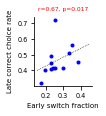

In [33]:
########################################################################
##### Figure 2h #####
########################################################################

set_rcParams()
plt.figure(figsize=np.array([1,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

colors1=['red', 'orange', 'green', 'blue']
NT = 200
Frac = []
PerfMat = []
for i, subject_list in enumerate(control_subjects): 
    fractions = np.array([])
    Perf = []
    if i==3:
        for subject in subject_list:
            sessions = find_sessions(subject)

            fraction, nTrs = FractionSwitch(sessions[:3], numTR=NT)
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction

            y = FullContrastPerf(sessions)
            learning = np.nanmean(y[25:30])
            Perf.append(learning)
        Perf = np.array(Perf)
        if len(Perf)>0:
            ind = np.flatnonzero(~(np.isnan(Perf)))
            xf =fractions
            r,p = stats.spearmanr(xf[ind], Perf[ind])        
            print(r,p)
            if len(Frac)==0:
                Frac = fractions  
                PerfMat = np.array(Perf)
            else:
                Frac = np.concatenate((Frac,fractions))
                PerfMat = np.concatenate((PerfMat,np.array(Perf)))
            x = fractions
            y = Perf
            plt.plot(x, y, '.', color=colors1[i])
                    
ind = np.flatnonzero(~(np.isnan(PerfMat)))
x = Frac[ind]
y = PerfMat[ind]
r,p = stats.spearmanr(x, y)
print(r, p, len(x))
res = stats.linregress(x, y)
x2 = np.arange(0.15, 0.46, 0.05)
plt.plot(x2, res.intercept + res.slope*x2, 'k:', label='fitted line', linewidth=0.7)

plt.xlabel('Early switch fraction', fontsize=7)
plt.xticks([0.2, 0.3, 0.4])
plt.ylabel('Late correct choice rate', fontsize=7)
plt.title(f'r={r:1.2f}, p={p:1.3f}', color='r', fontsize=6)
plt.savefig('Fig2hExploreLearningCorr_old.svg')

In [34]:
########################################################################
##### Source data: Figure 2h #####
########################################################################

source_rows = []

subject_list = control_subjects[3]   # G4 only

for subject in subject_list:

    sessions = find_sessions(subject)

    fraction, nTrs = FractionSwitch(
        sessions[:3],
        numTR=NT
    )

    y = FullContrastPerf(sessions)
    learning = np.nanmean(y[25:30])

    source_rows.append({
        'Mouse_ID': subject,
        'Age_group': 'G4',
        'Early_switch_fraction': fraction,
        'Num_trials_used': nTrs,
        'Late_correct_choice_rate_sessions_26_30': learning
    })

Fig2h_source = pd.DataFrame(source_rows)

Fig2h_source.to_csv(
    'Fig2h_source_data.csv',
    index=False
)

## Supplementary Figure 3a
Early switch fraction for different trial numbers

Shapiro-Wilk normality tests:
Group 1: W = 0.884, n = 12, p = 0.098 (normal)
Group 2: W = 0.780, n = 10, p = 0.008 (non-normal)
Group 3: W = 0.972, n = 10, p = 0.907 (normal)
Group 4: W = 0.893, n = 12, p = 0.128 (normal)

At least one group failed normality.
Using Kruskal-Wallis + pairwise Mann-Whitney U tests.

Kruskal-Wallis H-test: H = 12.164, p = 0.006842

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Mann-Whitney U, stat = 72.000, n1 = 12, n2 = 10, p = 0.4457, p_adj = 0.4457
Group 1 vs Group 3: Mann-Whitney U, stat = 86.500, n1 = 12, n2 = 10, p = 0.08521, p_adj = 0.1704
Group 1 vs Group 4: Mann-Whitney U, stat = 126.500, n1 = 12, n2 = 12, p = 0.001736, p_adj = 0.01042
Group 2 vs Group 3: Mann-Whitney U, stat = 67.000, n1 = 10, n2 = 10, p = 0.2095, p_adj = 0.2514
Group 2 vs Group 4: Mann-Whitney U, stat = 96.000, n1 = 10, n2 = 12, p = 0.01884, p_adj = 0.05651
Group 3 vs Group 4: Mann-Whitney U, stat = 82.500, n1 = 10, n2 = 12, p = 0.1459, p_adj = 0.2188
Shapiro-Wil

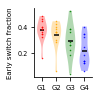

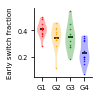

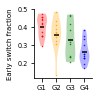

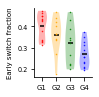

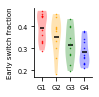

In [35]:
########################################################################
##### Figure S3a #####
########################################################################
set_rcParams()
colors1=['red', 'orange', 'green', 'blue']
labels=['G1','G2','G3','G4']
for NT in [50, 100, 200, 300, 400]: #Vary this number 50-400 for Supplementary Figure3a
    plt.figure(figsize=np.array([1,1.2])*0.8)
    axe = plt.axes([0,0,1,1])
    set_plot(axe)

    Frac =[]
    for i, subject_list in enumerate(control_subjects): 
        fractions = np.array([])
        for subject in subject_list:
            sessions = find_sessions(subject)
            fraction, Ntrs = FractionSwitch(sessions[:3], numTR=NT)

            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction

        if len(fractions)>0:
            Frac.append(fractions)
            plt.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=1)
            vp = plt.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)

            for pc in vp['bodies']:
                pc.set_facecolor(colors1[i])
            vp['cmeans'].set_color('black')
    plt.ylabel('Early switch fraction', fontsize=7)
    plt.xticks(range(len(labels)), labels, fontsize=7)
    plt.savefig(f'FigS3aNT{NT}_AgeSwitch.svg')

    groups = {
        "Group 1": Frac[0],
        "Group 2": Frac[1],
        "Group 3": Frac[2],
        "Group 4": Frac[3]
    }
    results=postHoc_mutipleComparisons(groups, method='fdr_bh')
    results.to_csv(f'posthoc_statistics_figS3aNT{NT}.csv', index=False)
    

In [36]:
########################################################################
##### Source data: Figure S3a #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

for NT in [50, 100, 200, 300, 400]:

    for i, subject_list in enumerate(control_subjects):

        for subject in subject_list:

            sessions = find_sessions(subject)

            fraction, Ntrs = FractionSwitch(
                sessions[:3],
                numTR=NT
            )

            source_rows.append({
                'Mouse_ID': subject,
                'Age_group': group_labels[i],
                'Trial_window': NT,
                'Early_switch_fraction': fraction,
                'Num_trials_used': Ntrs
            })


FigS3a_source = pd.DataFrame(source_rows)

FigS3a_source.to_csv(
    'FigS3a_source_data.csv',
    index=False
)

## Supplementary Figure 3b
Early switch vs Late learning for different trial numbers

0.2708429928270339 0.07536250869654648 44
0.36037144225130113 0.016262342105219898 44
0.37492075055355584 0.01215675741014912 44
0.3355536792348198 0.025965026242629828 44
0.29813555603378245 0.04934117124255141 44
[0.07536251 0.04065586 0.04065586 0.04327504 0.06167646]


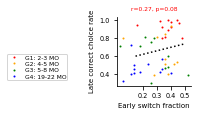

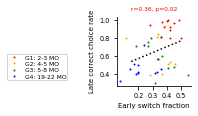

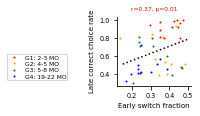

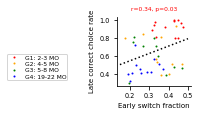

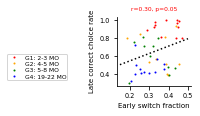

In [37]:
########################################################################
##### Figure S3b #####
########################################################################

set_rcParams()
colors1=['red', 'orange', 'green', 'blue']
results=[]
pvals=[]
for NT in [50, 100, 200, 300, 400]: #Vary this number 100-400 for Supplementary Figure2
    plt.figure(figsize=np.array([2.6,1.2])*0.8)
    axe = plt.axes([0.5,0,0.5,1])
    set_plot(axe)

    Frac = []
    PerfMat = []
    for i, subject_list in enumerate(control_subjects): 
        fractions = np.array([])
        Perf = []
        for subject in subject_list:
            sessions = find_sessions(subject)

            fraction, nTrs = FractionSwitch(sessions[:3], numTR=NT)
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction

            y = FullContrastPerf(sessions)
            learning = np.nanmean(y[25:30])
            Perf.append(learning)
        Perf = np.array(Perf)
        if len(Perf)>0:
            ind = np.flatnonzero(~(np.isnan(Perf)))
            xf =fractions
            if len(Frac)==0:
                Frac = fractions  
                PerfMat = np.array(Perf)
            else:
                Frac = np.concatenate((Frac,fractions))
                PerfMat = np.concatenate((PerfMat,np.array(Perf)))
            x = fractions
            y = Perf
            plt.plot(x, y, '.', color=colors1[i], markersize=2)

    ind = np.flatnonzero(~(np.isnan(PerfMat)))
    x = Frac[ind]
    y = PerfMat[ind]

    test = spearmanTest(x, y, label='Fig. S2b', random_state=1)
    r = test['rho']
    p = test['p']
    pvals.append(p)
    results.append(test) 

    print(r, p, len(x))
    res = stats.linregress(x, y)
    x2 = np.arange(0.15, 0.55, 0.05)
    plt.plot(x2, res.intercept + res.slope*x2, 'k:', label='fitted line')

    plt.xlabel('Early switch fraction', fontsize=7)
    plt.xticks([0.2, 0.3, 0.4, 0.5])
    plt.ylabel('Late correct choice rate', fontsize=7)
    plt.title(f'r={r:1.2f}, p={p:1.2f}', color='r', fontsize=6)
    plt.legend(['G1: 2-3 MO', 'G2: 4-5 MO', 'G3: 5-8 MO', 'G4: 19-22 MO'], loc='upper left', bbox_to_anchor=(-1.5, 0.5), borderpad=0.1, labelspacing=0.2, fontsize=6)
    plt.savefig(f'FigS3b_ExploreLearningCorr{NT}.svg')
    
corrected = multipletests(pvals, method='fdr_bh')
corrected_ps = corrected[1]
print(corrected_ps)

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]
    results2.append(res)
df = pd.DataFrame(results2)

df.to_csv(f'posthoc_statistics_figS3b.csv', index=False)

In [38]:
########################################################################
##### Source data: Figure S3b #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

for NT in [50, 100, 200, 300, 400]:

    for i, subject_list in enumerate(control_subjects):

        for subject in subject_list:

            sessions = find_sessions(subject)

            fraction, nTrs = FractionSwitch(
                sessions[:3],
                numTR=NT
            )

            y = FullContrastPerf(sessions)
            learning = np.nanmean(y[25:30])

            source_rows.append({
                'Mouse_ID': subject,
                'Age_group': group_labels[i],
                'Trial_window': NT,
                'Num_trials_used': nTrs,
                'Early_switch_fraction': fraction,
                'Late_correct_choice_rate_sessions_26_30': learning
            })


FigS3b_source = pd.DataFrame(source_rows)

FigS3b_source.to_csv(
    'FigS3b_source_data.csv',
    index=False
)

## Supplementary Figure 3c
The GLM schema

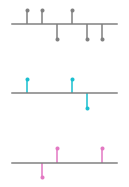

In [39]:
########################################################################
##### Figure S3c #####
########################################################################
set_rcParams()
plt.figure(figsize=[1.6, 3.2])

bigMat = [
    [np.nan, np.nan, -1,  1, np.nan,  np.nan, 1, np.nan],
    [np.nan, 1,  np.nan,  np.nan, 1, -1, np.nan, np.nan],
    [np.nan, 1, 1, -1, 1 ,-1, -1, np.nan],
]
yl = [f'/Unrewarded\nchoice', f'Rewarded\nchoice',  'Stimulus', ]
lmt = ['C6', 'C9', 'C7']
for i in range(3):
    ax = plt.axes([0, 0.3*i, 1, 0.15])
    set_plot(ax)
    y = bigMat[i]
    x = np.arange(len(y))
    plt.stem(x, y, linefmt= lmt[i], markerfmt = '.'+ lmt[i], basefmt = 'grey')
    plt.ylim(-1.2, 1.2)
    ax.set_axis_off()

plt.savefig('GLMdemo.svg')    

## Supplementary Figure 3d top
GLM-fit exploration comparison of control mice

Shapiro-Wilk normality tests:
Group 1: W = 0.931, n = 12, p = 0.386 (normal)
Group 2: W = 0.868, n = 10, p = 0.096 (normal)
Group 3: W = 0.955, n = 10, p = 0.732 (normal)
Group 4: W = 0.903, n = 12, p = 0.173 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 3.982, p = 0.01424

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Welch's t-test, stat = 0.707, n1 = 12, n2 = 10, p = 0.4922, p_adj = 0.5906
Group 1 vs Group 3: Welch's t-test, stat = 1.319, n1 = 12, n2 = 10, p = 0.2062, p_adj = 0.3093
Group 1 vs Group 4: Welch's t-test, stat = 4.596, n1 = 12, n2 = 12, p = 0.0001417, p_adj = 0.0008502
Group 2 vs Group 3: Welch's t-test, stat = 0.309, n1 = 10, n2 = 10, p = 0.7609, p_adj = 0.7609
Group 2 vs Group 4: Welch's t-test, stat = 2.046, n1 = 10, n2 = 12, p = 0.06212, p_adj = 0.1242
Group 3 vs Group 4: Welch's t-test, stat = 2.129, n1 = 10, n2 = 12, p = 0.04999, p_adj = 0.1242


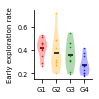

In [40]:
########################################################################
##### Figure S3d top  #####
########################################################################

set_rcParams()
plt.figure(figsize=np.array([1,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

labels =['G1','G2','G3','G4']
colors1=['red', 'orange', 'green', 'blue']
Frac = []
PerfMat = []

key = "IBL_Fit3"

for i, subject_list in enumerate(control_subjects): 
    fractions = np.array([])
    Perf = []
    for subject in subject_list:
        sub_i = np.flatnonzero(SubjectDB['Mouse ID']==subject)[0]
        FITs = SubjectDB[key][sub_i]
        fraction = np.array([])
        for FIT in FITs[:1]:
            Parameters = FIT['Parameters'] 
            if 'IBL' in key:
                a = (Parameters[1] + Parameters[2])
                Switch = 1/(1+np.exp(a))
        fraction = Switch 
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    plt.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=1)
    vp = plt.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)

    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')

plt.ylabel('Early exploration rate', fontsize=7)
plt.xticks(range(len(labels)), labels, fontsize=7)
plt.savefig('FigS3dAgeSwitch_'+ key + '.svg')

groups = {
    "Group 1": Frac[0],
    "Group 2": Frac[1],
    "Group 3": Frac[2],
    "Group 4": Frac[3]
}
results=postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figS3d.csv', index=False)

In [41]:
########################################################################
##### Source data: Figure S3d top #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

key = 'IBL_Fit3'

for i, subject_list in enumerate(control_subjects):

    for subject in subject_list:

        sub_i = np.flatnonzero(
            SubjectDB['Mouse ID'] == subject
        )[0]

        FITs = SubjectDB[key][sub_i]

        # First fitted 3-session block
        FIT = FITs[0]

        Parameters = FIT['Parameters']

        rewarded_weight = Parameters[1]
        unrewarded_weight = Parameters[2]

        exploration_rate = (
            1 / (1 + np.exp(
                rewarded_weight + unrewarded_weight
            ))
        )

        source_rows.append({
            'Mouse_ID': subject,
            'Age_group': group_labels[i],
            'Rewarded_choice_weight': rewarded_weight,
            'Unrewarded_choice_weight': unrewarded_weight,
            'Early_exploration_rate': exploration_rate
        })


FigS3dTop_source = pd.DataFrame(source_rows)

FigS3dTop_source.to_csv(
    'FigS3dTop_source_data.csv',
    index=False
)

## Supplementary Figure 3d bottom
GLM-fit exploration versus learning

0.22767110220996253 0.47667582439849854
-0.01818181818181818 0.9602404181286243
-0.28484848484848485 0.42503815489214547
0.2377622377622378 0.4568008526399232
0.36146446338378796 0.015917687325556637


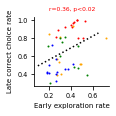

In [42]:
########################################################################
##### Figure S3d bottom #####
########################################################################
set_rcParams()
plt.figure(figsize=np.array([2.6,1.2])*0.8)
axe = plt.axes([0.5,0,0.5,1])
set_plot(axe)

labels =['G1','G2','G3','G4']
colors1=['red', 'orange', 'green', 'blue']
Frac = []
PerfMat = []

key = 'IBL_Fit3'

for i, subject_list in enumerate(control_subjects): 
    fractions = np.array([])
    Perf = []
    for subject in subject_list:
        sub_i = np.flatnonzero(SubjectDB['Mouse ID']==subject)[0]
        FITs = SubjectDB[key][sub_i]
        fraction = np.array([])
        for FIT in FITs[:1]:
            Parameters = FIT['Parameters'] 
            if 'IBL' in key:
                a = (Parameters[1] + Parameters[2])
                Switch = 1/(1+np.exp(a))
        fraction = Switch 
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
        
        sessions = find_sessions(subject)
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])
        Perf.append(learning)
   
    Perf = np.array(Perf)
    ind = np.flatnonzero(~(np.isnan(Perf)))
    xf =fractions
    #r,p = stats.spearmanr(xf[ind], Perf[ind])
    x=xf[ind]
    y=Perf[ind]
    test = spearmanTest(x, y, label='Fig. Sd3dB', random_state=1)
    r = test['rho']
    p = test['p']
    
    print(r,p)
    if len(Frac)==0:
        Frac = fractions  
        PerfMat = np.array(Perf)
    else:
        Frac = np.concatenate((Frac,fractions))
        PerfMat = np.concatenate((PerfMat,np.array(Perf)))
    #print(np.nanmedian(fractions, axis=0))
    x = fractions
    y = Perf
    plt.plot(x, y, '.', color=colors1[i], markersize=2)

ind = np.flatnonzero(~(np.isnan(PerfMat)))
x = Frac[ind]
y = PerfMat[ind]
#r,p = stats.spearmanr(x, y)

test = spearmanTest(x, y, label='Fig. S3d', random_state=1)
r = test['rho']
p = test['p']
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_figS3dBottom.csv', index=False)
    
print(r,p)
res = stats.linregress(x, y)
x2 = np.arange(0.1, 0.7, 0.05)
plt.plot(x2, res.intercept + res.slope*x2, 'k:', label='fitted line')
plt.xlabel('Early exploration rate', fontsize=7)
plt.xticks([0.2, 0.4, 0.6])
plt.ylabel('Late correct choice rate', fontsize=7)
plt.title(f'r={r:1.2f}, p<{p:1.2f}', color='r', fontsize=6)
plt.savefig('FigS3dBottomExploreLearningCorr_' + key +'.svg')

In [43]:
########################################################################
##### Source data: Figure S3d bottom #####
########################################################################

source_rows = []
group_labels = ['G1', 'G2', 'G3', 'G4']

key = 'IBL_Fit3'

for i, subject_list in enumerate(control_subjects):

    for subject in subject_list:

        sub_i = np.flatnonzero(
            SubjectDB['Mouse ID'] == subject
        )[0]

        FITs = SubjectDB[key][sub_i]

        # First fitted 3-session block
        FIT = FITs[0]
        Parameters = FIT['Parameters']

        rewarded_weight = Parameters[1]
        unrewarded_weight = Parameters[2]

        exploration_rate = (
            1 / (1 + np.exp(
                rewarded_weight + unrewarded_weight
            ))
        )

        # Late learning
        sessions = find_sessions(subject)
        y = FullContrastPerf(sessions)
        learning = np.nanmean(y[25:30])

        source_rows.append({
            'Mouse_ID': subject,
            'Age_group': group_labels[i],
            'Rewarded_choice_weight': rewarded_weight,
            'Unrewarded_choice_weight': unrewarded_weight,
            'Early_exploration_rate': exploration_rate,
            'Late_correct_choice_rate_sessions_26_30': learning
        })


FigS3dBottom_source = pd.DataFrame(source_rows)

FigS3dBottom_source.to_csv(
    'FigS3dBottom_source_data.csv',
    index=False
)

## Figure 3: GCaMP6s Imaging Experiment

## Run this before Figure 3
Load subject database for GCaMP6s imaging experiment

In [44]:
##### Load subject database and compile mice in GCaMP6S imaging experiment

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 4,   ['experiment'], ['GC']),
    combine_criteria(15, 24, ['experiment'], ['GC']),
] 
GC_subjects, GC_group_names, GC_ages, GC_sexes, GC_dates = group_subjects(group_criteria, SubjectDB)

Ages =[]
for age in GC_ages:
    Ages.append([np.round(np.nanmin(age)), np.round(np.nanmax(age))])
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 4.0]
Age: [17.0, 20.0]


## Figure 3c
Swtich versus stay trial activity of an example mouse

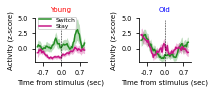

In [45]:
########################################################################
##### Figure 3c #####
########################################################################

set_rcParams()

Young = {
    'Subjects': ['Mouse047'],
    'Dates': ['day1']
}

Old = {
    'Subjects': ['Mouse053'],
    'Dates': ['day1']
}

colors = ['forestgreen', 'mediumvioletred']
colors2 = ['red', 'blue']
titles = ['Young', 'Old']
condition_labels = ['Switch', 'Stay']

fr = 30
offset_time = 1
total_time = 2
sw_time = 0.2

wl = int(total_time * fr)
off = int(offset_time * fr)
sw = int(sw_time * fr)

# Source-data containers
summary_rows = []
trial_rows = []

plt.figure(figsize=np.array([2.4, 2.8]))

for gi, group in enumerate([Young, Old]):

    Subjects = group['Subjects']
    Dates = group['Dates']

    for subject, date in zip(Subjects, Dates):

        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)

        # ------------------------------------------------------------
        # Define switch and stay trials
        # ------------------------------------------------------------
        choices = trial_data['choice']
        pre_choices = np.hstack(([0], choices[:-1]))

        trials_list = np.empty(2, dtype=object)

        # Switch trials
        trials_list[0] = np.flatnonzero(
            choices * pre_choices < 0
        )

        # Stay trials
        trials_list[1] = np.flatnonzero(
            choices * pre_choices > 0
        )

        # ------------------------------------------------------------
        # Select example neuron
        # ------------------------------------------------------------
        cells = np.flatnonzero(
            (neural_data['iscell'][:, 0]) *
            (neural_data['iscell'][:, 1] > 0)
        )

        # Preserve the exact example-cell selection used in the figure
        which_cells = [cells[23], 28]
        example_cell = which_cells[gi]

        # ------------------------------------------------------------
        # Align neuronal activity to stimulus onset
        # ------------------------------------------------------------
        smooth_signal, zsmooth_signal, zNS = align_cell(
            example_cell,
            trial_data,
            neural_data,
            FrameNum,
            TrialNum,
            align_to='stimOn',
            window_length=wl,
            smooth_window=sw,
            offset=off,
            FrameRate=fr
        )

        # ------------------------------------------------------------
        # Z-score using the same normalization as the original code
        # ------------------------------------------------------------
        mtrace = []

        for j in range(2):
            mtrace.append(
                np.nanmean(
                    smooth_signal[trials_list[j], :],
                    axis=0
                )
            )

        mtrace = np.array(mtrace)

        zsmooth_signal = (
            smooth_signal - np.nanmean(mtrace)
        ) / np.nanstd(mtrace)

        # Time axis
        time = (
            np.arange(smooth_signal.shape[1]) - off
        ) / fr + (sw - 1) / 2 / fr

        # ------------------------------------------------------------
        # Plot
        # ------------------------------------------------------------
        axe = plt.axes([
            0.6 * gi,
            0.6,
            0.3,
            0.22
        ])

        set_plot(axe)

        for j in range(2):

            trial_indices = trials_list[j]

            means = np.nanmean(
                zsmooth_signal[trial_indices, :],
                axis=0
            )

            ses = (
                np.nanstd(
                    zsmooth_signal[trial_indices, :],
                    axis=0
                )
                / np.sqrt(len(trial_indices))
            )

            plt.fill_between(
                time,
                means + ses,
                means - ses,
                color=colors[j],
                alpha=0.3,
                linewidth=0
            )

            plt.plot(
                time,
                means,
                color=colors[j]
            )

            # --------------------------------------------------------
            # Save plotted summary data
            # --------------------------------------------------------
            for t, mean_value, sem_value in zip(
                    time, means, ses):

                summary_rows.append({
                    'Mouse_ID': subject,
                    'Age_group': titles[gi],
                    'ROI_index': example_cell,
                    'Condition': condition_labels[j],
                    'Time_from_stimulus_sec': t,
                    'Mean_activity_zscore': mean_value,
                    'SEM_activity_zscore': sem_value
                })

            # --------------------------------------------------------
            # Save individual trial traces
            # --------------------------------------------------------
            for trial in trial_indices:

                trace = zsmooth_signal[trial, :]

                for t, value in zip(time, trace):

                    trial_rows.append({
                        'Mouse_ID': subject,
                        'Age_group': titles[gi],
                        'ROI_index': example_cell,
                        'Condition': condition_labels[j],
                        'Trial_number': int(trial),
                        'Time_from_stimulus_sec': t,
                        'Activity_zscore': value
                    })

        # ------------------------------------------------------------
        # Plot formatting
        # ------------------------------------------------------------
        plt.axvline(
            0,
            -0.15,
            0.95,
            color='black',
            linestyle='--',
            linewidth=0.5
        )

        plt.ylim(-2.2, 5)

        plt.ylabel(
            'Activity (z-score)',
            fontsize=7
        )

        plt.xlabel(
            'Time from stimulus (sec)',
            fontsize=7
        )

        plt.xticks(
            [-0.7, 0, 0.7],
            labels=[
                f'{t:1.1f}'
                for t in [-0.7, 0, 0.7]
            ]
        )

        if gi == 0:
            plt.legend(
                ['Switch', 'Stay'],
                loc='upper left',
                bbox_to_anchor=(0, 1.1),
                fontsize=6,
                borderpad=0.1,
                labelspacing=0.2
            )

        plt.title(
            titles[gi],
            color=colors2[gi],
            fontsize=7
        )


########################################################################
##### Save figure #####
########################################################################

plt.savefig(
    'Fig3c_ExampleNeurons.svg'
)

In [46]:
########################################################################
##### Save source data #####
########################################################################

Fig3c_summary_source = pd.DataFrame(summary_rows)

Fig3c_summary_source.to_csv(
    'Fig3c_summary_source_data.csv',
    index=False
)


Fig3c_trial_source = pd.DataFrame(trial_rows)

Fig3c_trial_source.to_csv(
    'Fig3c_trial_source_data.csv',
    index=False
)

## Run this first before Figure 3d, e, f, g, h, i, j, k

In [47]:
##### Run this first for Figure 3d, e, f, g, h, i, j, k
fr=30
offset_time = 7
total_time = 11
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/2/fr

AllCells=[]
MeanSig=np.array([])
FSwitch = []
for group in range(2): 
    Wsw = []
    allCells = []
    for subject in GC_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
       
        trials_list = []
        choices = trial_data['choice']
        pre_choices = np.hstack(([0], choices[:-1]))
        for ci in range(2):
            if ci == 0:
                trials = np.flatnonzero(choices*pre_choices<0)
            elif ci == 1:
                trials = np.flatnonzero(choices*pre_choices>0)
            trials_list.append(trials)        
        
        trials_list = np.array(trials_list, dtype=object)
        cells = np.flatnonzero(neural_data['iscell'][:,0])
      
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  window_length = wl, smooth_window=sw, offset = off, 
                                                                trials_list = trials_list, FrameRate = fr, zScore=0, plot=False)   
        zsignal = np.full_like(signal, np.nan)
        for ci in range(len(cells)):
            my = np.nanmean(signal[:, ci, :])
            sy = np.nanstd(signal[:,ci,:])
            zsignal[:, ci,: ] = (signal[:, ci, :] - my)/sy
            
        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr

        tind = np.flatnonzero((time>=-0.45)*(time<=-0.15))
       
        MeanSig = np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1) if len(MeanSig)==0 else np.vstack((MeanSig,np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1)))
        sig = np.nanmean(zsignal[0][:,tind]-zsignal[1][:,tind], axis=-1)
        FSwitch.append(len(np.flatnonzero(sig>0.5))/(sig.shape[0]))
        allCells = zsignal if len(allCells)==0 else np.concatenate((allCells,zsignal), axis=1)
    AllCells.append(allCells)
FSwitch = np.array(FSwitch)

## Figure 3d
Swtich versus stay trial population activity

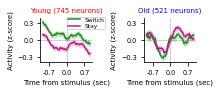

In [48]:
########################################################################
##### Figure 3d : Population activity
########################################################################
titles = ['Young', 'Old']
colors = ['red', 'blue']
set_rcParams()    
plt.figure(figsize = np.array([2.4, 2.8]))
colors2 = ['forestgreen', 'mediumvioletred']
for j, allCells in enumerate(AllCells):
    ax = plt.axes([j*0.6, 0.6, 0.3, 0.22])
    set_plot(ax)
    for i, sig in enumerate(allCells):
        meanCells = np.nanmean(sig, axis=0)
        stdCells = np.nanstd(sig, axis=0)/np.sqrt(sig.shape[0])
        plt.fill_between(time, meanCells-stdCells, meanCells+stdCells, color=colors2[i], alpha=0.2)
        plt.plot(time, meanCells, color=colors2[i])
    plt.xticks(np.arange(-0.67, 0.7, 0.67), labels=['-0.7', '0.0', '0.7'])
    plt.ylim(-0.4, 0.4)
    plt.yticks([-0.3, 0, 0.3])
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.ylabel('Activity (z-score)', fontsize=7)
    plt.xlabel('Time from stimulus (sec)', fontsize=7)
    plt.title(f'{titles[j]} ({len(sig)} neurons)', fontsize=7, color=colors[j])
    if j==0:
        plt.legend(['Switch', 'Stay'], loc='upper right', bbox_to_anchor=(1.3, 1.1), borderpad=0.1, labelspacing=0.2, fontsize=6)

plt.savefig('Fig3d_GC_AvgYoungVsOld.svg')

In [49]:
########################################################################
##### Source data: Figure 3d #####
########################################################################

source_rows = []

for j, allCells in enumerate(AllCells):
    age_group = titles[j]

    for i, sig in enumerate(allCells):
        condition = ['Switch', 'Stay'][i]

        # sig: neurons x time
        for neuron in range(sig.shape[0]):
            for ti, t in enumerate(time):
                source_rows.append({
                    'Age_group': age_group,
                    'Condition': condition,
                    'Neuron': neuron + 1,
                    'Time_sec': t,
                    'Activity_zscore': sig[neuron, ti]
                })

Fig3d_source = pd.DataFrame(source_rows)

Fig3d_source.to_csv(
    'Fig3d_source_data.csv',
    index=False
)

## Figure 3e
Switch-Stay heat map of PPC population

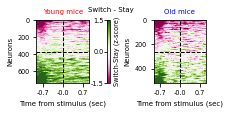

In [50]:
########################################################################
##### Figure 3e #####
########################################################################

set_rcParams()
plt.figure(figsize=np.array([2.4, 1.1]))

titles = ['Young mice', 'Old mice']
colors = ['red', 'blue']
which_cells = [23, 28]

source_rows = []
a = []

for gi, allCells in enumerate(AllCells):

    ax = plt.axes([gi*0.68, 0, 0.48-0.18*gi, 0.8])

    # Switch - Stay activity for every neuron
    z = allCells[0] - allCells[1]

    # Sort neurons according to mean switch-stay modulation
    # during the early prestimulus period
    half_ind = 10
    ms = np.nanmean(z[:, :half_ind], axis=1)
    inds = ms.argsort()

    # Sorted matrix actually shown in heatmap
    y = z[inds, :]

    # Locate example neuron in sorted matrix
    row = np.flatnonzero(inds == which_cells[gi])
    a.append(y[row, :])

    ####################################################################
    ##### Source data #####
    ####################################################################

    for sorted_rank, original_neuron_index in enumerate(inds):

        for ti, t in enumerate(time):

            source_rows.append({
                'Age_group': titles[gi],
                'Sorted_neuron_rank': sorted_rank + 1,
                'Original_neuron_index': int(original_neuron_index),
                'Example_neuron': int(original_neuron_index == which_cells[gi]),
                'Time_from_stimulus_sec': t,
                'Switch_minus_stay_zscore': y[sorted_rank, ti]
            })

    ####################################################################
    ##### Plot #####
    ####################################################################

    im = plt.imshow(
        y,
        cmap='PiYG',
        aspect='auto',
        vmin=-1.5,
        vmax=1.5
    )

    plt.axhline(
        row,
        0,
        0.1,
        color='grey',
        linestyle='-',
        linewidth=1
    )

    plt.axhline(
        len(inds)/2,
        0,
        1,
        color='black',
        linestyle='--',
        linewidth=1
    )

    plt.axvline(
        z.shape[1]/2 - 0.5,
        0,
        z.shape[0],
        color='black',
        linestyle='--',
        linewidth=1
    )

    tind = np.arange(6, z.shape[1], 21)

    plt.xticks(
        tind,
        labels=[f'{t:1.1f}' for t in time[tind]]
    )

    plt.ylabel('Neurons', fontsize=7)
    plt.xlabel('Time from stimulus (sec)', fontsize=7)
    plt.title(titles[gi], fontsize=7, color=colors[gi])

    if gi == 0:
        cbar = plt.colorbar(
            im,
            pad=0.21,
            label='Switch-Stay (z-score)',
            ticks=[-1.5, 0, 1.5],
            format='%1.1f'
        )

        cax = cbar.ax
        cax.yaxis.set_ticks_position('left')
        cax.tick_params(axis='y', pad=0.01)


ax = plt.axes([0, 0, 1, 0.9])
ax.set_axis_off()

plt.text(
    0.3,
    1,
    'Switch - Stay',
    fontsize=7
)

plt.savefig(
    'Fig3e_GC_PopulationDeltaHeatmap.svg'
)

In [51]:
########################################################################
##### Save source data #####
########################################################################

Fig3e_source = pd.DataFrame(source_rows)

Fig3e_source.to_csv(
    'Fig3e_source_data.csv',
    index=False
)

## Figure 3f-g
Mean Switch-Stay activity

[-0.45       -0.41666667 -0.38333333 -0.35       -0.31666667 -0.28333333
 -0.25       -0.21666667 -0.18333333 -0.15        0.38333333  0.45
  0.48333333  0.51666667]
Num of Time points:55
3.73741307378778
[-0.48333333 -0.45       -0.41666667 -0.38333333 -0.35       -0.31666667
 -0.28333333 -0.25       -0.21666667 -0.18333333 -0.15        0.21666667
  0.25        0.28333333  0.31666667  0.51666667  0.55        0.58333333]
Num of Time points:55
12.9389311638884


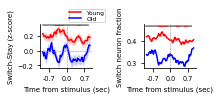

In [52]:
#########################################################################
#### Figure 3f-g #####
########################################################################

##### delta z traces
from scipy.stats import chi2_contingency
set_rcParams()    
plt.figure(figsize = np.array([2.4, 2.8]))
ax = plt.axes([0, 0.6, 0.3, 0.22])
set_plot(ax)
titles = ['Young', 'Old']
colors2 = ['red', 'blue']
for j, allCells in enumerate(AllCells):
    sig = allCells[0] - allCells[1]
    meanCells = np.nanmean(sig, axis=0)
    stdCells = np.nanstd(sig, axis=0)/np.sqrt(sig.shape[0])
    plt.fill_between(time, meanCells-stdCells, meanCells+stdCells, color=colors2[j], alpha=0.2, linewidth=0)
    plt.plot(time, meanCells, color=colors2[j])
plt.legend(titles, loc='upper right', bbox_to_anchor=(1.3, 1.4), borderpad=0.1, labelspacing=0.2, fontsize=6)

pvals=[]
ts = []
results=[]
for ti in range(AllCells[0].shape[-1]):
    sig1 = AllCells[0][0][:,ti] - AllCells[0][1][:,ti]
    sig2 = AllCells[1][0][:,ti] - AllCells[1][1][:,ti]
    
    r, p = stats.ttest_ind(sig1,sig2)
    test = twoSampleTest(sig1, sig2)
    results.append(test)
    pvals.append(test['p'])
    ts.append(r)

alpha = 0.05
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
plt.plot(time[tinds], np.ones(len(tinds),)*0.35, color='grey', marker='*', markersize=0.2)

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = pvals_corrected[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('posthoc_statistics_fig3f.csv', index=False)

alpha = 0.001
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
plt.plot(time[tinds], np.ones(len(tinds),)*0.35, 'r*', markersize=0.2)
print(time[tinds])
print(f'Num of Time points:{len(pvals)}')
print(np.min(np.abs(np.array(ts)[rejected])))

plt.xticks(np.arange(-0.67, 0.7, 0.67), labels=['-0.7', '0.0', '0.7'])
plt.ylim(-0.24, 0.36)
plt.yticks([-0.2, 0, 0.2])
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.ylabel('Switch-Stay (z-score)', fontsize=7)
plt.xlabel('Time from stimulus (sec)', fontsize=7)

#### fraction neurons
ax = plt.axes([0.6, 0.6, 0.3, 0.22])
set_plot(ax)
for j, allCells in enumerate(AllCells):
    sig = allCells[0] - allCells[1]
    
    fracSwitch = []
    for ti in range(sig.shape[1]):
        inds = np.intersect1d(np.arange(ti-5, ti+5), np.arange(0, sig.shape[1]))
        msig = np.nanmean(sig[:,inds], axis=-1)
        fracSwitch.append(len(np.flatnonzero(msig>0.5))/len(msig))

    
    plt.plot(time, fracSwitch, color=colors2[j])
plt.xticks(np.arange(-0.67, 0.7, 0.67), labels=['-0.7', '0.0', '0.7'])
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.ylabel('Switch neuron fraction', fontsize=7)
plt.xlabel('Time from stimulus (sec)', fontsize=7)

pvals = []
ts = []
results = []
for ti in range(AllCells[0].shape[-1]):
    mat = []
    for j in range(2):
        sig = AllCells[j][0]-AllCells[j][1]
        inds = np.intersect1d(np.arange(ti-5, ti+5), np.arange(0, AllCells[0].shape[-1]))
        msig = np.nanmean(sig[:,inds], axis=-1)                                         
        mat.append(np.array([len(np.flatnonzero(msig>0.5)), len(msig)]))
                                         
    mat = np.array(mat)
    test = chiSquareTest(mat[0][0], mat[0][1], mat[1][0], mat[1][1], label='Fig. 3g',group1='Young', group2='Old')
    pvals.append(test['p'])
    ts.append(test['statistic'])
    results.append(test)
    
tinds = np.flatnonzero(np.array(pvals)*AllCells[0].shape[-1]<0.05)    
from statsmodels.stats.multitest import multipletests
# Apply Benjamini-Hochberg FDR correction
alpha = 0.05
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
plt.plot(time[tinds], np.ones(len(tinds),)*0.47, color='grey', marker='*', markersize=0.2)

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = pvals_corrected[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('posthoc_statistics_fig3g.csv', index=False)

alpha = 0.001
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
plt.plot(time[tinds], np.ones(len(tinds),)*0.47, 'r*', markersize=0.2)
print(time[tinds])
print(f'Num of Time points:{len(pvals)}')
print(np.min(np.abs(np.array(ts)[rejected])))
plt.savefig('Fig3f_GC_SingleNeurons.svg')

In [53]:
########################################################################
##### Source data: Figure 3f #####
########################################################################

fig3f_rows = []
group_labels = ['Young', 'Old']

for gi, allCells in enumerate(AllCells):

    # neurons x time
    sig = allCells[0] - allCells[1]

    for neuron_i in range(sig.shape[0]):

        for ti, t in enumerate(time):

            fig3f_rows.append({
                'Age_group': group_labels[gi],
                'Neuron_index': neuron_i,
                'Time_from_stimulus_sec': t,
                'Switch_minus_stay_zscore': sig[neuron_i, ti]
            })

Fig3f_source = pd.DataFrame(fig3f_rows)

Fig3f_source.to_csv(
    'Fig3f_source_data.csv',
    index=False
)

########################################################################
##### Source data: Figure 3g #####
########################################################################

fig3g_rows = []

for gi, allCells in enumerate(AllCells):

    sig = allCells[0] - allCells[1]

    for ti, t in enumerate(time):

        # Same local temporal window used in the figure
        inds = np.intersect1d(
            np.arange(ti - 5, ti + 5),
            np.arange(sig.shape[1])
        )

        # Mean switch-stay modulation for each neuron
        # within the local time window
        msig = np.nanmean(sig[:, inds], axis=1)

        num_positive = len(
            np.flatnonzero(msig > 0.5)
        )

        total_neurons = len(msig)

        fraction_positive = (
            num_positive / total_neurons
        )

        fig3g_rows.append({
            'Age_group': group_labels[gi],
            'Time_from_stimulus_sec': t,
            'Num_switch_neurons': num_positive,
            'Total_neurons': total_neurons,
            'Switch_neuron_fraction': fraction_positive
        })


Fig3g_source = pd.DataFrame(fig3g_rows)

Fig3g_source.to_csv(
    'Fig3g_source_data.csv',
    index=False
)

## Figure 3h
Distribution of ITI (switch-stay) values

1.8834298785019854e-06 745 521
p<0.000


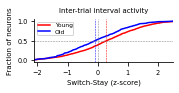

In [54]:
########################################################################
##### Figure 3h #####
########################################################################

##### Cumulative distribution of delta
set_rcParams()
plt.figure(figsize = np.array([2.4, 0.6]))
titles = ['Young', 'Old']
colors2 = ['red', 'blue']

ax = plt.axes([0, 0, 0.8, 1])
set_plot(ax)
bigMat = []
for j, allCells in enumerate(AllCells):
    sig = allCells[0] - allCells[1]

    tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))
    tind = np.flatnonzero((time>=-0.45)*(time<=-0.15))
    fracSwitch = []
    for ci in range(sig.shape[0]):
        fracSwitch.append(np.nanmean(sig[ci, tind]))
    bigMat.append(fracSwitch)
    bins = np.arange(-2.5, 5, 0.005)
    hist, bin_edges = np.histogram(fracSwitch, bins)
    plt.plot(bin_edges[:-1]+(bin_edges[1]-bin_edges[0])/2, np.cumsum(hist/np.sum(hist)), color=colors2[j])
plt.legend(titles, loc='upper left', bbox_to_anchor=(0, 1), borderpad=0.1, labelspacing=0.2, fontsize=6)
plt.xlim(-2.1,2.5)
plt.ylabel('Fraction of neurons', fontsize=7)
plt.xlabel('Switch-Stay (z-score)', fontsize=7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(bigMat[0],0), color='red', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(bigMat[1],0), color='blue', linestyle='--', linewidth=0.5)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.5)
plt.title('Inter-trial interval activity', fontsize=7)
plt.savefig('Fig3h_GC_CumSum.svg')

x=bigMat[0]
y=bigMat[1]

test = twoSampleTest(x, y)
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_fig3hMean.csv', index=False)

test = ksTest(x, y, label='Fig. 3h')
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_fig3h.csv', index=False)

p = test['p']


print(p, len(bigMat[0]), len(bigMat[1]))
print(f'p<{p:1.3f}')

In [55]:
########################################################################
##### Source data: Figure 3h #####
########################################################################

source_rows = []
group_labels = ['Young', 'Old']

# Final ITI window actually used in the figure
tind = np.flatnonzero(
    (time >= -0.45) &
    (time <= -0.15)
)

for gi, allCells in enumerate(AllCells):

    # neurons x time
    sig = allCells[0] - allCells[1]

    for neuron_i in range(sig.shape[0]):

        iti_mean = np.nanmean(
            sig[neuron_i, tind]
        )

        source_rows.append({
            'Age_group': group_labels[gi],
            'Neuron_index': neuron_i,
            'ITI_window_start_sec': -0.45,
            'ITI_window_end_sec': -0.15,
            'Mean_switch_minus_stay_zscore': iti_mean
        })


Fig3h_source = pd.DataFrame(source_rows)

Fig3h_source.to_csv(
    'Fig3h_source_data.csv',
    index=False
)

## Figure 3i-j
ITI (switch-stay) values per mouse

{'Comparison': '', 'Group 1': 'Group1', 'Group 2': 'Group2', 'n1': 6, 'n2': 5, 'mean1': 0.25776448521534784, 'SD1': 0.1617483527002616, 'median1': 0.24736109290226355, 'Q1_1': 0.20209343593817158, 'Q3_1': 0.28239638004886436, 'mean2': -0.12086187850992287, 'SD2': 0.20636665807439566, 'median2': -0.029606242854418707, 'Q1_2': -0.25534072079129505, 'Q3_2': 0.030387586137567923, 'test': "Welch's t-test", 'statistic': 3.336483504884658, 'p': 0.011158872001790178}: 0.01
{'Comparison': '', 'Group 1': 'Group1', 'Group 2': 'Group2', 'n1': 6, 'n2': 5, 'mean1': 0.4298540991168516, 'SD1': 0.0729681278455207, 'median1': 0.41585177560473496, 'Q1_1': 0.4051724137931034, 'Q3_1': 0.43312929733355693, 'mean2': 0.296608812129503, 'SD2': 0.07898719286414821, 'median2': 0.2916666666666667, 'Q1_2': 0.2647058823529412, 'Q3_2': 0.35, 'test': "Welch's t-test", 'statistic': 2.883592837876329, 'p': 0.01953697036543521}: 0.02


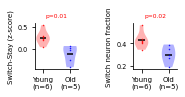

In [56]:
########################################################################
##### Figure 3i-j #####
############################################################

##### per mouse
set_rcParams()
plt.figure(figsize = np.array([2.4, 0.8]))
colors = ['red', 'blue']
titles = ['Young', 'Old']
N=6
bigMat =[]
labels = []
ax = plt.axes([0, 0.07, 0.25, 0.8])    
set_plot(ax)
for i in [0,1]:
    inds = np.arange(N) if i==0 else np.arange(N, MeanSig.shape[0],1)
    
    sig = MeanSig[inds, 0]-MeanSig[inds,1]
    vp = plt.violinplot(sig, [i], showmeans=True, showextrema=False, widths=0.5)
    for pc in vp['bodies']:
        pc.set_facecolor(colors[i])
    vp['cmeans'].set_color('black')
    plt.plot(i*np.full_like(sig, 1), sig, '.', color=colors[i], markersize=1)
    bigMat.append(sig)
    labels.append(titles[i]+f'\n(n={sig.shape[0]})')
plt.xlim(-0.3, 1.3)
plt.xticks([0, 1], labels=labels, fontsize=7)    
plt.ylabel('Switch-Stay (z-score)', fontsize=7)

test = twoSampleTest(bigMat[0], bigMat[1])  
p=test['p']
print(f'{test}: {p:1.2f}')
df = pd.DataFrame([test])
df.to_csv(f'posthoc_statistics_fig3i.csv', index=False)

plt.title(f'p={p:1.2f}', color='r', fontsize=6)

ax = plt.axes([0.57, 0.07, 0.25, 0.8])    
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
labels = []
bigMat = []
for i in [0,1]:
    inds = np.arange(N) if i==0 else np.arange(N, MeanSig.shape[0],1)
    
    sig = FSwitch[inds]
    vp = plt.violinplot(sig, [i], showmeans=True, showextrema=False, widths=0.5)
    for pc in vp['bodies']:
        pc.set_facecolor(colors[i])
    vp['cmeans'].set_color('black')
    plt.plot(i*np.full_like(sig, 1), sig, '.', color=colors[i], markersize=1)
    bigMat.append(sig)
    labels.append(titles[i]+f'\n(n={sig.shape[0]})')
plt.xlim(-0.3, 1.3)
plt.xticks([0, 1], labels=labels, fontsize=7)
plt.ylabel('Switch neuron fraction', fontsize=7)
test = twoSampleTest(bigMat[0], bigMat[1])  
p=test['p']
print(f'{test}: {p:1.2f}')
df = pd.DataFrame([test])
df.to_csv(f'posthoc_statistics_fig3j.csv', index=False)

plt.title(f'p={p:1.2f}', color='r', fontsize=6)
plt.savefig('Fig3ij_GC_youngVSoldPerMouse.svg')

In [57]:
########################################################################
##### Source data: Figure 3i-j #####
########################################################################

source_rows = []

N = 6

for i, group in enumerate(['Young', 'Old']):

    inds = (
        np.arange(N)
        if i == 0
        else np.arange(N, MeanSig.shape[0])
    )

    # Fig. 3i
    switch_stay = MeanSig[inds, 0] - MeanSig[inds, 1]

    # Fig. 3j
    switch_fraction = FSwitch[inds]

    for mouse_index, ss, fs in zip(
        inds,
        switch_stay,
        switch_fraction
    ):
        source_rows.append({
            'Age_group': group,
            'Mouse_index': int(mouse_index),
            'Mean_switch_minus_stay_zscore': ss,
            'Switch_neuron_fraction': fs
        })


Fig3ij_source = pd.DataFrame(source_rows)

Fig3ij_source.to_csv(
    'Fig3ij_source_data.csv',
    index=False
)

## Figure 3k
ITI mean switch versus stay activity per mouse

{'Comparison': '', 'Group 1': 'Condition1', 'Group 2': 'Condition2', 'n1': 6, 'n2': 6, 'mean1': 0.05800849757102342, 'SD1': 0.22022237160247088, 'median1': 0.0580985241562087, 'Q1_1': -0.0402179912836194, 'Q3_1': 0.17735184448972358, 'mean2': -0.19975598764432445, 'SD2': 0.2526170654565598, 'median2': -0.21287106081763435, 'Q1_2': -0.34135694552573287, 'Q3_2': -0.06797449378738049, 'test': 'Paired t-test', 'statistic': 3.903541841683062, 'p': 0.011368656262946857}: 0.01
{'Comparison': '', 'Group 1': 'Condition1', 'Group 2': 'Condition2', 'n1': 5, 'n2': 5, 'mean1': -0.32354406652803513, 'SD1': 0.2932597845413152, 'median1': -0.20727440402460962, 'Q1_1': -0.6089731392525399, 'Q3_1': -0.07736856526849815, 'mean2': -0.20268218801811227, 'SD2': 0.2583352249368009, 'median2': -0.12269683403057315, 'Q1_2': -0.19407167128242084, 'Q3_2': -0.10775615140606608, 'test': 'Paired t-test', 'statistic': -1.309588374198902, 'p': 0.2604881514081956}: 0.26


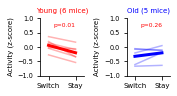

In [58]:
########################################################################
##### Figure 3k #####
########################################################################
set_rcParams()
time = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
N=6

############################################################
##### ITI activity comparison between switch versus stay
colors = ['red', 'blue']
titles = ['Young', 'Old']
plt.figure(figsize = np.array([2.0, 0.8]))
for i in [0,1]:
    inds = np.arange(N) if i==0 else np.arange(N, MeanSig.shape[0],1)
    ax = plt.axes([0.6*i, 0.07, 0.3, 1])
    set_plot(ax)


    plt.plot(MeanSig[inds,:].T, color=colors[i], alpha=0.3)
    plt.plot(np.nanmean(MeanSig[inds,:],axis=0), color=colors[i], linewidth=3)

    x = MeanSig[inds,0]
    y = MeanSig[inds,1]
    test = pairedTest(x, y)  
    p=test['p']
    print(f'{test}: {p:1.2f}')
    df = pd.DataFrame([test])
    df.to_csv(f'posthoc_statistics_fig3k{i}.csv', index=False)

    plt.ylim([-1, 1])
    plt.xlim(-0.3, 1.3)
    plt.xticks([0, 1], labels=['Switch', 'Stay'], fontsize=7)
    plt.ylabel('Activity (z-score)', fontsize=7)
    plt.title(f'{titles[i]} ({len(inds)} mice)', fontsize=7, color=colors[i])
    plt.text(0.2, 0.7, f'p={p:1.2f}', color='r', fontsize=6)
plt.savefig('Fig3k_GC_youngVSold.svg')

In [59]:
########################################################################
##### Source data: Figure 3k #####
########################################################################

source_rows = []

N = 6
group_labels = ['Young', 'Old']

for i, group in enumerate(group_labels):

    inds = (
        np.arange(N)
        if i == 0
        else np.arange(N, MeanSig.shape[0])
    )

    for mouse_index in inds:

        source_rows.append({
            'Age_group': group,
            'Mouse_index': int(mouse_index),
            'Switch_activity_zscore': MeanSig[mouse_index, 0],
            'Stay_activity_zscore': MeanSig[mouse_index, 1],
            'Switch_minus_stay_zscore': (
                MeanSig[mouse_index, 0] -
                MeanSig[mouse_index, 1]
            )
        })


Fig3k_source = pd.DataFrame(source_rows)

Fig3k_source.to_csv(
    'Fig3k_source_data.csv',
    index=False
)

# Figure 4 and Supplementary Figure 4: JEDI imaging experiment.

## Run this before Figure 4 and S4
Load subject database for JEDI imaging experiment

In [60]:
##### Load subject database and compile mice in JEDI imaging experiment

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 4,   ['experiment'], ['JEDI']),
    combine_criteria(15, 24, ['experiment'], ['JEDI']),
] 
JEDI_subjects, JEDI_group_names, JEDI_ages, JEDI_sexes, JEDI_dates = group_subjects(group_criteria, SubjectDB)

Ages =[]
for age in JEDI_ages:
    Ages.append([np.round(np.nanmin(age)), np.round(np.nanmax(age))])
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 4.0]
Age: [19.0, 19.0]


## Run this first before Figure 4b-d

In [61]:
##### Run this first for Figure 4b-d
fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2

AllCells=[]
MeanSig = np.array([])
for group in range(2):
    allCells = []
    for subject in JEDI_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
   
      
        trials_list = []
        choices = trial_data['choice']
        pre_choices = np.hstack(([0], choices[:-1]))
        for ci in range(2):
            if ci == 0:
                trials = np.flatnonzero(choices*pre_choices<0)
            elif ci == 1:
                trials = np.flatnonzero(choices*pre_choices>0)
            trials_list.append(trials)        
        
        trials_list = np.array(trials_list, dtype=object)
        SNR = neural_data['SNR']
        cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))
      
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  
                                                                window_length = wl, smooth_window=sw, offset = off, trials_list = trials_list, 
                                                                FrameRate = fr, zScore=0, key='rates', plot=False)   
        zsignal = np.full_like(signal, np.nan)
        for ci in range(len(cells)):
            my = np.nanmean(signal[:, ci, :])
            sy = np.nanstd(signal[:,ci,:])
            zsignal[:, ci,: ] = (signal[:, ci, :] - my)/sy

        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr
        tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))

        MeanSig = np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1) if len(MeanSig)==0 else np.vstack((MeanSig,np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1)))
        a = (np.mean(zsignal[0,:,tind]-zsignal[1,:,tind], axis=0).argsort())
        allCells = zsignal if len(allCells)==0 else np.concatenate((allCells,zsignal), axis=1)
        
    AllCells.append(allCells)

In [62]:
##### Run this first for Figure 4b-c
subject = 'Mouse056'

fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2


trial_data = read_behavioral_data(subject)
neural_data, FrameNum, TrialNum = read_cell_data(subject)
cells = np.flatnonzero(neural_data['iscell'][:,0])

S2PDirectory = Path(imaging, subject, 'day1')
volpy_name = f"volpy_data_d1_96_d2_352_d3_1_order_F_frames_399166_simple_{110}"
vpy = np.load(Path(S2PDirectory, volpy_name + '.npy'), allow_pickle=True).item()

choices = trial_data['choice']
pre_choices = np.hstack(([0], choices[:-1]))
exploration = (choices*pre_choices<0)

SNR = neural_data['SNR']
cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))

## Figure 4b
JEDI raw and processed signal of an example neuron 

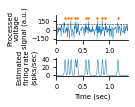

In [63]:
########################################################################
##### Figure 4b #####
########################################################################
plt.figure(figsize=np.array([1, 1.0])*1)

ax = plt.axes([0, 0.5, 1, 0.35])
set_plot(ax)

istart = 7800
window = np.arange(200)+istart

plt.plot(vpy['t'][0,window], linewidth=0.5)
inds = np.flatnonzero((vpy['spikes'][0]>=istart)*(vpy['spikes'][0]<istart+200))
plt.plot(vpy['spikes'][0][inds]-istart, np.full_like(inds, 200), '.', markersize=3)

plt.axhline(vpy['thresh'], color='black', linestyle='--', linewidth=0.5)
plt.xticks(np.arange(0, 200, 147/2), ['0', '0.5', '1.0'])
ax.set_yticks([-150, 0, 150])
plt.ylabel(f'Processed\nvoltage\nsignal (a.u.)', fontsize=7)
plt.xlim(0,200)
plt.ylim(-180,250)

#ax = plt.axes([0, 0, 1, 0.18])
ax = plt.axes([0, 0, 1, 0.25])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.plot(neural_data['rates'][110,window], linewidth=0.5)
plt.yticks([0, 20, 40])
plt.xticks(np.arange(0, 200, 147/2), ['0', '0.5', '1.0'])
plt.xlabel('Time (sec)', fontsize=7)
plt.ylabel(f'Estimated\nfiring rate\n(spks/sec)', fontsize=7)
plt.xlim(0,200)

plt.savefig('Fig4b_Jedi_trace.svg')

In [64]:
########################################################################
##### Source data: Figure 4b #####
########################################################################

fr = 147
istart = 7800
window = np.arange(200) + istart

# Processed voltage trace
voltage_trace = vpy['t'][0, window]

# Estimated firing rate
firing_rate = neural_data['rates'][110, window]

# Spike locations within plotted window
spike_frames = vpy['spikes'][0][
    (vpy['spikes'][0] >= istart) &
    (vpy['spikes'][0] < istart + len(window))
]

# Boolean indicator for whether each plotted frame contains a detected spike
spike_detected = np.isin(window, spike_frames)

# Time relative to beginning of displayed segment
time_sec = np.arange(len(window)) / fr

Fig4b_source = pd.DataFrame({
    'Time_sec': time_sec,
    'Frame_index': window,
    'Processed_voltage_signal_au': voltage_trace,
    'Spike_detected': spike_detected.astype(int),
    'Spike_threshold': np.full(len(window), np.asarray(vpy['thresh']).squeeze()),
    'Estimated_firing_rate_spikes_per_sec': firing_rate
})

Fig4b_source.to_csv(
    'Fig4b_source_data.csv',
    index=False
)

## Figure 4c
Example raster switch versus stay trials

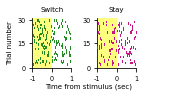

In [65]:
########################################################################
##### Figure 4c #####
########################################################################
set_rcParams()

plt.figure(figsize=np.array([1.8, 0.7]))
bigMat=[]
colors = ['forestgreen', 'mediumvioletred']
groups=['Switch', 'Stay']
for ci in range(2):
    if ci == 0:
        trials = np.flatnonzero(choices*pre_choices<0)
    elif ci == 1:
        trials = np.flatnonzero(choices*pre_choices>0)
    allMat=[]
    bax=plt.axes([0.5*ci, 0, 0.3, 1])
    set_plot(bax)
    plt.fill_between([0*147, 1*147],[0, 0], [1,1], color='yellow', alpha=0.5, linewidth=0)
    plt.xlim(0, 147*2)
    bax.set_xticks([0,147,147*2])
    bax.set_xticklabels(['-1', '0', '1'])
    if ci==0:
        plt.ylabel('Trial number', fontsize=7)
    plt.ylim(0, 1)
    bax.set_yticks([0.0,0.5,0.96])
    bax.set_yticklabels(['0', '15', '30'])
    plt.title(groups[ci], fontsize=7)
    for ti, tr in enumerate(trials[30:60]):
        ii= int(np.round((trial_data['stimOnTrigger_times'][tr]-trial_data['bitcode0'][tr]-1)*147))
        ie= int(np.round((trial_data['stimOnTrigger_times'][tr]-trial_data['bitcode0'][tr]+1)*147))
        frames = FrameNum[tr][0] + np.arange(ii, ii+294, 1)
        ax=plt.axes([0.5*ci, ti*0.03+0.07, 0.3, 0.03])    
        y = np.flatnonzero(vpy['t_rec'][0, frames]>150)
        plt.plot(y, np.full_like(y,1), '|', color=colors[ci])
        plt.xlim(0, 147*2)
        ax.set_axis_off()
        allMat.append(vpy['t_rec'][0, frames])
    bigMat.append(np.nanmean(allMat, axis=0))
ax = plt.axes([0,-0.4,1,1])
plt.text(0.1, 0, 'Time from stimulus (sec)', fontsize=7)
ax.set_axis_off()
plt.savefig('Fig4c_FiringExample.svg')

In [66]:
########################################################################
##### Source data: Figure 4c #####
########################################################################

source_rows = []

groups = ['Switch', 'Stay']
fr = 147

for ci in range(2):

    if ci == 0:
        trials = np.flatnonzero(choices * pre_choices < 0)
    else:
        trials = np.flatnonzero(choices * pre_choices > 0)

    # Same subset of trials shown in the figure
    shown_trials = trials[30:60]

    for display_trial, tr in enumerate(shown_trials, start=1):

        ii = int(
            np.round(
                (trial_data['stimOnTrigger_times'][tr]
                 - trial_data['bitcode0'][tr]
                 - 1) * fr
            )
        )

        frames = (
            FrameNum[tr][0] +
            np.arange(ii, ii + 2 * fr)
        )

        trace = vpy['t_rec'][0, frames]

        # Event criterion used in the figure
        event_detected = trace > 150

        time_sec = np.arange(len(trace)) / fr - 1

        for t, frame, value, event in zip(
                time_sec,
                frames,
                trace,
                event_detected):

            source_rows.append({
                'Condition': groups[ci],
                'Behavioral_trial_number': int(tr),
                'Displayed_trial_number': display_trial,
                'Time_from_stimulus_sec': t,
                'Imaging_frame_index': int(frame),
                'Reconstructed_voltage_signal_au': value,
                'Event_detected_threshold_150': int(event)
            })


Fig4c_source = pd.DataFrame(source_rows)

Fig4c_source.to_csv(
    'Fig4c_source_data.csv',
    index=False
)

## Figure 4d
Mean switch-stay activity

Num of Time points:266
2.6899825820321697
[-0.59863946 -0.59183673 -0.57142857 -0.56462585 -0.55782313 -0.55102041
 -0.54421769 -0.53741497 -0.53061224 -0.52380952 -0.5170068  -0.51020408
 -0.50340136 -0.49659864 -0.48979592 -0.4829932  -0.47619048 -0.46938776
 -0.46258503 -0.45578231 -0.44897959 -0.44217687 -0.43537415 -0.42857143
 -0.42176871 -0.41496599 -0.40816327 -0.40136054 -0.39455782 -0.3877551
 -0.38095238 -0.37414966 -0.36734694 -0.36054422 -0.3537415  -0.34693878
 -0.34013605 -0.33333333 -0.32653061  0.13605442  0.14285714]
Num of Time points:266
8.084351949156778
[-0.6122449  -0.60544218 -0.59863946 -0.59183673 -0.58503401 -0.57823129
 -0.57142857 -0.56462585 -0.55782313 -0.55102041 -0.54421769 -0.53741497
 -0.53061224 -0.52380952 -0.5170068  -0.51020408 -0.50340136 -0.49659864
 -0.48979592 -0.4829932  -0.47619048 -0.46938776 -0.46258503 -0.45578231
 -0.44897959 -0.44217687 -0.43537415 -0.42857143 -0.42176871 -0.41496599
 -0.40136054]


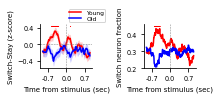

In [67]:
########################################################################
##### Figure 4d #####
########################################################################
set_rcParams()

compress = 1
time0 = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
subi = np.arange(0, len(time0), compress)
time = time0[subi]

N=5
AllCells2 = []
for i in range(2):
    allcells = AllCells[i]
    allcells2 = np.ones((allcells.shape[0], allcells.shape[1], len(subi)))*np.nan
    for j in range(2):
        allcells2[j] = allcells[j][:,subi] 
    AllCells2.append(allcells2)

colors = ['red', 'blue']
titles = ['Young', 'Old']

############################################################
############################################################
##### delta z traces
plt.figure(figsize = np.array([2.4, 2.8]))
colors2 = ['red', 'blue']
ax = plt.axes([0, 0.6, 0.3, 0.22])
set_plot(ax)
for j, allCells in enumerate(AllCells2):
    sig = allCells[0] - allCells[1]
    meanCells = np.nanmean(sig, axis=0)
    stdCells = np.nanstd(sig, axis=0)/np.sqrt(sig.shape[0])
    plt.fill_between(time, meanCells-stdCells, meanCells+stdCells, color=colors2[j], alpha=0.2, linewidth=0)
    plt.plot(time, meanCells, color=colors2[j])
plt.legend(titles, loc='upper right', bbox_to_anchor=(1.3, 1.4), borderpad=0.1, labelspacing=0.2, fontsize=6)
pvals=[]
ts=[]
results=[]
for ti in range(AllCells2[0].shape[-1]):
    sig1 = AllCells2[0][0][:,ti] - AllCells2[0][1][:,ti]
    sig2 = AllCells2[1][0][:,ti] - AllCells2[1][1][:,ti]
    
    test = twoSampleTest(sig1, sig2)
    results.append(test)
    pvals.append(test['p'])
    ts.append(test['statistic'])

from statsmodels.stats.multitest import multipletests
# Apply Benjamini-Hochberg FDR correction
alpha = 0.05
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
print(f'Num of Time points:{len(pvals)}')
print(np.min(np.abs(np.array(ts)[rejected])))

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = pvals_corrected[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('posthoc_statistics_fig4dLeft.csv', index=False)

#tinds = np.flatnonzero(np.array(pvals)<0.05)    
plt.plot(time[tinds], np.ones(len(tinds),)*0.45, 'r*', markersize=0.2)
print(time[tinds])

plt.xticks(np.arange(-0.7, 0.71, 0.7), labels=['-0.7', '0.0', '0.7'])
#plt.ylim(-0.24, 0.36)
plt.yticks(np.arange(-0.4, 0.41, 0.4))
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.ylabel('Switch-Stay (z-score)', fontsize=7)
plt.xlabel('Time from stimulus (sec)', fontsize=7)


############################################################
############################################################
ax = plt.axes([0.6, 0.6, 0.3, 0.22])
set_plot(ax)

for j, allCells in enumerate(AllCells2):
    sig = allCells[0] - allCells[1]
    
    fracSwitch = []
    for ti in range(sig.shape[1]):
        inds = np.intersect1d(np.arange(ti-int(20/compress), ti+int(20/compress)), np.arange(0, sig.shape[1]))
        msig = np.nanmean(sig[:,inds], axis=-1)
        fracSwitch.append(len(np.flatnonzero(msig>0.5))/len(msig))

    
    plt.plot(time, fracSwitch, color=colors2[j])
plt.xticks(np.arange(-0.7, 0.71, 0.7), labels=['-0.7', '0.0', '0.7'])
plt.ylim(0.2, 0.46)
plt.yticks([0.2, 0.3, 0.4])
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
#plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.5)
plt.ylabel('Switch neuron fraction', fontsize=7)
plt.xlabel('Time from stimulus (sec)', fontsize=7)
#plt.title(f'{titles[j]} ({len(sig)} neurons)', fontsize=7, color=colors[j])
pvals = []
ts =[]
results=[]
for ti in range(AllCells2[0].shape[-1]):
    mat = []
    for j in range(2):
        sig = AllCells2[j][0]-AllCells2[j][1]
        inds = np.intersect1d(np.arange(ti-20, ti+20), np.arange(0, AllCells2[0].shape[-1]))
        msig = np.nanmean(sig[:,inds], axis=-1)
        #mat.append(np.array([len(np.flatnonzero(msig>0.5)), len(msig)-len(np.flatnonzero(msig>0.5))]))
        mat.append(np.array([len(np.flatnonzero(msig>0.5)), len(msig)]))
                                         
    mat = np.array(mat)
    test = chiSquareTest(mat[0][0], mat[0][1], mat[1][0], mat[1][1], label='Fig. 4dRight',group1='Young', group2='Old')
    pvals.append(test['p'])
    ts.append(test['statistic'])
    results.append(test)
    
alpha = 0.05
rejected, pvals_corrected, _, _ = multipletests(pvals, alpha=alpha, method='fdr_bh')
tinds = np.where(rejected)[0] 
plt.plot(time[tinds], np.ones(len(tinds),)*0.45, 'r*', markersize=0.2)
print(f'Num of Time points:{len(pvals)}')
print(np.min(np.abs(np.array(ts)[rejected])))
print(time[tinds])

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = pvals_corrected[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('posthoc_statistics_fig4dRight.csv', index=False)


plt.savefig('Fig4d_JEDI_SingleNeurons.svg')

In [68]:
########################################################################
##### Source data: Figure 4e left #####
########################################################################

fig4e_left_rows = []
group_labels = ['Young', 'Old']

for gi, allCells in enumerate(AllCells2):

    # neurons x time
    sig = allCells[0] - allCells[1]

    for neuron_i in range(sig.shape[0]):

        for ti, t in enumerate(time):

            fig4e_left_rows.append({
                'Age_group': group_labels[gi],
                'Neuron_index': neuron_i,
                'Time_from_stimulus_sec': t,
                'Switch_minus_stay_zscore': sig[neuron_i, ti]
            })


Fig4e_left_source = pd.DataFrame(fig4e_left_rows)

Fig4e_left_source.to_csv(
    'Fig4d_left_source_data.csv',
    index=False
)

########################################################################
##### Source data: Figure 4e right #####
########################################################################

fig4e_right_rows = []

for gi, allCells in enumerate(AllCells2):

    sig = allCells[0] - allCells[1]

    for ti, t in enumerate(time):

        # Same local temporal window used for the plotted fraction
        inds = np.intersect1d(
            np.arange(
                ti - int(20/compress),
                ti + int(20/compress)
            ),
            np.arange(sig.shape[1])
        )

        # Locally averaged switch-stay modulation for each neuron
        msig = np.nanmean(
            sig[:, inds],
            axis=1
        )

        num_switch = len(
            np.flatnonzero(msig > 0.5)
        )

        total_neurons = len(msig)

        fraction_switch = (
            num_switch / total_neurons
        )

        fig4e_right_rows.append({
            'Age_group': group_labels[gi],
            'Time_from_stimulus_sec': t,
            'Num_switch_neurons': num_switch,
            'Total_neurons': total_neurons,
            'Switch_neuron_fraction': fraction_switch
        })


Fig4e_right_source = pd.DataFrame(fig4e_right_rows)

Fig4e_right_source.to_csv(
    'Fig4d_right_source_data.csv',
    index=False
)

## Run this first before Figure 4e-f

In [69]:
#### Run this first for Figure 4e-f
fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2
AllCells=[]
AllCells2=[]
MeanSig = []
for group in range(2):
    Spk_counts = []
    allCells = []
    allCells2 = []
    for subject in JEDI_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
    
        trials_list = np.array([np.flatnonzero(trial_data['choice'])], dtype=object)
        
        SNR = neural_data['SNR']
        cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))
        
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  
                                                                window_length = wl, smooth_window=sw, offset = off, trials_list = trials_list, 
                                                                FrameRate = fr, zScore=0, key='rates', plot=False)   

        #Stimulus onset aligned raw firing rates
        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr
        tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))
        allCells = signal if len(allCells)==0 else np.concatenate((allCells,signal), axis=1)

        #Raw firing rates across a whole imaging session
        signal = neural_data['rates'][cells,:]
        allCells2 = np.nanmean(signal, -1) if len(allCells2)==0 else np.concatenate((allCells2, np.nanmean(signal, -1)), axis=0)
        MeanSig.append(np.nanmean(signal))
        
    AllCells.append(allCells)
    AllCells2.append(allCells2)
MeanSig = np.array(MeanSig)

## Figure 4e
Distribution of average firing rates

Difference of means: 1.3355300115369766, p<0.000, 208, 158
Difference of distributions: p<0.000


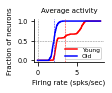

In [70]:
########################################################################
##### Figure 4e #####
########################################################################
plt.figure(figsize = np.array([1.2, 0.6]))
colors2 = ['red', 'blue']
titles2 = ['Young', 'Old']
ax = plt.axes([0, 0, 0.8, 1])
set_plot(ax)
bigMat = []
for j, sig in enumerate(AllCells2):
    bins = np.arange(0, 8, 0.005)
    hist, bin_edges = np.histogram(sig, bins)
    plt.plot(bin_edges[:-1]+(bin_edges[1]-bin_edges[0])/2, np.cumsum(hist/np.sum(hist)), color=colors2[j])
plt.legend(titles2, loc='lower right', bbox_to_anchor=(1, 0), borderpad=0.1, labelspacing=0.2, fontsize=6)
plt.ylabel('Fraction of neurons', fontsize=7)
plt.xlabel('Firing rate (spks/sec)', fontsize=7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(AllCells2[0]), color='red', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(AllCells2[1]), color='blue', linestyle='--', linewidth=0.5)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.5)
plt.title('Average activity', fontsize=7)
plt.savefig('Fig4e_JEDI_CumSumAbs.svg')

test = twoSampleTest(AllCells2[0], AllCells2[1])
p = test['p']
print(f'Difference of means: {r}, p<{p:1.3f}, {len(AllCells2[0])}, {len(AllCells2[1])}')

x=AllCells2[0]
y=AllCells2[1]
test = ksTest(x, y, label='Fig. 4e')
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_fig4e.csv', index=False)
p = test['p']

print(f'Difference of distributions: p<{p:1.3f}')

In [71]:
########################################################################
##### Source data: Figure 4e #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']

for gi, values in enumerate(AllCells2):

    values = np.asarray(values, dtype=float).ravel()

    for neuron_i, value in enumerate(values):

        if np.isfinite(value):
            source_rows.append({
                'Age_group': group_labels[gi],
                'Neuron_index': neuron_i,
                'Average_firing_rate_spikes_per_sec': value
            })

Fig4e_source = pd.DataFrame(source_rows)

Fig4e_source.to_csv(
    'Fig4e_source_data.csv',
    index=False
)

## Figure 4f
The average firing rate per mouse

{'Comparison': '', 'Group 1': 'Group1', 'Group 2': 'Group2', 'n1': 5, 'n2': 4, 'mean1': 3.180688124960363, 'SD1': 1.4344335759789717, 'median1': 2.286097685522427, 'Q1_1': 2.283519930783399, 'Q3_1': 3.6183772793123623, 'mean2': 2.1368504643624684, 'SD2': 0.14247149023594655, 'median2': 2.1915805198029794, 'Q1_2': 2.1004014587898845, 'Q3_2': 2.2280295253755638, 'test': "Welch's t-test", 'statistic': 1.6172464716590431, 'p': 0.1794258115053957}: 0.18


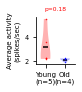

In [72]:
########################################################################
##### Figure 4f #####
########################################################################
plt.figure(figsize=[1.8, 2.2])
titles2 = ['Young', 'Old']
for condition in range(1):
    ax = plt.axes([0.7, 0.65- 0.65*condition, 0.3, 0.3])
    set_plot(ax)
    colors=['red', 'blue']
    nSample = []
    for i in [0,1]:
        inds = np.arange(N) if i==0 else np.arange(N, MeanSig.shape[0], 1)
        vp = plt.violinplot(MeanSig[inds], [i], showmeans=True, showextrema=False, widths=0.5)

        for pc in vp['bodies']:
            pc.set_facecolor(colors[i])
        vp['cmeans'].set_color('black')
        plt.plot(i*np.ones(len(inds)), MeanSig[inds], '.', color=colors[i], markersize=1)
        nSample.append(len(inds))
    plt.xlim([-0.5, 1.5])
    plt.xticks([0, 1], labels=[f'Young\n(n={nSample[0]})', f'Old\n(n={nSample[1]})'], fontsize=7)
    plt.ylabel(f'Average activity\n(spikes/sec)', fontsize=7)
    x = MeanSig[:N]
    y = MeanSig[N:]

    test = twoSampleTest(x,y)
    p=test['p']
    print(f'{test}: {p:1.2f}')
    df = pd.DataFrame([test])
    df.to_csv(f'posthoc_statistics_fig4f{i}.csv', index=False)
    
    plt.title(f'p={p:1.2f}', fontsize=6, color='red')
plt.savefig('JEDI_AbsFR.svg')

In [73]:
########################################################################
##### Source data: Figure 4f #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']

for i, group in enumerate(group_labels):

    inds = (
        np.arange(N)
        if i == 0
        else np.arange(N, MeanSig.shape[0])
    )

    for mouse_index in inds:

        value = MeanSig[mouse_index]

        if np.isfinite(value):
            source_rows.append({
                'Age_group': group,
                'Mouse_index': int(mouse_index),
                'Average_firing_rate_spikes_per_sec': value
            })


Fig4f_source = pd.DataFrame(source_rows)

Fig4f_source.to_csv(
    'Fig4f_source_data.csv',
    index=False
)

## Run this first before Figure S4a-d

In [74]:
##### Run this first for Figure S4a-d
fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2

AllCells=[]
MeanSig = np.array([])
for group in range(2):
    allCells = []
    for subject in JEDI_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
       
        trials_list = []
        choices = trial_data['choice']
        pre_choices = np.hstack(([0], choices[:-1]))
        for ci in range(2):
            if ci == 0:
                trials = np.flatnonzero(choices*pre_choices<0)
            elif ci == 1:
                trials = np.flatnonzero(choices*pre_choices>0)
            trials_list.append(trials)        
        
        trials_list = np.array(trials_list, dtype=object)
        SNR = neural_data['SNR']
        cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))
      
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  
                                                                window_length = wl, smooth_window=sw, offset = off, trials_list = trials_list, 
                                                                FrameRate = fr, zScore=0, key='rates', plot=False)   
        zsignal = np.full_like(signal, np.nan)
        for ci in range(len(cells)):
            my = np.nanmean(signal[:, ci, :])
            sy = np.nanstd(signal[:,ci,:])
            zsignal[:, ci,: ] = (signal[:, ci, :] - my)/sy

        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr
        tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))

        MeanSig = np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1) if len(MeanSig)==0 else np.vstack((MeanSig,np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1)))
        a = (np.mean(zsignal[0,:,tind]-zsignal[1,:,tind], axis=0).argsort())
        allCells = zsignal if len(allCells)==0 else np.concatenate((allCells,zsignal), axis=1)
        
    AllCells.append(allCells)

## Figure S4a
Mean switch versus stay population activity

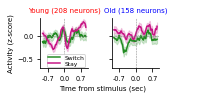

In [75]:
########################################################################
##### Figure S4a #####
########################################################################
titles = ['Young', 'Old']
colors2 = ['red', 'blue']
plt.figure(figsize = np.array([2.2, 2.8]))
colors = ['forestgreen', 'mediumvioletred']
for j, allCells in enumerate(AllCells):
    ax = plt.axes([j*0.45, 0.4, 0.3, 0.25])
    set_plot(ax)
    for i, sig in enumerate(allCells):
        meanCells = np.nanmean(sig, axis=0)
        stdCells = np.nanstd(sig, axis=0)/np.sqrt(sig.shape[0])
        plt.fill_between(time, meanCells-stdCells, meanCells+stdCells, color=colors[i], alpha=0.2)
        plt.plot(time, meanCells, color=colors[i])
    plt.xticks(np.arange(-0.7, 0.71, 0.7), labels=['-0.7', '0.0', '0.7'])
    plt.ylim(-0.7, 0.4)
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    if j==0:
        plt.ylabel('Activity (z-score)', fontsize=7)
    else:
        ax.set_yticklabels([])
    plt.title(f'{titles[j]} ({len(sig)} neurons)', color=colors2[j], fontsize=7)
    if j==0:
        plt.legend(['Switch', 'Stay'], loc='lower right', bbox_to_anchor=(1.0, -0.04), borderpad=0.1, labelspacing=0.2, fontsize=6)
ax = plt.axes([0, 0.4, 1, 0.25])
ax.set_axis_off()
plt.text(0.12, -0.44, 'Time from stimulus (sec)', fontsize=7)

plt.savefig('FigS4a_JEDIz_youngVSold.svg')

In [76]:
########################################################################
##### Source data: Figure S4a #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']
condition_labels = ['Switch', 'Stay']

for gi, allCells in enumerate(AllCells):

    # allCells[0] = Switch neurons x time
    # allCells[1] = Stay neurons x time
    for ci, sig in enumerate(allCells):

        sig = np.asarray(sig, dtype=float)

        for neuron_i in range(sig.shape[0]):

            for ti, t in enumerate(time):

                source_rows.append({
                    'Age_group': group_labels[gi],
                    'Condition': condition_labels[ci],
                    'Neuron_index': neuron_i,
                    'Time_from_stimulus_sec': t,
                    'Activity_zscore': sig[neuron_i, ti]
                })


FigS4a_source = pd.DataFrame(source_rows)

FigS4a_source.to_csv(
    'FigS4a_source_data.csv',
    index=False
)

## Figure S4b
Mean ITI switch versus stay activity per mouse

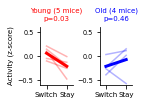

In [77]:
########################################################################
##### Figure S4b #####
########################################################################

set_rcParams()

N=5
time = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
colors2 = ['red', 'blue']
titles = ['Young', 'Old']
plt.figure(figsize = np.array([1.5, 0.8]))
for i in [0,1]:
    inds = np.arange(N) if i==0 else np.arange(N, MeanSig.shape[0],1)
    ax = plt.axes([0.55*i, 0.07, 0.3, 1])
    set_plot(ax)

    plt.plot(MeanSig[inds,:].T, color=colors2[i], alpha=0.3)
    plt.plot(np.nanmean(MeanSig[inds,:],axis=0), color=colors2[i], linewidth=3)

    x = MeanSig[inds,0]
    y = MeanSig[inds,1]
    test = pairedTest(x, y)  
    p=test['p']
    df = pd.DataFrame([test])
    df.to_csv(f'posthoc_statistics_figS4d{i}.csv', index=False)
    
    plt.ylim([-0.6, 0.6])
    plt.xlim(-0.3, 1.3)
    plt.xticks([0, 1], labels=['Switch', 'Stay'], fontsize=7)
    if i==0:
        plt.ylabel('Activity (z-score)', fontsize=7)
    plt.title(f'{titles[i]} ({len(inds)} mice)\np={p:1.2f}', pad=6, linespacing=1.5, fontsize=7, color=colors2[i])
plt.savefig('FigS4b_JEDI_youngVSoldDelta.svg')

In [78]:
########################################################################
##### Source data: Figure S4b #####
########################################################################

source_rows = []

N = 5
group_labels = ['Young', 'Old']

for i, group in enumerate(group_labels):

    inds = (
        np.arange(N)
        if i == 0
        else np.arange(N, MeanSig.shape[0])
    )

    for mouse_index in inds:

        source_rows.append({
            'Age_group': group,
            'Mouse_index': int(mouse_index),
            'Switch_activity_zscore': MeanSig[mouse_index, 0],
            'Stay_activity_zscore': MeanSig[mouse_index, 1],
            'Switch_minus_stay_zscore': (
                MeanSig[mouse_index, 0] -
                MeanSig[mouse_index, 1]
            )
        })


FigS4b_source = pd.DataFrame(source_rows)

FigS4b_source.to_csv(
    'FigS4b_source_data.csv',
    index=False
)

## Figure S4c
JEDI heatmap of the mean ITI (switch-stay) activity

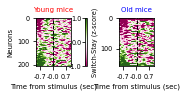

In [79]:
########################################################################
##### Figure S4c #####
########################################################################
set_rcParams()
    
titles = ['Young mice', 'Old mice']
colors = ['red', 'blue']
time = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
plt.figure(figsize=np.array([2.4, 2.8])*1)
for gi, allCells in enumerate(AllCells):    
    #ax = plt.axes([gi*0.6, 0.5, 0.33-0.13*gi, 0.24])
    
    ax = plt.axes([gi*0.48, 0, 0.33-0.13*gi, 0.24])
    z = allCells[0]-allCells[1]

    half_ind = 60
    ms = np.nanmean(z[:, :half_ind], axis=1)
    inds = ms.argsort()      
    y = z[inds,:]
    im = plt.imshow(y, cmap='PiYG', aspect='auto', vmin=-1.0, vmax=1.0)

#     peak_inds = np.argmax(z, axis=1)
#     inds = peak_inds.argsort()
#     im = plt.imshow(z[inds,:], cmap='PiYG', aspect='auto', vmin=-1.5, vmax=1.5)

    plt.axvline(z.shape[1]/2-0.5, 0, z.shape[0], color='black', linestyle='--', linewidth = 1)
    tind = np.arange(30, z.shape[1], 100)
    plt.xticks(tind, labels = [f'{t:1.1f}' for t in time[tind]])
    plt.xlabel('Time from stimulus (sec)', fontsize=7) 

    if gi==0:
        plt.ylabel('Neurons', fontsize=7)
        cbar = plt.colorbar(im, pad=0.25, label='Switch-Stay (z-score)', 
                            ticks=[-1.0, 0, 1.0], format='%1.1f')
        cax = cbar.ax
        cax.yaxis.set_ticks_position('left')
        cax.tick_params(axis='y', pad=0.01)
    plt.title(titles[gi], fontsize=7, color=colors[gi])

plt.savefig('FigS4c_JEDI_PopulationHeatmapZscore.svg')
plt.show()

In [80]:
########################################################################
##### Source data: Figure S4c #####
########################################################################

source_rows = []

group_labels = ['Young mice', 'Old mice']

for gi, allCells in enumerate(AllCells):

    # neurons x time
    z = allCells[0] - allCells[1]

    # Same sorting used in the figure
    half_ind = 60
    ms = np.nanmean(z[:, :half_ind], axis=1)
    inds = ms.argsort()

    # Sorted matrix shown in the heatmap
    y = z[inds, :]

    for sorted_rank, original_neuron_index in enumerate(inds):

        for ti, t in enumerate(time):

            source_rows.append({
                'Age_group': group_labels[gi],
                'Sorted_neuron_rank': sorted_rank + 1,
                'Original_neuron_index': int(original_neuron_index),
                'Time_from_stimulus_sec': t,
                'Switch_minus_stay_zscore': y[sorted_rank, ti]
            })


FigS4c_source = pd.DataFrame(source_rows)

FigS4c_source.to_csv(
    'FigS4c_source_data.csv',
    index=False
)

## Figure S4d
Distribution of the mean ITI (switch-stay) activity

1.1979365821833909e-05 208 158
p<0.000


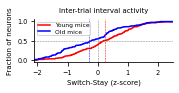

In [81]:
########################################################################
##### Figure S4d #####
########################################################################

##### Cumulative distribution of delta
plt.figure(figsize = np.array([2.4, 0.6]))
colors2 = ['red', 'blue']

ax = plt.axes([0, 0, 0.8, 1])
set_plot(ax)
bigMat = []
for j, allCells in enumerate(AllCells):
    sig = allCells[0] - allCells[1]

    tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))
    fracSwitch = []
    for ci in range(sig.shape[0]):
        fracSwitch.append(np.nanmean(sig[ci, tind]))
    bigMat.append(fracSwitch)
    bins = np.arange(-2.5, 5, 0.005)
#    bins = np.arange(-2.5, 5, 0.1)
    hist, bin_edges = np.histogram(fracSwitch, bins)
    plt.plot(bin_edges[:-1]+(bin_edges[1]-bin_edges[0])/2, np.cumsum(hist/np.sum(hist)), color=colors2[j])
#    plt.plot(bin_edges[:-1]+(bin_edges[1]-bin_edges[0])/2, (hist/np.sum(hist)), color=colors2[j])
plt.legend(titles, loc='upper left', bbox_to_anchor=(0, 1), borderpad=0.1, labelspacing=0.2, fontsize=6)
plt.xlim(-2.1,2.5)
plt.ylabel('Fraction of neurons', fontsize=7)
plt.xlabel('Switch-Stay (z-score)', fontsize=7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(bigMat[0],0), color='red', linestyle='--', linewidth=0.5)
plt.axvline(np.nanmean(bigMat[1],0), color='blue', linestyle='--', linewidth=0.5)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.5)
plt.title('Inter-trial interval activity', fontsize=7)
plt.savefig('FigS4d_JEDI_CumSum.svg')

r3 = twoSampleTest(bigMat[0], bigMat[1])
print(r3['p'], len(bigMat[0]), len(bigMat[1]))

x=bigMat[0]
y=bigMat[1]
test = ksTest(x, y, label='Fig. S4d')
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_figS4d.csv', index=False)
p = test['p']

print(f'p<{p:1.3f}')

In [82]:
########################################################################
##### Source data: Figure S4d #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']

# ITI window used in the figure
tind = np.flatnonzero(
    (time >= -0.60) &
    (time <= -0.30)
)

for gi, allCells in enumerate(AllCells):

    # neurons x time
    sig = allCells[0] - allCells[1]

    for neuron_i in range(sig.shape[0]):

        iti_mean = np.nanmean(
            sig[neuron_i, tind]
        )

        source_rows.append({
            'Age_group': group_labels[gi],
            'Neuron_index': neuron_i,
            'ITI_window_start_sec': -0.60,
            'ITI_window_end_sec': -0.30,
            'Mean_switch_minus_stay_zscore': iti_mean
        })


FigS4d_source = pd.DataFrame(source_rows)

FigS4d_source.to_csv(
    'FigS4d_source_data.csv',
    index=False
)

## Figure S4e
Raw firing rates heat map

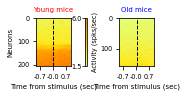

In [83]:
#### Run this first for Figure 4h, i, j
fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2
AllCells=[]
AllCells2=[]
MeanSig = []
for group in range(2):
    Spk_counts = []
    allCells = []
    allCells2 = []
    for subject in JEDI_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
    
        trials_list = np.array([np.flatnonzero(trial_data['choice'])], dtype=object)
        
        SNR = neural_data['SNR']
        cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))
        
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  
                                                                window_length = wl, smooth_window=sw, offset = off, trials_list = trials_list, 
                                                                FrameRate = fr, zScore=0, key='rates', plot=False)   

        #Stimulus onset aligned raw firing rates
        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr
        tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))
        allCells = signal if len(allCells)==0 else np.concatenate((allCells,signal), axis=1)

        #Raw firing rates across a whole imaging session
        signal = neural_data['rates'][cells,:]
        allCells2 = np.nanmean(signal, -1) if len(allCells2)==0 else np.concatenate((allCells2, np.nanmean(signal, -1)), axis=0)
        MeanSig.append(np.nanmean(signal))
        
    AllCells.append(allCells)
    AllCells2.append(allCells2)
MeanSig = np.array(MeanSig)


########################################################################
##### Figure S4e #####
########################################################################
set_rcParams()
    
N=5
titles = ['Young mice', 'Old mice']
colors = ['red', 'blue']
conditions = ['Switch', 'Stay']
time = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
plt.figure(figsize=np.array([2.4, 2.8]))
for condition in range(AllCells[0].shape[0]):
    for gi, allCells in enumerate(AllCells):    
        ax = plt.axes([gi*0.48, 0.5-condition*0.5, 0.33-0.13*gi, 0.24])
        z = allCells[condition]
        
        half_ind = round(z.shape[1]/2)
        ms = np.nanmean(z[:, :half_ind], axis=-1)
        inds2 = ms.argsort()  
        inds = []
        for ii in inds2:
            if not np.isnan(ms[ii]):
                inds.append(ii) 
        im = plt.imshow(z[inds,:], cmap='Wistia', aspect='auto', vmin=1.5, vmax=6)
#        im = plt.imshow(z[inds,:], cmap='Wistia', aspect='auto', vmin=0.5, vmax=8)
        plt.axvline(z.shape[1]/2-0.5, 0, z.shape[0], color='black', linestyle='--', linewidth = 1)
        tind = np.arange(30, z.shape[1], 100)
        plt.xticks(tind, labels = [f'{t:1.1f}' for t in time[tind]])
        if gi==0:
            plt.ylabel('Neurons', fontsize=7)
        plt.xlabel('Time from stimulus (sec)', fontsize=7) 

        if gi==0:
            cbar = plt.colorbar(im, pad=0.25, label='Activity (spks/sec)', ticks=[1.5, 6], format='%1.1f')
            cax = cbar.ax
            cax.yaxis.set_ticks_position('left')
            cax.tick_params(axis='y', pad=0.01)
        plt.title(titles[gi], fontsize=7, color=colors[gi])

plt.savefig('FigS4e_JEDI_PopulationHeatmap.svg')

In [84]:
########################################################################
##### Source data: Figure S4e #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']

# Use labels appropriate to the actual number of conditions
if AllCells[0].shape[0] == 2:
    condition_labels = ['Switch', 'Stay']
else:
    condition_labels = ['All_trials']

for condition in range(AllCells[0].shape[0]):

    for gi, allCells in enumerate(AllCells):

        # neurons x time
        z = allCells[condition]

        # Same sorting used in the plotted heatmap
        half_ind = round(z.shape[1] / 2)
        ms = np.nanmean(z[:, :half_ind], axis=1)

        # Sort by mean activity and exclude neurons with NaN mean
        inds2 = ms.argsort()
        inds = [
            ii for ii in inds2
            if np.isfinite(ms[ii])
        ]

        # Sorted matrix actually plotted
        y = z[inds, :]

        for sorted_rank, original_neuron_index in enumerate(inds):

            for ti, t in enumerate(time):

                source_rows.append({
                    'Age_group': group_labels[gi],
                    'Condition': condition_labels[condition],
                    'Sorted_neuron_rank': sorted_rank + 1,
                    'Original_neuron_index': int(original_neuron_index),
                    'Time_from_stimulus_sec': t,
                    'Firing_rate_spikes_per_sec': y[sorted_rank, ti]
                })


FigS4e_source = pd.DataFrame(source_rows)

FigS4e_source.to_csv(
    'FigS4e_source_data.csv',
    index=False
)

## Figure S4f
Baseline-subtracted firing rates, peak aligned heat map

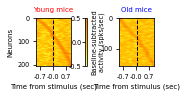

In [85]:
########################################################################
##### Figure S4f #####
########################################################################
set_rcParams()

##### Run this first for Figure 4d, e, f, g
fr=147
offset_time = 1
total_time = 2
sw_time = 0.2
wl = total_time*fr
off = offset_time*fr
sw = int(sw_time*fr)
time = (np.arange(wl - sw + 1) - off)/fr + (sw-1)/fr/2

AllCells=[]
MeanSig = np.array([])
for group in range(2):
    allCells = []
    for subject in JEDI_subjects[group]:
        trial_data = read_behavioral_data(subject)
        neural_data, FrameNum, TrialNum = read_cell_data(subject)
       
        trials_list = []
        choices = trial_data['choice']
        pre_choices = np.hstack(([0], choices[:-1]))

        trials_list = np.array([np.flatnonzero(trial_data['choice'])], dtype=object)

        SNR = neural_data['SNR']
        cells = np.flatnonzero((SNR>2)*(neural_data['iscell'][:,0]))
      
        mean_sig, sd_sig, signal, zNS = plot_population_condition(trial_data, neural_data, FrameNum, TrialNum, cells = cells, align_to = 'stimOn',  
                                                                window_length = wl, smooth_window=sw, offset = off, trials_list = trials_list, 
                                                                FrameRate = fr, zScore=0, key='rates', plot=False) 
        zsignal = np.full_like(signal, np.nan)
        for ci in range(len(cells)):
            my = np.nanmean(signal[:, ci, :])
            sy = np.nanstd(signal[:,ci,:])
#            zsignal[:, ci,: ] = (signal[:, ci, :] - my)/sy
            zsignal[:, ci,: ] = (signal[:, ci, :] - my)

        time = (np.arange(signal.shape[2]) - off)/fr + (sw-1)/2/fr
        tind = np.flatnonzero((time>=-0.60)*(time<=-0.3))

        MeanSig = np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1) if len(MeanSig)==0 else np.vstack((MeanSig,np.mean(np.mean(zsignal[:,:,tind], axis=-1),axis=-1)))
        allCells = zsignal if len(allCells)==0 else np.concatenate((allCells,zsignal), axis=1)
        
    AllCells.append(allCells)

########################################################################
##### Figure S4f Plot#####
########################################################################
set_rcParams()
    
titles = ['Young mice', 'Old mice']
colors = ['red', 'blue']
time = (np.arange(AllCells[0].shape[2]) - off)/fr + (sw-1)/2/fr
plt.figure(figsize=np.array([2.4, 2.8])*1)
for condition in range(AllCells[0].shape[0]):
    for gi, allCells in enumerate(AllCells):    
        ax = plt.axes([gi*0.48, 0, 0.33-0.13*gi, 0.24])
        z = allCells[condition]
                
        peak_inds = np.argmax(z, axis=1)
        inds = peak_inds.argsort()
        im = plt.imshow(z[inds,:], cmap='Wistia', aspect='auto', vmin=-0.5, vmax=0.5)
        plt.axvline(z.shape[1]/2-0.5, 0, z.shape[0], color='black', linestyle='--', linewidth = 1)
        tind = np.arange(30, z.shape[1], 100)
        plt.xticks(tind, labels = [f'{t:1.1f}' for t in time[tind]])
        plt.xlabel('Time from stimulus (sec)', fontsize=7) 

        if gi==0:
            plt.ylabel('Neurons', fontsize=7)
            cbar = plt.colorbar(im, pad=0.25, label=f'Baseline-subtracted\nactivity (spks/sec)', 
                                ticks=[-0.5, 0, 0.5,1], format='%1.1f')
            cax = cbar.ax
            cax.yaxis.set_ticks_position('left')
            cax.tick_params(axis='y', pad=0.01)
        plt.title(titles[gi], fontsize=7, color=colors[gi])

plt.savefig('FigS4f_JEDI_PopulationHeatmapMeanSubtracted.svg')

In [86]:
########################################################################
##### Source data: Figure S4f #####
########################################################################

source_rows = []

group_labels = ['Young', 'Old']

for gi, allCells in enumerate(AllCells):

    # There is one condition in the preprocessing above
    for condition in range(allCells.shape[0]):

        # neurons x time
        z = allCells[condition]

        # Same peak-based sorting used in the figure
        peak_inds = np.argmax(z, axis=1)
        inds = peak_inds.argsort()

        # Sorted matrix actually displayed
        y = z[inds, :]

        for sorted_rank, original_neuron_index in enumerate(inds):

            for ti, t in enumerate(time):

                source_rows.append({
                    'Age_group': group_labels[gi],
                    'Sorted_neuron_rank': sorted_rank + 1,
                    'Original_neuron_index': int(original_neuron_index),
                    'Peak_time_sec': time[peak_inds[original_neuron_index]],
                    'Time_from_stimulus_sec': t,
                    'Baseline_subtracted_firing_rate_spikes_per_sec':
                        y[sorted_rank, ti]
                })


FigS4f_source = pd.DataFrame(source_rows)

FigS4f_source.to_csv(
    'FigS4f_source_data.csv',
    index=False
)

## Figure 4h, S5
This block includes Home-cage control mice c-Fos analysis.

In [87]:
SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 4,   ['experiment'], ['cFos']),
    combine_criteria(15, 24, ['experiment'], ['cFos']),
] 
cFOS_subjects, cFOS_group_names, cFOS_ages, cFOS_sexes, _, = group_subjects(group_criteria, SubjectDB)

Ages =[]
for ai, age in enumerate(cFOS_ages):
    Ages.append([np.round(np.nanmin(age)), np.round(np.nanmax(age))])
    print(f'c-Fos young_mice: {cFOS_subjects[ai]}\nAge: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

c-Fos young_mice: ['Mouse119' 'Mouse120' 'Mouse121' 'Mouse122']
Age: [2.0, 2.0]
c-Fos young_mice: ['Mouse123' 'Mouse124' 'Mouse125' 'Mouse126']
Age: [19.0, 19.0]


In [88]:
df =  pd.read_csv(Path(cFos,"HomeCageCfos.csv"))

# Pool multiple ROIs from the same mouse and region
summary = (
    df.groupby(["Region", "MouseID"], as_index=False)
      .agg({
          "Area µm^2": "sum",
          "Num Fos": "sum",
          "Num Fos-": "sum",
          "Num NeuN: Fos": "sum",
          "Num NeuN: Fos-": "sum"
      })
)

# Total NeuN+ neurons
summary["Num NeuN"] = (
    summary["Num NeuN: Fos"] +
    summary["Num NeuN: Fos-"]
)

# Total c-Fos+ cells
summary["Num cFos"] = (
    summary["Num Fos"] +
    summary["Num NeuN: Fos"]
)

# Fraction of NeuN+ neurons that are c-Fos+
summary["cFos_fraction"] = (
    summary["Num NeuN: Fos"] /
    summary["Num NeuN"]
)

# NeuN+ neuronal density (cells/mm²)
summary["NeuN_density_per_mm2"] = (
    summary["Num NeuN"] /
    summary["Area µm^2"] * 1e6
)

# Total c-Fos+ cell density (cells/mm²)
summary["cFos_density_per_mm2"] = (
    summary["Num cFos"] /
    summary["Area µm^2"] * 1e6
)

## Figure 4h left
c-Fos quantification in PPC

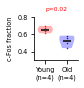

In [89]:
########################################################################
##### Figure S4h left #####
######################################################################### 
#Plot c-Fos+ fraction of NeuN+ neurons in PPC
plt.figure(figsize=[3, 0.6])
axe = plt.axes([0, 0, 0.2, 1])
set_plot(axe)
Region = 'PPC'
x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
"cFos_fraction"].to_numpy() #c-Fos+ fraction of NeuN+ neurons
y = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
"cFos_fraction"].to_numpy()
for group in range(2):
    if group==0: 
        fraction = x
        color = 'red'
    else:
        fraction = y
        color = 'blue'

    vp = plt.violinplot(fraction, [group], showmeans=True, showextrema=False, widths=0.7)
    for pc in vp['bodies']:
        pc.set_facecolor(color)
    vp['cmeans'].set_color('black')

    plt.plot(group*np.ones(len(fraction)), fraction, '.', color=color, markersize=1)

plt.xlim([-0.5, 1.5])
plt.xticks(range(2), labels=[f'Young\n(n={len(x)})', f'Old\n(n={len(y)})'])
plt.ylabel('c-Fos fraction')
plt.ylim([0.3, 0.8])

test = twoSampleTest(x,y)
p=test['p']
df = pd.DataFrame([test])
df.to_csv(f'posthoc_statistics_fig4hL{i}.csv', index=False)
plt.title(f'p={p:1.2f}', fontsize=6, color='red')

plt.savefig('Fig4hL_BaselineIHC.svg')

In [90]:
########################################################################
##### Source data: Figure S4h left #####
########################################################################

Region = 'PPC'

source_rows = []

for group_label, subjects in zip(
        ['Young', 'Old'],
        [cFOS_subjects[0], cFOS_subjects[1]]):

    group_data = summary.loc[
        (summary["Region"] == Region) &
        (summary["MouseID"].isin(subjects)),
        ["MouseID", "cFos_fraction"]
    ]

    for _, row in group_data.iterrows():
        source_rows.append({
            'Mouse_ID': row["MouseID"],
            'Age_group': group_label,
            'Region': Region,
            'cFos_positive_fraction_of_NeuN_neurons': row["cFos_fraction"]
        })


FigS4hLeft_source = pd.DataFrame(source_rows)

FigS4hLeft_source.to_csv(
    'FigS4hLeft_source_data.csv',
    index=False
)

## Figure 4h right
c-Fos quantification in L2/3 PPC

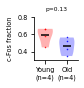

In [91]:
########################################################################
##### Figure S4h right #####
########################################################################
## Plot c-Fos+ fraction of NeuN+ neurons in L2/3 PPC
plt.figure(figsize=[3, 0.6])
axe = plt.axes([0, 0, 0.2, 1])
set_plot(axe)

Region = 'PPCL23'
x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
"cFos_fraction"].to_numpy() #c-Fos+ fraction of NeuN+ neurons
y = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
"cFos_fraction"].to_numpy()
for group in range(2):
    if group==0: 
        fraction = x
        color = 'red'
    else:
        fraction = y
        color = 'blue'

    vp = plt.violinplot(fraction, [group], showmeans=True, showextrema=False, widths=0.7)
    for pc in vp['bodies']:
        pc.set_facecolor(color)
    vp['cmeans'].set_color('black')

    plt.plot(group*np.ones(len(fraction)), fraction, '.', color=color, markersize=1)

plt.xlim([-0.5, 1.5])
plt.xticks(range(2), labels=[f'Young\n(n={len(x)})', f'Old\n(n={len(y)})'])
plt.ylabel('c-Fos fraction')
plt.ylim([0.3, 0.8])

test = twoSampleTest(x,y)
p=test['p']
df = pd.DataFrame([test])
df.to_csv(f'posthoc_statistics_fig4hRight{i}.csv', index=False)

plt.title(f'p={p:1.2f}', fontsize=6, color='black')
plt.savefig('Fig4hR_BaselineIHC_L23.svg')

In [92]:
########################################################################
##### Source data: Figure S4h right #####
########################################################################

Region = 'PPCL23'

source_rows = []

for group_label, subjects in zip(
        ['Young', 'Old'],
        [cFOS_subjects[0], cFOS_subjects[1]]):

    group_data = summary.loc[
        (summary["Region"] == Region) &
        (summary["MouseID"].isin(subjects)),
        ["MouseID", "cFos_fraction"]
    ]

    for _, row in group_data.iterrows():
        source_rows.append({
            'Mouse_ID': row["MouseID"],
            'Age_group': group_label,
            'Region': Region,
            'cFos_positive_fraction_of_NeuN_neurons': row["cFos_fraction"]
        })


FigS4hRight_source = pd.DataFrame(source_rows)

FigS4hRight_source.to_csv(
    'FigS4hRight_source_data.csv',
    index=False
)

## Figure S5b top
c-Fos quantification in PPC

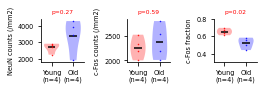

In [93]:
########################################################################
##### Figure S5b top (PPC) #####
#######################################################################
plt.figure(figsize=[3, 0.6])
y_labels = ['NeuN counts (/mm2)','c-Fos counts (/mm2)', 'c-Fos fraction']
results=[]
Region = "PPC"
for i in range(3):
    if i==0:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "NeuN_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "NeuN_density_per_mm2"].to_numpy()
    elif i==1:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_density_per_mm2"].to_numpy()
    elif i==2:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_fraction"].to_numpy() #c-Fos+ fraction of NeuN+ neurons
        y = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_fraction"].to_numpy()
    
    axe = plt.axes([0.4*i,0, 0.2, 1])
    set_plot(axe)
    
    for group in range(2):
        if group==0: 
            fraction = x
            color = 'red'
        else:
            fraction = y
            color = 'blue'

        vp = plt.violinplot(fraction, [group], showmeans=True, showextrema=False, widths=0.7)
        for pc in vp['bodies']:
            pc.set_facecolor(color)
        vp['cmeans'].set_color('black')

        plt.plot(group*np.ones(len(fraction)), fraction, '.', color=color, markersize=1)
    
    plt.xlim([-0.5, 1.5])
    plt.xticks(range(2), labels=[f'Young\n(n={len(x)})', f'Old\n(n={len(y)})'])
    plt.ylabel(y_labels[i])
    if i==2:
        plt.ylim([0.3, 0.8])

    test = twoSampleTest(x,y)
    p = test['p']
    results.append(test)
    plt.title(f'p={p:1.2f}', fontsize=6, color='red')

plt.savefig('FigS5bTop_BaselineIHC.svg')
df = pd.DataFrame(results)
df.to_csv(f'posthoc_statistics_figS5bTop.csv', index=False)

In [94]:
########################################################################
##### Source data: Figure S5b top (PPC) #####
########################################################################

Region = 'PPC'

source_rows = []

for group_label, subjects in zip(
        ['Young', 'Old'],
        [cFOS_subjects[0], cFOS_subjects[1]]):

    group_data = summary.loc[
        (summary["Region"] == Region) &
        (summary["MouseID"].isin(subjects)),
        [
            "MouseID",
            "NeuN_density_per_mm2",
            "cFos_density_per_mm2",
            "cFos_fraction"
        ]
    ]

    for _, row in group_data.iterrows():

        source_rows.append({
            'Mouse_ID': row['MouseID'],
            'Age_group': group_label,
            'Region': Region,
            'NeuN_density_per_mm2': row['NeuN_density_per_mm2'],
            'cFos_density_per_mm2': row['cFos_density_per_mm2'],
            'cFos_positive_fraction_of_NeuN_neurons': row['cFos_fraction']
        })


FigS5bTop_source = pd.DataFrame(source_rows)

FigS5bTop_source.to_csv(
    'FigS5bTop_source_data.csv',
    index=False
)

## Figure S5b middle
c-Fos quantification in Auditory/Temporal Assocaition Cortex

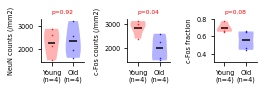

In [95]:
########################################################################
##### Figure S5b top (ADU/TE) #####
#######################################################################
plt.figure(figsize=[3, 0.6])
y_labels = ['NeuN counts (/mm2)','c-Fos counts (/mm2)', 'c-Fos fraction']
results=[]
Region = "AUD"
for i in range(3):
    if i==0:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "NeuN_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "NeuN_density_per_mm2"].to_numpy()
    elif i==1:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_density_per_mm2"].to_numpy()
    elif i==2:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_fraction"].to_numpy() #c-Fos+ fraction of NeuN+ neurons
        y = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_fraction"].to_numpy()
    
    axe = plt.axes([0.4*i,0, 0.2, 1])
    set_plot(axe)
    
    for group in range(2):
        if group==0: 
            fraction = x
            color = 'red'
        else:
            fraction = y
            color = 'blue'

        vp = plt.violinplot(fraction, [group], showmeans=True, showextrema=False, widths=0.7)
        for pc in vp['bodies']:
            pc.set_facecolor(color)
        vp['cmeans'].set_color('black')

        plt.plot(group*np.ones(len(fraction)), fraction, '.', color=color, markersize=1)
    
    plt.xlim([-0.5, 1.5])
    plt.xticks(range(2), labels=[f'Young\n(n={len(x)})', f'Old\n(n={len(y)})'])
    plt.ylabel(y_labels[i])
    if i==2:
        plt.ylim([0.3, 0.8])

    test = twoSampleTest(x,y)
    p = test['p']
    results.append(test)
    plt.title(f'p={p:1.2f}', fontsize=6, color='red')

plt.savefig('FigS5bMiddle_BaselineIHC.svg')
df = pd.DataFrame(results)
df.to_csv(f'posthoc_statistics_figS5bMiddle.csv', index=False)

In [96]:
########################################################################
##### Source data: Figure S5b AUD #####
########################################################################

Region = 'AUD'

source_rows = []

for group_label, subjects in zip(
        ['Young', 'Old'],
        [cFOS_subjects[0], cFOS_subjects[1]]):

    group_data = summary.loc[
        (summary["Region"] == Region) &
        (summary["MouseID"].isin(subjects)),
        [
            "MouseID",
            "NeuN_density_per_mm2",
            "cFos_density_per_mm2",
            "cFos_fraction"
        ]
    ]

    for _, row in group_data.iterrows():
        source_rows.append({
            'Mouse_ID': row['MouseID'],
            'Age_group': group_label,
            'Region': Region,
            'NeuN_density_per_mm2': row['NeuN_density_per_mm2'],
            'cFos_density_per_mm2': row['cFos_density_per_mm2'],
            'cFos_positive_fraction_of_NeuN_neurons': row['cFos_fraction']
        })


FigS5bAUD_source = pd.DataFrame(source_rows)

FigS5bAUD_source.to_csv(
    'FigS5b_AUD_source_data.csv',
    index=False
)

## Figure S5b bottome
c-Fos quantification in Hippocampal Dentate Gyrus Granullar Cell layer

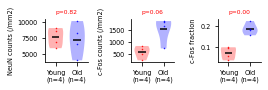

In [97]:
########################################################################
##### Figure S5b Bottom (DG) #####
#######################################################################
plt.figure(figsize=[3, 0.6])
y_labels = ['NeuN counts (/mm2)','c-Fos counts (/mm2)', 'c-Fos fraction']
results=[]
Region = "DG"
for i in range(3):
    if i==0:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "NeuN_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "NeuN_density_per_mm2"].to_numpy()
    elif i==1:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_density_per_mm2"].to_numpy() #total c-Fos+ counts
        y =  summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_density_per_mm2"].to_numpy()
    elif i==2:
        x = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[0])),
    "cFos_fraction"].to_numpy() #c-Fos+ fraction of NeuN+ neurons
        y = summary.loc[(summary["Region"] == Region) & (summary["MouseID"].isin(cFOS_subjects[1])),
    "cFos_fraction"].to_numpy()
    
    axe = plt.axes([0.4*i,0, 0.2, 1])
    set_plot(axe)
    for group in range(2):
        if group==0: 
            fraction = x
            color = 'red'
        else:
            fraction = y
            color = 'blue'

        vp = plt.violinplot(fraction, [group], showmeans=True, showextrema=False, widths=0.7)
        for pc in vp['bodies']:
            pc.set_facecolor(color)
        vp['cmeans'].set_color('black')

        plt.plot(group*np.ones(len(fraction)), fraction, '.', color=color, markersize=1)
    
    plt.xlim([-0.5, 1.5])
    plt.xticks(range(2), labels=[f'Young\n(n={len(x)})', f'Old\n(n={len(y)})'])
    plt.ylabel(y_labels[i])
    
    test = twoSampleTest(x,y)
    p = test['p']
    results.append(test)
    plt.title(f'p={p:1.2f}', fontsize=6, color='red')


df = pd.DataFrame(results)
df.to_csv(f'posthoc_statistics_figS5bBottom_DG.csv', index=False)

plt.savefig('FigS5bBottom_BaselineIHC_DG.svg')

In [98]:
########################################################################
##### Source data: Figure S5b bottom (DG) #####
########################################################################

Region = 'DG'

source_rows = []

for group_label, subjects in zip(
        ['Young', 'Old'],
        [cFOS_subjects[0], cFOS_subjects[1]]):

    group_data = summary.loc[
        (summary["Region"] == Region) &
        (summary["MouseID"].isin(subjects)),
        [
            "MouseID",
            "NeuN_density_per_mm2",
            "cFos_density_per_mm2",
            "cFos_fraction"
        ]
    ]

    for _, row in group_data.iterrows():
        source_rows.append({
            'Mouse_ID': row['MouseID'],
            'Age_group': group_label,
            'Region': Region,
            'NeuN_density_per_mm2': row['NeuN_density_per_mm2'],
            'cFos_density_per_mm2': row['cFos_density_per_mm2'],
            'cFos_positive_fraction_of_NeuN_neurons': row['cFos_fraction']
        })


FigS5cBottom_source = pd.DataFrame(source_rows)

FigS5cBottom_source.to_csv(
    'FigS5cBottom_DG_source_data.csv',
    index=False
)

# Supplementary Figure 6,8
This block includes first cohort of Old ChRmine and Old Jaws optogenetic experiment.

## Load subject database for optogenetic experiment

In [99]:
##### Load subject database and compile mice from control and optogenetic experiments

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 3,   ['experiment', 'genotype'], ['Control', 'WT']),
    combine_criteria(15, 25, ['experiment', 'genotype'], ['Control', 'WT']),
    combine_criteria(15, 25, ['experiment', 'genotype'], ['OldChRmine1', 'WT']),
    combine_criteria(15, 25, ['experiment', 'genotype'], ['OldJaws1', 'WT']),
] 
OldChRminevJaws, Opto_group_names, Opto_ages, Opto_sexes, _ = group_subjects(group_criteria, SubjectDB)


for age in Opto_ages:
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 3.0]
Age: [19.0, 21.0]
Age: [20.0, 20.0]
Age: [19.0, 20.0]


### ITI distribution of optogenetic experiment

In [100]:
##### Opto trial ITI distribution
all_time = np.array(Get_timeInfo(OldChRminevJaws[2:], MaxDay=16), dtype=object)
bigmat=[]
ti=1 #0 for session duration, 1 for iti length
for at in all_time:
    bigmat = at[:,:,ti] if len(bigmat)==0 else np.concatenate((bigmat, at[:,:,ti]), axis=0)
print('Mean ITI, SD ITI, min ITI, max ITI')
print(np.nanmean(bigmat),np.nanstd(bigmat), np.nanmin(bigmat), np.nanmax(bigmat))

Mean ITI, SD ITI, min ITI, max ITI
4.364856375621089 0.7284844905075409 3.440597076404489 8.079492898148139


## Figure S6b-c
Early Switch Fractions in G1, G4, OldChRmine, OldJaws

200 All
Shapiro-Wilk normality tests:
Group 1: W = 0.912, n = 12, p = 0.224 (normal)
Group 2: W = 0.925, n = 12, p = 0.327 (normal)
Group 3: W = 0.858, n = 7, p = 0.146 (normal)
Group 4: W = 0.977, n = 6, p = 0.935 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 7.560, p = 0.000555

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Welch's t-test, stat = 5.553, n1 = 12, n2 = 12, p = 1.486e-05, p_adj = 8.918e-05
Group 1 vs Group 3: Welch's t-test, stat = 0.317, n1 = 12, n2 = 7, p = 0.7586, p_adj = 0.9086
Group 1 vs Group 4: Welch's t-test, stat = 2.163, n1 = 12, n2 = 6, p = 0.07527, p_adj = 0.1505
Group 2 vs Group 3: Welch's t-test, stat = -3.222, n1 = 12, n2 = 7, p = 0.00958, p_adj = 0.02874
Group 2 vs Group 4: Welch's t-test, stat = -0.120, n1 = 12, n2 = 6, p = 0.9086, p_adj = 0.9086
Group 3 vs Group 4: Welch's t-test, stat = 1.757, n1 = 7, n2 = 6, p = 0.1159, p_adj = 0.1738
200 Win
Shapiro-Wilk normality tests:
Group 1: W

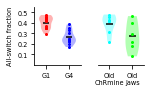

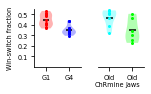

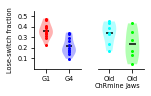

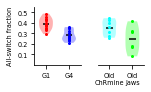

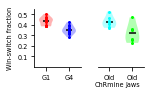

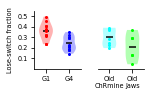

In [101]:
########################################################################
##### Figure S6b-c Bottom (DG) #####
#######################################################################
prefix = ['All', 'Win', 'Lose']
set_rcParams()
for nT in [200, 600]:
    for type in range(3):
        print(nT, prefix[type])

        fig = plt.figure(figsize=np.array([1.6, 0.8]))
        ax0 = plt.axes((0,0, 0.4,1))
        ax1 = plt.axes((0.55,0, 0.4,1))
        set_plot(ax0)
        set_plot(ax1)

        colors1 = ['red', 'blue', 'cyan', 'lime']
        Frac =[]
        for i, subject_list in enumerate(OldChRminevJaws): 
            axi = ax0 if i<2 else ax1
            fractions = np.array([])
            for subject in subject_list:
                sessions = find_sessions(subject)
                
                if type==0:
                    fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=nT, offset=0)
                elif type==1:
                    fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=nT, offset=0, win_switch=True)
                elif type==2:
                    fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=nT, offset=0, lose_switch=True)

                if not np.isnan(fraction):
                    fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
            Frac.append(fractions)
            vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.6)

            for pc in vp['bodies']:
                pc.set_facecolor(colors1[i])
            vp['cmeans'].set_color('black')
            axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
            axi.set_ylim(0.0, 0.55)
            axi.set_yticks(np.arange(0.1,0.6,0.1))
            if i<2:
                axi.set_xticks([0,1])
                axi.set_xticklabels([f'G1', f'G4'], fontsize=6.5)
                axi.set_xlim(-0.5, 1.5)
            else:
                axi.set_xticks([2,3])
                axi.set_xticklabels([f'Old\nChRmine', f'Old\nJaws'], fontsize=6.5)
                axi.set_xlim(1.5, 3.5)        
                axi.yaxis.set_visible(False)
                axi.spines['left'].set_visible(False)

            axi.set_ylabel(f'{prefix[type]}-switch fraction', fontsize=6.5)

        groups = {
            "Group 1": Frac[0],
            "Group 2": Frac[1],
            "Group 3": Frac[2],
            "Group 4": Frac[3],
        }
        results = postHoc_mutipleComparisons(groups, method='fdr_bh')
        results.to_csv(f'posthoc_statistics_figs9_{prefix[type]}{nT}.csv', index=False)

        plt.savefig(f'FigS6bc_Opto_explore_OldJaws_{prefix[type]}{nT}.svg')
        

In [102]:
########################################################################
##### Source data: Figure S6b-c #####
########################################################################

source_rows = []

prefix = ['All', 'Win', 'Lose']
group_labels = ['G1', 'G4', 'Old ChRmine', 'Old Jaws']

for nT in [200, 600]:

    for switch_type in range(3):

        for gi, subject_list in enumerate(OldChRminevJaws):

            for subject in subject_list:

                sessions = find_sessions(subject)

                if switch_type == 0:
                    fraction, nTrs = FractionSwitch(
                        sessions[:3],
                        opto=2,
                        numTR=nT,
                        offset=0
                    )

                elif switch_type == 1:
                    fraction, nTrs = FractionSwitch(
                        sessions[:3],
                        opto=2,
                        numTR=nT,
                        offset=0,
                        win_switch=True
                    )

                else:
                    fraction, nTrs = FractionSwitch(
                        sessions[:3],
                        opto=2,
                        numTR=nT,
                        offset=0,
                        lose_switch=True
                    )

                if np.isfinite(fraction):

                    source_rows.append({
                        'Mouse_ID': subject,
                        'Group': group_labels[gi],
                        'Switch_type': prefix[switch_type],
                        'Trial_window': nT,
                        'Num_trials_used': nTrs,
                        'Switch_fraction': fraction
                    })


FigS6bc_source = pd.DataFrame(source_rows)

FigS6bc_source.to_csv(
    'FigS6bc_source_data.csv',
    index=False
)

## Figure S6d
Learning curves ofG1, G4, OldChRmine, OldJaws

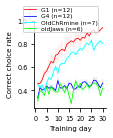

In [103]:
########################################################################
##### Figure S6d #####
#######################################################################
AllLearning=PlotMean(OldChRminevJaws, colors=['red','blue','cyan','lime'], legends=['G1 ','G4 ','OldChRmine ','oldJaws '], ylims = [0.25, 1], figscale=0.16)
plt.savefig('FigS6d_Cohort1LearningCurves.svg')

########################################################################
##### Source data: Figure S6d #####
########################################################################

group_labels = ['G1', 'G4', 'Old ChRmine', 'Old Jaws']

source_rows = []

for gi, (subjects, learning_curves) in enumerate(
        zip(OldChRminevJaws, AllLearning)):

    for si, subject in enumerate(subjects):

        for day in range(learning_curves.shape[1]):

            value = learning_curves[si, day]

            if np.isfinite(value):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_labels[gi],
                    'Training_day': day + 1,
                    'Correct_choice_rate': value
                })


FigS6d_source = pd.DataFrame(source_rows)

FigS6d_source.to_csv(
    'FigS6d_source_data.csv',
    index=False
)

## Figure S6e
Late learning in G1, G4, OldChRmine, OldJaws

Shapiro-Wilk normality tests:
Group 1: W = 0.859, n = 12, p = 0.048 (non-normal)
Group 2: W = 0.864, n = 12, p = 0.054 (normal)
Group 3: W = 0.926, n = 7, p = 0.515 (normal)
Group 4: W = 0.855, n = 6, p = 0.174 (normal)

At least one group failed normality.
Using Kruskal-Wallis + pairwise Mann-Whitney U tests.

Kruskal-Wallis H-test: H = 28.434, p = 2.945e-06

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Mann-Whitney U, stat = 144.000, n1 = 12, n2 = 12, p = 3.644e-05, p_adj = 0.0002187
Group 1 vs Group 3: Mann-Whitney U, stat = 71.000, n1 = 12, n2 = 7, p = 0.01596, p_adj = 0.01916
Group 1 vs Group 4: Mann-Whitney U, stat = 72.000, n1 = 12, n2 = 6, p = 0.0008791, p_adj = 0.001758
Group 2 vs Group 3: Mann-Whitney U, stat = 1.000, n1 = 12, n2 = 7, p = 0.0006196, p_adj = 0.001758
Group 2 vs Group 4: Mann-Whitney U, stat = 48.000, n1 = 12, n2 = 6, p = 0.2814, p_adj = 0.2814
Group 3 vs Group 4: Mann-Whitney U, stat = 41.000, n1 = 7, n2 = 6, p = 0.005341, p_adj = 0.008011


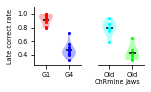

In [104]:
########################################################################
##### Figure S6e #####
########################################################################
set_rcParams()
fig = plt.figure(figsize=np.array([1.6, 0.8]))
ax0 = plt.axes((0,0, 0.4,1))
ax1 = plt.axes((0.55,0, 0.4,1))
set_plot(ax0)
set_plot(ax1)

colors1 = ['red', 'blue', 'cyan', 'lime']
Frac =[]
for i, subject_list in enumerate(OldChRminevJaws): 
    axi = ax0 if i<2 else ax1
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        y = FullContrastPerf(sessions) 
        if len(y)>25:
            learning = np.nanmean(y[25:30])
        else:
            learning = np.nanmean(y[-5:])
        fraction = learning
        if not np.isnan(fraction):
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.6)

    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0.25, 1.1)
    axi.set_yticks(np.arange(0.4,1.1,0.2))
    if i<2:
        axi.set_xticks([0,1])
        axi.set_xticklabels([f'G1', f'G4'], fontsize=6.5)
        axi.set_xlim(-0.5, 1.5)
    else:
        axi.set_xticks([2,3])
        axi.set_xticklabels([f'Old\nChRmine', f'Old\nJaws'], fontsize=6.5)
        axi.set_xlim(1.5, 3.5)        
        axi.yaxis.set_visible(False)
        axi.spines['left'].set_visible(False)

    axi.set_ylabel('Late correct rate', fontsize=6.5)

groups = {
    "Group 1": Frac[0],
    "Group 2": Frac[1],
    "Group 3": Frac[2],
    "Group 4": Frac[3],
}
results = postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figs9e_learning.csv', index=False)

plt.savefig('FigS6e_Opto_learning_OldJawsViolin.svg')

In [105]:
########################################################################
##### Source data: Figure S6e #####
########################################################################

source_rows = []

group_labels = ['G1', 'G4', 'Old ChRmine', 'Old Jaws']

for gi, subject_list in enumerate(OldChRminevJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)
        y = FullContrastPerf(sessions)

        if len(y) > 25:
            learning = np.nanmean(y[25:30])
            window_used = 'Sessions 26-30'
        else:
            learning = np.nanmean(y[-5:])
            window_used = 'Last 5 sessions'

        if np.isfinite(learning):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Late_correct_choice_rate': learning,
                'Sessions_used': window_used
            })


FigS6e_source = pd.DataFrame(source_rows)

FigS6e_source.to_csv(
    'FigS6e_source_data.csv',
    index=False
)

########################################################################
##### Source data: Figure S8a-b #####
########################################################################

source_rows = []

group_labels = ['G1', 'G4', 'Old ChRmine', 'Old Jaws']
nT = 200

for gi, subject_list in enumerate(OldChRminevJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)

        RT, NT = Compute_otherParams(
            sessions[:3],
            numTR=nT,
            opto=2
        )

        source_rows.append({
            'Mouse_ID': subject,
            'Group': group_labels[gi],
            'Trial_window': nT,
            'Reaction_time_sec': RT,
            'Mean_number_of_trials_first_3_sessions': NT
        })


FigS8ab_source = pd.DataFrame(source_rows)

FigS8ab_source.to_csv(
    'FigS8ab_source_data.csv',
    index=False
)

## Figure S8a-b
Reaction time and Number of trials in G1, G4, OldChRmine, OldJaws

Shapiro-Wilk normality tests:
Group 1: W = 0.880, n = 12, p = 0.089 (normal)
Group 2: W = 0.800, n = 12, p = 0.009 (non-normal)
Group 3: W = 0.662, n = 7, p = 0.001 (non-normal)
Group 4: W = 0.836, n = 6, p = 0.121 (normal)

At least one group failed normality.
Using Kruskal-Wallis + pairwise Mann-Whitney U tests.

Kruskal-Wallis H-test: H = 14.459, p = 0.002342

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Mann-Whitney U, stat = 19.000, n1 = 12, n2 = 12, p = 0.002437, p_adj = 0.01462
Group 1 vs Group 3: Mann-Whitney U, stat = 37.000, n1 = 12, n2 = 7, p = 0.7037, p_adj = 0.7037
Group 1 vs Group 4: Mann-Whitney U, stat = 10.000, n1 = 12, n2 = 6, p = 0.01693, p_adj = 0.03017
Group 2 vs Group 3: Mann-Whitney U, stat = 70.000, n1 = 12, n2 = 7, p = 0.02012, p_adj = 0.03017
Group 2 vs Group 4: Mann-Whitney U, stat = 28.000, n1 = 12, n2 = 6, p = 0.4824, p_adj = 0.5789
Group 3 vs Group 4: Mann-Whitney U, stat = 4.000, n1 = 7, n2 = 6, p = 0.01842, p_adj = 0.03017
Shapiro-Wilk n

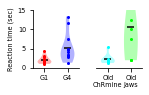

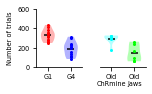

In [106]:
########################################################################
##### Figure S8a-b #####
#######################################################################

prefix = ['Reaction time (sec)', 'Number of trials']
set_rcParams()
for nT in [200]:
    for type in range(2):
        fig = plt.figure(figsize=np.array([1.6, 0.8]))
        ax0 = plt.axes((0,0, 0.4,1))
        ax1 = plt.axes((0.55,0, 0.4,1))
        set_plot(ax0)
        set_plot(ax1)

        colors1 = ['red', 'blue', 'cyan', 'lime']
        Frac =[]
        for i, subject_list in enumerate(OldChRminevJaws): 
            axi = ax0 if i<2 else ax1
            fractions = np.array([])
            for subject in subject_list:
                sessions = find_sessions(subject)
                
                RT, NT =Compute_otherParams(sessions[:3], numTR=nT, opto=2)       
    
                if type==0:
                    fraction = RT
                elif type==1:
                    fraction = NT

                if not np.isnan(fraction):
                    fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
            Frac.append(fractions)
            vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.6)

            for pc in vp['bodies']:
                pc.set_facecolor(colors1[i])
            vp['cmeans'].set_color('black')
            axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
            if type==0:
                axi.set_ylim(0, 15)
            else:
                axi.set_ylim(0,600)
            #axi.set_yticks(np.arange(0.1,0.6,0.1))
            if i<2:
                axi.set_xticks([0,1])
                axi.set_xticklabels([f'G1', f'G4'], fontsize=6.5)
                axi.set_xlim(-0.5, 1.5)
            else:
                axi.set_xticks([2,3])
                axi.set_xticklabels([f'Old\nChRmine', f'Old\nJaws'], fontsize=6.5)
                axi.set_xlim(1.5, 3.5)        
                axi.yaxis.set_visible(False)
                axi.spines['left'].set_visible(False)

            axi.set_ylabel(f'{prefix[type]}', fontsize=6.5)

        groups = {
            "Group 1": Frac[0],
            "Group 2": Frac[1],
            "Group 3": Frac[2],
            "Group 4": Frac[3],
        }
        results=postHoc_mutipleComparisons(groups, method='fdr_bh')
        results.to_csv(f'posthoc_statistics_figS8ab_{prefix[type]}{nT}.csv', index=False)

        plt.savefig(f'FigS8ab_Opto_explore_OldJaws_{prefix[type]}{nT}.svg')

In [107]:
########################################################################
##### Source data: Figure S8a-b #####
########################################################################

source_rows = []

group_labels = ['G1', 'G4', 'Old ChRmine', 'Old Jaws']
nT = 200

for gi, subject_list in enumerate(OldChRminevJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)

        RT, NT = Compute_otherParams(
            sessions[:3],
            numTR=nT,
            opto=2
        )

        source_rows.append({
            'Mouse_ID': subject,
            'Group': group_labels[gi],
            'Trial_window': nT,
            'Reaction_time_sec': RT,
            'Mean_number_of_trials_first_3_sessions': NT
        })


FigS8ab_source = pd.DataFrame(source_rows)

FigS8ab_source.to_csv(
    'FigS8ab_source_data.csv',
    index=False
)

# Figure 5
This block includes the second cohort of Old ChRmine optogenetic experiment.

## Load subject database for optogenetic experiment
Run this before Figure 5, S8, S9

In [108]:
##### Load subject database and compile mice from control and optogenetic experiments

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 4,   ['experiment'], ['YoungGFP2']),
    combine_criteria(15, 25, ['experiment'], ['OldGFP1']),
    combine_criteria(15, 25, ['experiment'], ['OldChRmine2']),
] 
OldGFPvChRmine, Opto_group_names, Opto_ages, Opto_sexes, _ = group_subjects(group_criteria, SubjectDB)

for age in Opto_ages:
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 3.0]
Age: [20.0, 20.0]
Age: [19.0, 20.0]


In [109]:
##### Opto trial ITI distribution
all_time = np.array(Get_timeInfo(OldGFPvChRmine, MaxDay=16), dtype=object)
bigmat=[]
ti=1 #0 for session duration, 1 for iti length
for at in all_time:
    bigmat = at[:,:,ti] if len(bigmat)==0 else np.concatenate((bigmat, at[:,:,ti]), axis=0)
print('Mean ITI, SD ITI, min ITI, max ITI')
print(np.nanmean(bigmat),np.nanstd(bigmat), np.nanmin(bigmat), np.nanmax(bigmat))

Mean ITI, SD ITI, min ITI, max ITI
4.568895072158541 0.9383345343707409 3.4402509661835814 12.50728079470199


## Figure 5c-d
Temporal dynamics of switch fraction

[0.04850332 0.04850332 0.07672547 0.04850332 0.04850332 0.04850332]
[0.83030267 0.83030267 0.83030267 0.83030267 0.83030267 0.83030267]


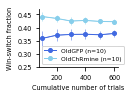

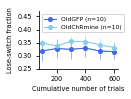

In [110]:
########################################################################
##### Figure 5c-d #####
#######################################################################

set_rcParams()

subjects_groups = OldGFPvChRmine[1:]
labels = [ 'OldGFP', 'OldChRmine']
colors1 = ['royalblue', 'skyblue']
numSessions = 6
for ti, stype in enumerate(['Win', 'Lose']):
    plt.figure(figsize=np.array([1.1,0.8])*1)
    axe = plt.axes([0,0,1,1])
    set_plot(axe)
    Frac=[]
    for i, subject_list in enumerate(subjects_groups): 
        fractions = np.array([])
        for subject in subject_list:
            sessions = find_sessions(subject)
            
            fraction = np.empty((numSessions,))
            for si in range(numSessions):
                if ti==0:
                    fraction[si], nTrs = FractionSwitch(sessions[:3], opto=2, numTR=100+100*si, offset=0, win_switch=True)
                else:
                    fraction[si], nTrs = FractionSwitch(sessions[:3], opto=2, numTR=100+100*si, offset=0, lose_switch=True)
            fractions = np.vstack((fractions, (fraction))) if fractions.size else (fraction)
        Frac.append(fractions)

    for fi, fraction in enumerate(Frac):
        mean = np.nanmean(fraction, axis=0)
        se = np.nanstd(fraction, axis=0)/np.sqrt(fraction.shape[0])

        plt.plot(np.arange(fraction.shape[1])*100+100, mean, color=colors1[fi], marker='o', markersize=4, linewidth=1)
        plt.errorbar(np.arange(fraction.shape[1])*100+100, mean, [se, se], color=colors1[fi], linewidth=0.5)
        plt.xlabel('Cumulative number of trials')
        plt.ylabel(f'{stype}-switch fraction')

    if ti==0:
        plt.legend([f'{labels[0]} (n={len(Frac[0])})', f'{labels[1]} (n={len(Frac[1])})'], loc='lower left', fontsize=6)
    else:
        plt.legend([f'{labels[0]} (n={len(Frac[0])})', f'{labels[1]} (n={len(Frac[1])})'], loc='upper left', fontsize=6)
    plt.yticks(np.arange(0.25, 0.47, 0.05))
    plt.ylim(0.25, 0.47)

    pvals=[]
    results=[]
    for NS in range(Frac[0].shape[1]):
        OG=Frac[0][:, NS]
        OC=Frac[1][:, NS]

        test = twoSampleTest(OC, OG)
        p = test['p']
        pvals.append(p)
        results.append(test)

    corrected = multipletests(pvals, method='fdr_bh')
    corrected_ps = corrected[1]
    print(corrected_ps)

    results2 = []
    for ri, res in enumerate(results):
        res['p_adj'] = corrected_ps[ri]
        results2.append(res)
    df = pd.DataFrame(results2)
    
    if ti==0:
        plt.savefig('Fit5c_Switch_evolutionWS.svg')
        df.to_csv('statistical_results_figs5c.csv', index=False)
    else:
        plt.savefig('Fit5d_Switch_evolutionLS.svg')
        df.to_csv('statistical_results_figs5d.csv', index=False)
    

In [111]:
########################################################################
##### Source data: Figure 5c-d #####
########################################################################

source_rows = []

subjects_groups = OldGFPvChRmine[1:]
group_labels = ['Old GFP', 'Old ChRmine']

numSessions = 6
trial_windows = np.arange(1, numSessions + 1) * 100

for switch_type in ['Win', 'Lose']:

    for gi, subject_list in enumerate(subjects_groups):

        for subject in subject_list:

            sessions = find_sessions(subject)

            for nT in trial_windows:

                if switch_type == 'Win':
                    fraction, nTrs = FractionSwitch(
                        sessions[:3],
                        opto=2,
                        numTR=nT,
                        offset=0,
                        win_switch=True
                    )

                else:
                    fraction, nTrs = FractionSwitch(
                        sessions[:3],
                        opto=2,
                        numTR=nT,
                        offset=0,
                        lose_switch=True
                    )

                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_labels[gi],
                    'Switch_type': switch_type,
                    'Cumulative_trial_window': nT,
                    'Num_trials_used': nTrs,
                    'Switch_fraction': fraction
                })


Fig5cd_source = pd.DataFrame(source_rows)

Fig5cd_source.to_csv(
    'Fig5cd_source_data.csv',
    index=False
)

## Figure 5e
Young GFP, Old GFP, and Old ChRmine group switch fraction comparisons

Shapiro-Wilk normality tests:
Group 1: W = 0.962, n = 8, p = 0.826 (normal)
Group 2: W = 0.943, n = 10, p = 0.583 (normal)
Group 3: W = 0.987, n = 10, p = 0.992 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 5.055, p = 0.01434

Pairwise comparisons (fdr_bh correction):
Group 1 vs Group 2: Welch's t-test, stat = 2.685, n1 = 8, n2 = 10, p = 0.01805, p_adj = 0.04245
Group 1 vs Group 3: Welch's t-test, stat = 1.010, n1 = 8, n2 = 10, p = 0.3347, p_adj = 0.3347
Group 2 vs Group 3: Welch's t-test, stat = -2.408, n1 = 10, n2 = 10, p = 0.0283, p_adj = 0.04245


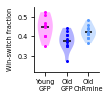

In [112]:
########################################################################
##### Figure 5e #####
########################################################################
set_rcParams()
fig = plt.figure(figsize=np.array([0.9, 0.9])*1)
axi = plt.axes((0,0, 1,1))
set_plot(axi)

colors1 = ['magenta', 'blue', '#5599FF']
Frac =[]
for i, subject_list in enumerate(OldGFPvChRmine): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=600, offset=0, win_switch=True)
        if not np.isnan(fraction):
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0.22, 0.55)
    axi.set_yticks(np.arange(0.3,0.6,0.1))
    if i==2:
        axi.set_xticks([0,1,2])
        axi.set_xticklabels([f'Young\nGFP', f'Old\nGFP', f'Old\nChRmine'], fontsize=6.5)
        axi.set_xlim(-0.5, 2.5)

    axi.set_ylabel('Win-switch fraction', fontsize=6.5)

plt.savefig('Fig5e_Opto_explore_violin.svg')
groups = {
    "Group 1": Frac[0],
    "Group 2": Frac[1],
    "Group 3": Frac[2],
}
results = postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figs5e.csv', index=False)


In [113]:
#######################################################################
##### Source data: Figure 5e #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine):

    for subject in subject_list:

        sessions = find_sessions(subject)

        fraction, nTrs = FractionSwitch(
            sessions[:3],
            opto=2,
            numTR=600,
            offset=0,
            win_switch=True
        )

        if np.isfinite(fraction):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Trial_window': 600,
                'Num_trials_used': nTrs,
                'Win_switch_fraction': fraction
            })


Fig5e_source = pd.DataFrame(source_rows)

Fig5e_source.to_csv(
    'Fig5e_source_data.csv',
    index=False
)

## Figure 5f
Young GFP, Old GFP, and Old ChRmine group learning curves

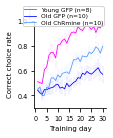

In [114]:
########################################################################
##### Figure 5f #####
########################################################################
colors1 = ['magenta', 'blue', '#5599FF']
AllLearning = PlotMean(subject_lists=OldGFPvChRmine, colors = colors1, ylims=[0.3,1], 
             legends=['Young GFP ', 'Old GFP ', 'Old ChRmine '], figscale=0.16)
plt.savefig("Fig5f_OptoLearningCurve2.svg")

In [115]:
########################################################################
##### Source data: Figure 5f #####
########################################################################

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

source_rows = []

for gi, (subjects, learning_curves) in enumerate(
        zip(OldGFPvChRmine, AllLearning)):

    for si, subject in enumerate(subjects):

        for day in range(learning_curves.shape[1]):

            value = learning_curves[si, day]

            if np.isfinite(value):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_labels[gi],
                    'Training_day': day + 1,
                    'Correct_choice_rate': value
                })


Fig5f_source = pd.DataFrame(source_rows)

Fig5f_source.to_csv(
    'Fig5f_source_data.csv',
    index=False
)

## Figure 5g
Young GFP, Old GFP, and Old ChRmine group late learning

Shapiro-Wilk normality tests:
Young GFP: W = 0.868, n = 8, p = 0.146 (normal)
Old GFP: W = 0.900, n = 10, p = 0.217 (normal)
Old ChRmine: W = 0.932, n = 10, p = 0.466 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 12.683, p = 0.0001576

Pairwise comparisons (fdr_bh correction):
Young GFP vs Old GFP: Welch's t-test, stat = 5.417, n1 = 8, n2 = 10, p = 0.0002605, p_adj = 0.0007815
Young GFP vs Old ChRmine: Welch's t-test, stat = 3.560, n1 = 8, n2 = 10, p = 0.00412, p_adj = 0.00618
Old GFP vs Old ChRmine: Welch's t-test, stat = -2.376, n1 = 10, n2 = 10, p = 0.03013, p_adj = 0.03013


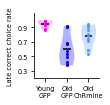

In [116]:
########################################################################
##### Figure 5g #####
########################################################################

set_rcParams()
fig = plt.figure(figsize=np.array([0.9, 0.9])*1)
axi = plt.axes((0,0, 1,1))
set_plot(axi)


colors1 = ['magenta', 'blue', '#5599FF']
Frac =[]
for i, subject_list in enumerate(OldGFPvChRmine): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        y = FullContrastPerf(sessions) 
        if len(y)>25:
            learning = np.nanmean(y[25:30])
        fraction = learning
        
        if not np.isnan(fraction):
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0.2, 1.1)
    axi.set_yticks(np.arange(0.3,0.9,0.2))
    if i==2:
        axi.set_xticks([0,1,2])
        axi.set_xticklabels([f'Young\nGFP', f'Old\nGFP', f'Old\nChRmine'], fontsize=6.5)
        axi.set_xlim(-0.5, 2.5)

    axi.set_ylabel('Late correct choice rate', fontsize=6.5)


plt.savefig('Fig5g_Opto_learning_violin2.svg')


groups = {
    "Young GFP": Frac[0],
    "Old GFP": Frac[1],
    "Old ChRmine": Frac[2],
}
results=postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figS5g.csv', index=False)

In [117]:
########################################################################
##### Source data: Figure 5g #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine):

    for subject in subject_list:

        sessions = find_sessions(subject)
        y = FullContrastPerf(sessions)

        if len(y) > 25:
            learning = np.nanmean(y[25:30])
        else:
            learning = np.nan

        if np.isfinite(learning):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Late_correct_choice_rate_sessions_26_30': learning
            })


Fig5g_source = pd.DataFrame(source_rows)

Fig5g_source.to_csv(
    'Fig5g_source_data.csv',
    index=False
)

## Figure 5h
Within Old GFP, and Old ChRmine groups, switch versus learning relationship

0.3939393939393939 0.25999776683488757
0.38181818181818183 0.27625533338543595
0.4812030075187969 0.031711044624462434 20


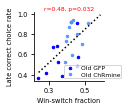

In [118]:
########################################################################
##### Figure 5h #####
########################################################################

set_rcParams()
plt.figure(figsize=np.array([1.2,1.2])*0.8)
axe = plt.axes([0,0,1,1])
set_plot(axe)

colors1 = ['blue', '#5599FF']
Frac = []
PerfMat = []

for i, subject_list in enumerate(OldGFPvChRmine[1:]): 

    fractions = np.array([])
    Perf = []
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=200, offset=0, win_switch=True)
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
        
        y = FullContrastPerf(sessions)
        if len(y)>25:
            learning = np.nanmean(y[25:30])
        else:
            learning = np.nanmean(y[-5:])
        Perf.append(learning)
    Perf = np.array(Perf)
    if len(Perf)>0:
        ind = np.flatnonzero(~(np.isnan(Perf)))
        xf =fractions
        r,p = stats.spearmanr(xf[ind], Perf[ind])
        print(r, p)
        if len(Frac)==0:
            Frac = fractions
            PerfMat = np.array(Perf)
        else:
            Frac = np.concatenate((Frac,fractions))
            PerfMat = np.concatenate((PerfMat,np.array(Perf)))
        x = fractions
        y = Perf
        plt.plot(x, y, '.', color=colors1[i], alpha=1, markersize=5)

plt.legend(['Old GFP', 'Old ChRmine'], fontsize=6, loc='lower right', bbox_to_anchor=(1.3, 0), borderpad=0.1, labelspacing=0.2)
ind = np.flatnonzero(~(np.isnan(PerfMat)))
x = Frac[ind]
y = PerfMat[ind]
r,p = stats.spearmanr(x, y)

test = spearmanTest(x, y, label='Fig. 5h', random_state=1)
r = test['rho']
p = test['p']
results = pd.DataFrame([test])
results.to_csv(f'posthoc_statistics_fig5h.csv', index=False)

print(r,p, len(x))
res = stats.linregress(x, y)
x2 = np.arange(0.24, 0.6, 0.05)
plt.xticks([0.3, 0.5])
plt.plot(x2, res.intercept + res.slope*x2, 'k:')
plt.yticks(np.arange(0.4, 1.1, 0.2))
plt.xlabel('Win-switch fraction')
plt.ylabel('Late correct choice rate')
plt.title(f'r={r:1.2f}, p={p:1.3f}', fontsize=6, color='r', pad=0.2)
plt.savefig('Fig5h_ExploreLearningCorr_Opto2.svg')

In [119]:
########################################################################
##### Source data: Figure 5h #####
########################################################################

source_rows = []

group_labels = ['Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine[1:]):

    for subject in subject_list:

        sessions = find_sessions(subject)

        fraction, nTrs = FractionSwitch(
            sessions[:3],
            opto=2,
            numTR=200,
            offset=0,
            win_switch=True
        )

        y = FullContrastPerf(sessions)

        if len(y) > 25:
            learning = np.nanmean(y[25:30])
            window_used = 'Sessions 26-30'
        else:
            learning = np.nanmean(y[-5:])
            window_used = 'Last 5 sessions'

        source_rows.append({
            'Mouse_ID': subject,
            'Group': group_labels[gi],
            'Win_switch_fraction_first_200_trials': fraction,
            'Num_trials_used': nTrs,
            'Late_correct_choice_rate': learning,
            'Sessions_used_for_late_performance': window_used
        })


Fig5h_source = pd.DataFrame(source_rows)

Fig5h_source.to_csv(
    'Fig5h_source_data.csv',
    index=False
)

## Figure S8c
Young GFP, Old GFP, and Old ChRmine Reaction time comparison

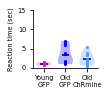

In [120]:
########################################################################
##### Figure S8c #####
########################################################################

set_rcParams()
fig = plt.figure(figsize=np.array([0.9, 0.8])*1)
axi = plt.axes((0,0, 1,1))
set_plot(axi)

colors1 = ['magenta', 'blue', '#5599FF']
Frac =[]
for i, subject_list in enumerate(OldGFPvChRmine): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        RT, NT = Compute_otherParams(sessions[:3], numTR=200, opto=2)       
        fraction = RT
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0, 15)
#    axi.set_yticks(np.arange(0.3,0.9,0.2))
    if i==2:
        axi.set_xticks([0,1,2])
        axi.set_xticklabels([f'Young\nGFP', f'Old\nGFP', f'Old\nChRmine'], fontsize=6.5)
        axi.set_xlim(-0.5, 2.5)
 
    axi.set_ylabel('Reaction time (sec)', fontsize=6.5)
plt.savefig('FigS8c_Opto_RT.svg')

In [121]:
########################################################################
##### Source data: Figure S8d #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine):

    for subject in subject_list:

        sessions = find_sessions(subject)

        RT, NT = Compute_otherParams(
            sessions[:3],
            numTR=5000,
            opto=2
        )

        if np.isfinite(NT):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Mean_number_of_trials_first_3_sessions': NT
            })


FigS8d_source = pd.DataFrame(source_rows)

FigS8d_source.to_csv(
    'FigS8d_source_data.csv',
    index=False
)
results = postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figS8c.csv', index=False)

########################################################################
##### Source data: Figure S8c #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine):

    for subject in subject_list:

        sessions = find_sessions(subject)

        RT, NT = Compute_otherParams(
            sessions[:3],
            numTR=200,
            opto=2
        )

        if np.isfinite(RT):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Trial_window': 200,
                'Reaction_time_sec': RT
            })


FigS8c_source = pd.DataFrame(source_rows)

FigS8c_source.to_csv(
    'FigS8c_source_data.csv',
    index=False
)

Shapiro-Wilk normality tests:
Young GFP: W = 0.868, n = 8, p = 0.146 (normal)
Old GFP: W = 0.900, n = 10, p = 0.217 (normal)
Old ChRmine: W = 0.932, n = 10, p = 0.466 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 12.683, p = 0.0001576

Pairwise comparisons (fdr_bh correction):
Young GFP vs Old GFP: Welch's t-test, stat = 5.417, n1 = 8, n2 = 10, p = 0.0002605, p_adj = 0.0007815
Young GFP vs Old ChRmine: Welch's t-test, stat = 3.560, n1 = 8, n2 = 10, p = 0.00412, p_adj = 0.00618
Old GFP vs Old ChRmine: Welch's t-test, stat = -2.376, n1 = 10, n2 = 10, p = 0.03013, p_adj = 0.03013


## Figure S8d
Young GFP, Old GFP, and Old ChRmine Number of trials comparison

380.25
251.0
334.3
Shapiro-Wilk normality tests:
Young GFP: W = 0.887, n = 8, p = 0.221 (normal)
Old GFP: W = 0.894, n = 10, p = 0.188 (normal)
Old ChRmine: W = 0.922, n = 10, p = 0.371 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 3.411, p = 0.04899

Pairwise comparisons (fdr_bh correction):
Young GFP vs Old GFP: Welch's t-test, stat = 3.538, n1 = 8, n2 = 10, p = 0.002797, p_adj = 0.008391
Young GFP vs Old ChRmine: Welch's t-test, stat = 0.910, n1 = 8, n2 = 10, p = 0.3794, p_adj = 0.3794
Old GFP vs Old ChRmine: Welch's t-test, stat = -1.550, n1 = 10, n2 = 10, p = 0.1416, p_adj = 0.2124


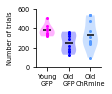

In [122]:
########################################################################
##### Figure S8d #####
########################################################################

set_rcParams()
fig = plt.figure(figsize=np.array([0.9, 0.8])*1)
axi = plt.axes((0,0, 1,1))
set_plot(axi)

colors1 = ['magenta', 'blue', '#5599FF']
Frac =[]
for i, subject_list in enumerate(OldGFPvChRmine):  
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        RT, NT =Compute_otherParams(sessions[:3], numTR=5000, opto=2)       
        fraction = NT
        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    #print(fractions)
    Frac.append(fractions)
    print(np.nanmean(fractions, axis=0))
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0, 600)
#    axi.set_yticks(np.arange(0.3,0.9,0.2))
    if i==2:
        axi.set_xticks([0,1,2])
        axi.set_xticklabels([f'Young\nGFP', f'Old\nGFP', f'Old\nChRmine'], fontsize=6.5)
        axi.set_xlim(-0.5, 2.5)
   
    axi.set_ylabel('Number of trials', fontsize=6.5)
plt.savefig('FigS8d_Opto_NT.svg')

groups = {
    "Young GFP": Frac[0],
    "Old GFP": Frac[1],
    "Old ChRmine": Frac[2],
}

results = postHoc_mutipleComparisons(groups, method='fdr_bh')
results.to_csv(f'posthoc_statistics_figS8d.csv', index=False)

In [123]:
########################################################################
##### Source data: Figure S8d #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Old GFP', 'Old ChRmine']

for gi, subject_list in enumerate(OldGFPvChRmine):

    for subject in subject_list:

        sessions = find_sessions(subject)

        RT, NT = Compute_otherParams(
            sessions[:3],
            numTR=5000,
            opto=2
        )

        if np.isfinite(NT):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Mean_number_of_trials_first_3_sessions': NT
            })


FigS8d_source = pd.DataFrame(source_rows)

FigS8d_source.to_csv(
    'FigS8d_source_data.csv',
    index=False
)

## Figure S9
ChRmine Light-off vs Light-on comparison

p_adj=[0.78578688 0.78578688 0.78578688 0.78578688 0.78578688]
p_adj=[0.91163156 0.91163156 0.91163156 0.91163156 0.91163156]
p_adj=[0.92773438 0.9686243  0.92773438 0.92773438 0.9686243 ]
p_adj=[0.56000721 0.56000721 0.56036082 0.56000721 0.56000721]


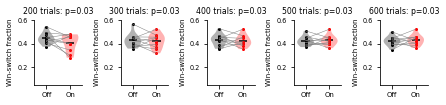

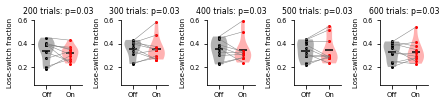

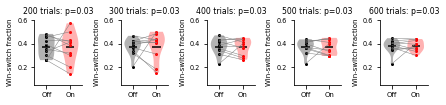

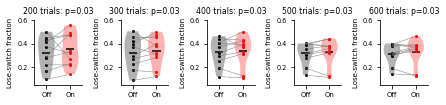

In [124]:
########################################################################
##### Figure S9 #####
########################################################################
results=[]
corrected_ps=[]
OldGFP = OldGFPvChRmine[1]
OldChRmine2 = OldGFPvChRmine[2]
for gi, group in enumerate(['ChRmine', 'GFP']):
    for ti, etype in enumerate(['Win-switch', 'Lose-switch']):
        if gi==0:
            subjects_list = [OldChRmine2, OldChRmine2]
        else:
            subjects_list = [OldGFP, OldGFP]
        
        set_rcParams()
        fig = plt.figure(figsize=np.array([6, 0.9])*1)

        colors1 = ['black', 'red']
        pvals=[]
        for ni, numT in enumerate(np.arange(200, 700, 100)):
            Frac =[]
            # Reuse one Axes for both conditions. Matplotlib 3.8 otherwise
            # places the second Axes over the first and hides the control artists.
            axi = plt.axes((0.2*ni, 0, 0.11, 1))
            set_plot(axi)

            for i, subject_list in enumerate(subjects_list): 
                fractions = np.array([])
                for subject in subject_list:
                    sessions = find_sessions(subject)

                    if ti==0:
                        fraction, nTrs = FractionSwitch(sessions[:3], opto=i, numTR=numT, offset=0, win_switch=True)
                    else:
                        fraction, nTrs = FractionSwitch(sessions[:3], opto=i, numTR=numT, offset=0, lose_switch=True)

                    if not np.isnan(fraction):
                        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
                Frac.append(fractions)
                vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)

                for pc in vp['bodies']:
                    pc.set_facecolor(colors1[i])
                vp['cmeans'].set_color('black')
                axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
                axi.set_ylim(0.05, 0.6)
            #    axi.set_yticks(np.arange(0.3,0.6,0.1))
                axi.set_xticks([0, 1])
                axi.set_xticklabels(['Off', 'On'], fontsize=7)
                axi.set_xlim(-0.5, 1.5)

                axi.set_ylabel(f'{etype} fraction', fontsize=7)

            plt.plot(np.array(Frac), color='gray', linewidth=0.5)
            x = Frac[0]
            y = Frac[1]
            test = pairedTest(x, y)

            test['Group'] = group
            test['Switch_type'] = etype
            test['Cumulative_trial_window'] = numT

            results.append(test)
            pvals.append(test['p'])
            plt.title(f"{numT} trials: p={p:0.2f}")
        plt.savefig(f'FigS9_Opto_explore_violin_diff_{group}_{etype}.svg')
        corrected = multipletests(pvals, method='fdr_bh')
        print(f'p_adj={corrected[1]}')
        if len(corrected_ps)==0:
            corrected_ps = corrected[1]
        else:
            corrected_ps = np.hstack((corrected_ps, corrected[1]))
results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('statistical_results_figS9.csv', index=False)

In [125]:
########################################################################
##### Source data: Figure S9 #####
########################################################################

source_rows = []

OldGFP = OldGFPvChRmine[1]
OldChRmine2 = OldGFPvChRmine[2]

for group_label, subject_list in zip(
        ['ChRmine', 'GFP'],
        [OldChRmine2, OldGFP]):

    for switch_type in ['Win-switch', 'Lose-switch']:

        for numT in np.arange(200, 700, 100):

            for subject in subject_list:

                sessions = find_sessions(subject)

                # Light OFF
                if switch_type == 'Win-switch':
                    off_fraction, off_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=0,
                        numTR=numT,
                        offset=0,
                        win_switch=True
                    )
                else:
                    off_fraction, off_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=0,
                        numTR=numT,
                        offset=0,
                        lose_switch=True
                    )

                # Light ON
                if switch_type == 'Win-switch':
                    on_fraction, on_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=1,
                        numTR=numT,
                        offset=0,
                        win_switch=True
                    )
                else:
                    on_fraction, on_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=1,
                        numTR=numT,
                        offset=0,
                        lose_switch=True
                    )

                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_label,
                    'Switch_type': switch_type,
                    'Cumulative_trial_window': numT,
                    'Off_num_trials_used': off_nTrs,
                    'On_num_trials_used': on_nTrs,
                    'Off_switch_fraction': off_fraction,
                    'On_switch_fraction': on_fraction
                })


FigS9_source = pd.DataFrame(source_rows)

FigS9_source.to_csv(
    'FigS9_source_data.csv',
    index=False
)

# Figure 6 and Supplementary Figure 12
This block includes Young Jaws Mouse optogenetic experiment.

## Load subject database for Young Jaws optogenetic experiment

In [126]:
##### Load subject database and compile mice from control and optogenetic experiments

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 4,   ['experiment'], ['YoungGFP1']),
    combine_criteria(2, 4, ['experiment'], ['YoungJaws1']),
]  
YoungGFPvJaws, Opto_group_names, Opto_ages, Opto_sexes, _ = group_subjects(group_criteria, SubjectDB)

for age in Opto_ages:
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [2.0, 3.0]
Age: [2.0, 3.0]


## Figure 6a
Young Jaws Switch temporal dynamics

p_adj:[0.04416725 0.04416725 0.04416725 0.04416725]


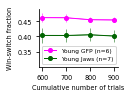

In [127]:
set_rcParams()
plt.figure(figsize=np.array([1.1,0.8])*1)
axe = plt.axes([0,0,1,1])
set_plot(axe)

labels = ['YoungGFP', 'YoungJaws', ]
colors1 = ['magenta', 'Darkgreen', ]

Frac=[]
numSessions = 4
for i, subject_list in enumerate(YoungGFPvJaws): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        fraction = np.empty((numSessions,))
        for si in range(numSessions):
            fraction[si], nTrs = FractionSwitch(sessions[:3], opto=2, numTR=600+100*si, offset=0, win_switch=True)
        fractions = np.vstack((fractions, (fraction))) if fractions.size else (fraction)
    Frac.append(fractions)

for fi, fraction in enumerate(Frac):
    median = np.nanmedian(fraction, axis=0)
    q25 = np.nanpercentile(fraction, 25, axis=0)
    q75 = np.nanpercentile(fraction, 75, axis=0)
    mean = np.nanmean(fraction, axis=0)
    se = np.nanstd(fraction, axis=0)/np.sqrt(fraction.shape[0])

    plt.plot(np.arange(fraction.shape[1])*100+600, mean, color=colors1[fi], marker='o', markersize=4, linewidth=1)
    plt.errorbar(np.arange(fraction.shape[1])*100+600, mean, [se, se], color=colors1[fi], linewidth=0.5)
    plt.xlabel('Cumulative number of trials')
    plt.ylabel('Win-switch fraction')

plt.legend([f'Young GFP (n={len(Frac[0])})', f'Young Jaws (n={len(Frac[1])})'], loc='lower left', fontsize=6)
plt.yticks(np.arange(0.35, 0.47, 0.05))
plt.ylim(0.3,0.49)

pvals=[]
results=[]
for NS in range(Frac[0].shape[1]):
    OG=Frac[0][:, NS]
    OC=Frac[1][:, NS]

    test = twoSampleTest(OC, OG, alternative='less')
    p = test['p']
    pvals.append(p)
    results.append(test)

corrected = multipletests(pvals, method='fdr_bh')
corrected_ps = corrected[1]
print(f'p_adj:{corrected[1]}')
plt.savefig('Fig6a_Switch_evolution_WS_Jaws.svg')

results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('statistical_results_fig6a.csv', index=False)

In [128]:
########################################################################
##### Source data: Figure 6a #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Young Jaws']
trial_windows = [600, 700, 800, 900]

for gi, subject_list in enumerate(YoungGFPvJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)

        for nT in trial_windows:

            fraction, nTrs = FractionSwitch(
                sessions[:3],
                opto=2,
                numTR=nT,
                offset=0,
                win_switch=True
            )

            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Cumulative_trial_window': nT,
                'Num_trials_used': nTrs,
                'Win_switch_fraction': fraction
            })


Fig6a_source = pd.DataFrame(source_rows)

Fig6a_source.to_csv(
    'Fig6a_source_data.csv',
    index=False
)

## Figure 6b
Young GFP vs Young Jaws Early Swith Fraction

Shapiro-Wilk normality tests:
Young GFP: W = 0.928, n = 6, p = 0.565 (normal)
Young Jaws: W = 0.840, n = 7, p = 0.099 (normal)

All groups passed normality.
Using ANOVA + pairwise Welch's t-tests.

One-way ANOVA: F = 3.621, p = 0.08354

Pairwise comparisons (fdr_bh correction):
Young GFP vs Young Jaws: Welch's t-test, stat = 1.987, n1 = 6, n2 = 7, p = 0.03797, p_adj = 0.03797


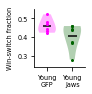

In [129]:
########################################################################
##### Figure 6b #####
########################################################################
set_rcParams()
plt.figure(figsize=np.array([0.7,0.8])*1)
axi = plt.axes([0,0,1,1])
set_plot(axi)

colors1 = ['magenta', 'darkgreen']
Frac =[]
for i, subject_list in enumerate(YoungGFPvJaws): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        fraction, nTrs = FractionSwitch(sessions[:3], opto=2, numTR=600, offset=0, win_switch=True)

        if not np.isnan(fraction):
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0.24, 0.55)
    axi.set_yticks(np.arange(0.3,0.6,0.1))
    if i==1:
        axi.set_xticks([0,1])
        axi.set_xticklabels([f'Young\nGFP', f'Young\nJaws'], fontsize=6.5)
        axi.set_xlim(-0.5, 1.5)
   
    axi.set_ylabel('Win-switch fraction', fontsize=6.5)

plt.savefig('Fig6b_Opto_explore_Jaws.svg')
groups = {
    "Young GFP": Frac[0],
    "Young Jaws": Frac[1],
}
results = postHoc_mutipleComparisons(groups, method='fdr_bh', alternative='greater')
results.to_csv(f'posthoc_statistics_figs6b.csv', index=False)

In [130]:
########################################################################
##### Source data: Figure 6b #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Young Jaws']

for gi, subject_list in enumerate(YoungGFPvJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)

        fraction, nTrs = FractionSwitch(
            sessions[:3],
            opto=2,
            numTR=600,
            offset=0,
            win_switch=True
        )

        if np.isfinite(fraction):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Trial_window': 600,
                'Num_trials_used': nTrs,
                'Win_switch_fraction': fraction
            })


Fig6b_source = pd.DataFrame(source_rows)

Fig6b_source.to_csv(
    'Fig6b_source_data.csv',
    index=False
)

## Figure 6c
Young GFP and Young Jaws Learning curves

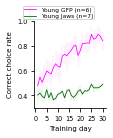

In [131]:
########################################################################
##### Figure 6c #####
########################################################################
colors1 = ['magenta', 'darkgreen']
AllLearning= PlotMean(subject_lists=YoungGFPvJaws, colors = colors1, ylims=[0.3,1], 
             legends=['Young GFP ', 'Young Jaws '], figscale=0.16)
plt.savefig("Fig6c_OptoLearningCurveJaws.svg")

In [132]:
########################################################################
##### Source data: Figure 6c #####
########################################################################

group_labels = ['Young GFP', 'Young Jaws']

source_rows = []

for gi, (subjects, learning_curves) in enumerate(
        zip(YoungGFPvJaws, AllLearning)):

    for si, subject in enumerate(subjects):

        for day in range(learning_curves.shape[1]):

            value = learning_curves[si, day]

            if np.isfinite(value):
                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_labels[gi],
                    'Training_day': day + 1,
                    'Correct_choice_rate': value
                })


Fig6c_source = pd.DataFrame(source_rows)

Fig6c_source.to_csv(
    'Fig6c_source_data.csv',
    index=False
)

## Figure 6d
Young GFP vs Young Jaws Late learning

Shapiro-Wilk normality tests:
Young GFP: W = 0.660, n = 6, p = 0.002 (non-normal)
Young Jaws: W = 0.946, n = 7, p = 0.697 (normal)

At least one group failed normality.
Using Kruskal-Wallis + pairwise Mann-Whitney U tests.

Kruskal-Wallis H-test: H = 8.163, p = 0.004275

Pairwise comparisons (fdr_bh correction):
Young GFP vs Young Jaws: Mann-Whitney U, stat = 41.000, n1 = 6, n2 = 7, p = 0.00267, p_adj = 0.00267


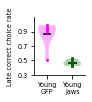

In [133]:
########################################################################
##### Figure 6d #####
########################################################################
set_rcParams()
plt.figure(figsize=np.array([0.7,0.8])*1)
axi = plt.axes([0,0,1,1])
set_plot(axi)

colors1 = ['magenta', 'darkgreen']
Frac =[]
for i, subject_list in enumerate(YoungGFPvJaws): 
    fractions = np.array([])
    for subject in subject_list:
        sessions = find_sessions(subject)
        
        y = FullContrastPerf(sessions) 
        if len(y)>25:
            learning = np.nanmean(y[25:30])
        else:
            learning = np.nanmean(y[-5:])
        fraction = learning
        
        if not np.isnan(fraction):
            fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
    Frac.append(fractions)
    vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)
    
    for pc in vp['bodies']:
        pc.set_facecolor(colors1[i])
    vp['cmeans'].set_color('black')
    axi.plot(i*np.ones(fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
    axi.set_ylim(0.3, 1.1)
    axi.set_yticks(np.arange(0.3,0.9,0.2))
    if i==1:
        axi.set_xticks([0,1])
        axi.set_xticklabels([f'Young\nGFP', f'Young\nJaws'], fontsize=6.5)
        axi.set_xlim(-0.5, 1.5)

    axi.set_ylabel('Late correct choice rate', fontsize=6.5)


plt.savefig('Fig6d_Opto_learning_JawsViolin.svg')


groups = {
    "Young GFP": Frac[0],
    "Young Jaws": Frac[1],
}
results = postHoc_mutipleComparisons(groups, method='fdr_bh', alternative='greater')
results.to_csv(f'posthoc_statistics_fig6d.csv', index=False)

In [134]:
########################################################################
##### Source data: Figure 6d #####
########################################################################

source_rows = []

group_labels = ['Young GFP', 'Young Jaws']

for gi, subject_list in enumerate(YoungGFPvJaws):

    for subject in subject_list:

        sessions = find_sessions(subject)
        y = FullContrastPerf(sessions)

        if len(y) > 25:
            learning = np.nanmean(y[25:30])
            window_used = 'Sessions 26-30'
        else:
            learning = np.nanmean(y[-5:])
            window_used = 'Last 5 sessions'

        if np.isfinite(learning):
            source_rows.append({
                'Mouse_ID': subject,
                'Group': group_labels[gi],
                'Late_correct_choice_rate': learning,
                'Sessions_used': window_used
            })


Fig6d_source = pd.DataFrame(source_rows)

Fig6d_source.to_csv(
    'Fig6d_source_data.csv',
    index=False
)

## Figure S12
Young Jaws Light-off vs Light-on

(array([False, False, False, False]), array([1., 1., 1., 1.]), 0.012741455098566168, 0.0125)
(array([False, False, False, False]), array([0.9375, 0.9375, 0.9375, 0.9375]), 0.012741455098566168, 0.0125)
(array([False, False, False, False]), array([0.530875, 0.530875, 0.530875, 0.530875]), 0.012741455098566168, 0.0125)
(array([False, False, False, False]), array([0.0625, 0.0625, 0.0625, 0.0625]), 0.012741455098566168, 0.0125)


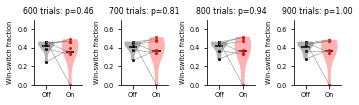

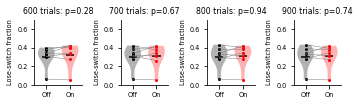

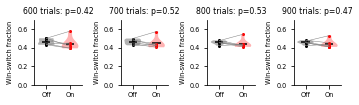

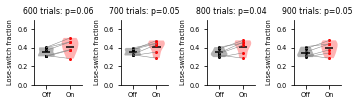

In [135]:
########################################################################
##### Figure S12 #####
########################################################################
results=[]
corrected_ps=[]
YoungGFP1 = YoungGFPvJaws[0]
YoungJaws1 = YoungGFPvJaws[1]

for gi, group in enumerate(['Jaws', 'GFP']):
    for ti, etype in enumerate(['Win-switch', 'Lose-switch']):
        if gi==0:
            subjects_list = [YoungJaws1, YoungJaws1]
        else:
            subjects_list = [YoungGFP1, YoungGFP1]
        
        set_rcParams()
        fig = plt.figure(figsize=np.array([6, 0.9])*1)

        colors1 = ['black', 'red']
        pvals=[]
        for ni, numT in enumerate(np.arange(600, 1000, 100)):
            Frac =[]
            # Reuse one Axes for both conditions. Matplotlib 3.8 otherwise
            # places the second Axes over the first and hides the control artists.
            axi = plt.axes((0.2*ni, 0, 0.11, 1))
            set_plot(axi)

            for i, subject_list in enumerate(subjects_list): 
                fractions = np.array([])
                for subject in subject_list:
                    sessions = find_sessions(subject)

                    if ti==0:
                        fraction, nTrs = FractionSwitch(sessions[:3], opto=i, numTR=numT, offset=0, win_switch=True)
                    else:
                        fraction, nTrs = FractionSwitch(sessions[:3], opto=i, numTR=numT, offset=0, lose_switch=True)

                    if not np.isnan(fraction):
                        fractions = np.hstack((fractions, fraction)) if fractions.size else fraction
                Frac.append(fractions)
                vp = axi.violinplot(fractions, [i], showmeans=True, showextrema=False, widths=0.7)

                for pc in vp['bodies']:
                    pc.set_facecolor(colors1[i])
                vp['cmeans'].set_color('black')
                axi.plot(i*np.ones(fractions.shape[0])+ 0*np.random.default_rng().normal(0, 0.1, size=fractions.shape[0]), fractions, '.', color=colors1[i], markersize=4)
                axi.set_ylim(0.0, 0.7)
            #    axi.set_yticks(np.arange(0.3,0.6,0.1))
                axi.set_xticks([0, 1])
                axi.set_xticklabels(['Off', 'On'], fontsize=6.5)
                axi.set_xlim(-0.5, 1.5)

                axi.set_ylabel(f'{etype} fraction', fontsize=6.5)

            plt.plot(np.array(Frac), color='gray', linewidth=0.5)
            x = Frac[0]
            y = Frac[1]
            test = pairedTest(x,y)  
            p = test['p']
            results.append(pairedTest(x,y))
            plt.title(f"{numT} trials: p={p:0.2f}")
            pvals.append(p)
        plt.savefig(f'FigS12_Opto_explore_violin_diff_{group}_{etype}.svg')
        corrected = multipletests(pvals, method='fdr_bh')
        print(corrected)
        if len(corrected_ps)==0:
            corrected_ps = corrected[1]
        else:
            corrected_ps = np.hstack((corrected_ps, corrected[1]))
results2 = []
for ri, res in enumerate(results):
    res['p_adj'] = corrected_ps[ri]
    results2.append(res)
df = pd.DataFrame(results2)
df.to_csv('statistical_results_figS12.csv', index=False)

In [136]:
########################################################################
##### Source data: Figure S12 #####
########################################################################

source_rows = []

YoungGFP1 = YoungGFPvJaws[0]
YoungJaws1 = YoungGFPvJaws[1]

for group_label, subject_list in zip(
        ['Jaws', 'GFP'],
        [YoungJaws1, YoungGFP1]):

    for switch_type in ['Win-switch', 'Lose-switch']:

        for numT in np.arange(600, 1000, 100):

            for subject in subject_list:

                sessions = find_sessions(subject)

                # Light OFF
                if switch_type == 'Win-switch':
                    off_fraction, off_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=0,
                        numTR=numT,
                        offset=0,
                        win_switch=True
                    )
                else:
                    off_fraction, off_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=0,
                        numTR=numT,
                        offset=0,
                        lose_switch=True
                    )

                # Light ON
                if switch_type == 'Win-switch':
                    on_fraction, on_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=1,
                        numTR=numT,
                        offset=0,
                        win_switch=True
                    )
                else:
                    on_fraction, on_nTrs = FractionSwitch(
                        sessions[:3],
                        opto=1,
                        numTR=numT,
                        offset=0,
                        lose_switch=True
                    )

                source_rows.append({
                    'Mouse_ID': subject,
                    'Group': group_label,
                    'Switch_type': switch_type,
                    'Cumulative_trial_window': numT,
                    'Off_num_trials_used': off_nTrs,
                    'On_num_trials_used': on_nTrs,
                    'Off_switch_fraction': off_fraction,
                    'On_switch_fraction': on_fraction
                })


FigS12_source = pd.DataFrame(source_rows)

FigS12_source.to_csv(
    'FigS12_source_data.csv',
    index=False
)

## Figure S7: ChRmine Opto Validation

In [137]:
##### Load subject database and compile mice from control and optogenetic experiments

SubjectDB = np.load(root / '2026Aging_SubjectDB.npy', allow_pickle = True).item()

group_criteria = [
    combine_criteria(2, 22,   ['experiment'], ['ChRmine_2P']),
    combine_criteria(2, 22, ['experiment'], ['Control_2P']),
    combine_criteria(2, 22, ['experiment'], ['Jaws_2P']),
]  
OptoValidation, Opto_group_names, Opto_ages, Opto_sexes, _ = group_subjects(group_criteria, SubjectDB)

for age in Opto_ages:
    print(f'Age: {[np.round(np.nanmin(age)), np.round(np.nanmax(age))]}')

Age: [3.0, 5.0]
Age: [4.0, 4.0]
Age: [4.0, 4.0]


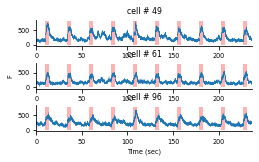

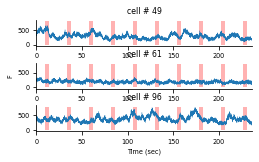

In [138]:
########################################################################
##### Figure S7b #####
########################################################################
#Example ChRmine Neurons : 22mW vs 0mW raw trace

Subject = OptoValidation[0][1]
neural_data, FramePulses, EpochNum, FrameRate, bleach_info = read_OPTOcell_data(Subject)
EpochNum = np.repeat(np.arange(4), 15)
numEpochs = len(np.unique(EpochNum)) 

pulsesPerEpoch = len(FramePulses)/numEpochs

#Extract stimulation configuation information
pmtCloseTime = float(bleach_info['pmtCloseTime'])/1000
packetTime = (
    (float(bleach_info['bleachTime'])+float(bleach_info['bleachIdleTime']))*(float(bleach_info['bleachIteration'])-1)+
    float(bleach_info['bleachTime'])+
    float(bleach_info['outDelayTime'])
    )/1000

epoch = 3
for epoch in [3, 0]:
    frames = FramePulses[np.flatnonzero(EpochNum == epoch)]
    packets = np.flatnonzero(FramePulses[1:]-FramePulses[:-1]>0.1*FrameRate)+1
    frontPulses = np.concatenate(([0], packets), axis=0)
    frontPulses = frames[frontPulses[1:11]]

    fig = plt.figure(figsize=[3, 1.8])
    set_rcParams()

    baseline_avg = []
    stim_avg = []
    for ci, cell in enumerate([49,61,96]): # example ChRmine neurons
        baseline_cell = []
        stim_cell = []
        ax = plt.axes((0, 0.7-0.33*ci, 1, 0.2))
        set_plot(ax)
        intervals = np.arange(frontPulses[0]-300, frontPulses[-1]+300)
        signal = neural_data['F'][cell][intervals]
        time_intervals = (intervals-intervals[0])/FrameRate
        plt.plot(time_intervals, signal, linewidth=0.3)
        plt.title(f'cell # {cell}')
    #     ylims = plt.ylim()
        ylims = [0, 800]

        for front in frontPulses:
            frontP = front[0]/FrameRate-intervals[0]/FrameRate
            endP = frontP + packetTime
            x = np.array([frontP, endP])
            y1 = np.array([ylims[0], ylims[0]])
            y2 = np.array([ylims[1], ylims[1]])
            plt.fill_between(x, y1, y2, color='red', alpha=0.3, linewidth=0)
            stim_front_frame = front[0]-intervals[0]
            stim_end_frame = stim_front_frame+int(np.floor(packetTime*FrameRate))
            bef_stim_frame = stim_front_frame - 30
            baseline_cell.append(np.mean(signal[bef_stim_frame:stim_front_frame]))
            stim_cell.append(np.mean(signal[stim_front_frame:stim_end_frame]))
        baseline_avg.append(baseline_cell)
        stim_avg.append(stim_cell)    
        plt.xlim(time_intervals[0], time_intervals[-1])
        if ci==1:
            plt.ylabel('F')
    plt.xlabel('Time (sec)')   
    

In [139]:
########################################################################
##### Source data: Figure S7b #####
########################################################################

source_rows = []

Subject = OptoValidation[0][1]

neural_data, FramePulses, EpochNum, FrameRate, bleach_info = \
    read_OPTOcell_data(Subject)

# Same epoch assignment used for the figure
EpochNum = np.repeat(np.arange(4), 15)

# Stimulation duration
packetTime = (
    (float(bleach_info['bleachTime']) +
     float(bleach_info['bleachIdleTime'])) *
    (float(bleach_info['bleachIteration']) - 1)
    +
    float(bleach_info['bleachTime'])
    +
    float(bleach_info['outDelayTime'])
) / 1000

# Conditions shown in Fig. 7b
epoch_info = {
    3: '22 mW',
    0: '0 mW'
}

example_cells = [49, 61, 96]

for epoch, power_label in epoch_info.items():

    frames = FramePulses[
        np.flatnonzero(EpochNum == epoch)
    ]

    packets = (
        np.flatnonzero(
            FramePulses[1:] - FramePulses[:-1]
            > 0.1 * FrameRate
        ) + 1
    )

    frontPulses = np.concatenate(
        ([0], packets),
        axis=0
    )

    # Same stimulation packets displayed in the figure
    frontPulses = frames[frontPulses[1:11]]

    # Same displayed imaging interval
    intervals = np.arange(
        frontPulses[0] - 300,
        frontPulses[-1] + 300
    )

    time_intervals = (
        intervals - intervals[0]
    ) / FrameRate

    # Identify samples occurring during light delivery
    stim_on = np.zeros(len(intervals), dtype=int)

    for front in frontPulses:

        stim_start = int(front[0])

        stim_end = (
            stim_start +
            int(np.floor(packetTime * FrameRate))
        )

        stim_on[
            (intervals >= stim_start) &
            (intervals < stim_end)
        ] = 1

    # Export each example neuron
    for cell in example_cells:

        signal = neural_data['F'][cell][intervals]

        for t, frame, value, light in zip(
                time_intervals,
                intervals,
                signal,
                stim_on):

            source_rows.append({
                'Mouse_ID': Subject,
                'Cell_index': cell,
                'Light_power': power_label,
                'Epoch': epoch,
                'Time_sec': t,
                'Imaging_frame_index': int(frame),
                'Fluorescence_au': value,
                'Light_on': light
            })


Fig7b_source = pd.DataFrame(source_rows)

Fig7b_source.to_csv(
    'FigS7b_source_data.csv',
    index=False
)

ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  0.0009765625
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  1.7179713663538132e-09
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  7.956098890679025e-11
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 4876.0 , p_val:  0.4110317762158451


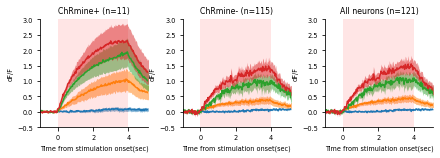

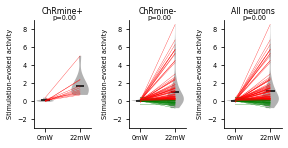

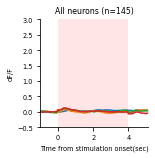

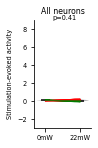

In [140]:
########################################################################
##### Figure S7c-f #####
########################################################################
EpochLegends = ['0mW', '6mW', '16mW', '22mW']
NumPMTopenEpochs = 4

Subject = OptoValidation[0][1]
redCells = [34, 49, 56, 61, 74, 96, 117, 136, 141, 150, 153]
opto_effect_RedCells, opto_effect_nonRedCells, opto_effect_ChRmine=PlotOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells, 
               manualEpoch=15, ylims1=[-0.5, 3.0], ylims2=[-3, 9], Plot=True) 

EpochLegends = ['0mW', '6mW', '16mW', '22mW']
NumPMTopenEpochs = 4

Subject = OptoValidation[1][0]
opto_effect = PlotOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells, 
                manualEpoch=15, ylims1=[-0.5, 3.0], ylims2=[-3, 9], Plot=True, CellTypes=[2]) 

In [141]:
########################################################################
##### Figure S7c-f source data #####
########################################################################

EpochLegends = ['0 mW', '6 mW', '16 mW', '22 mW']

redCells = [
    34, 49, 56, 61, 74,
    96, 117, 136, 141, 150, 153
]

# ------------------------------------------------------------
# Subjects
# ------------------------------------------------------------

ChRmine_subject = OptoValidation[0][1]
Control_subject = OptoValidation[1][0]

# ------------------------------------------------------------
# Extract data using same calculations as PlotOptoResponse
# ------------------------------------------------------------

ChRmine_data = extract_opto_response_source(
    ChRmine_subject,
    NumPMTopenEpochs=4,
    redCells=redCells,
    manualEpoch=15
)

Control_data = extract_opto_response_source(
    Control_subject,
    NumPMTopenEpochs=4,
    redCells=[],
    manualEpoch=15
)


########################################################################
##### S7c/e: ΔF/F time traces #####
########################################################################

trace_rows = []

datasets = [
    ('ChRmine', ChRmine_subject, ChRmine_data),
    ('No-opsin control', Control_subject, Control_data)
]

for dataset_label, subject, data in datasets:

    AllCellSig = data['AllCellSig']
    time = data['time']
    iscell = data['iscell']

    cells = np.flatnonzero(
        iscell[:, 0]
    )

    for cell in cells:

        # Assign ChRmine expression class
        if dataset_label == 'ChRmine':

            if cell in redCells:
                cell_type = 'ChRmine+'
            else:
                cell_type = 'ChRmine-'

        else:
            cell_type = 'No-opsin'

        for epoch, power in enumerate(EpochLegends):

            trace = AllCellSig[
                cell,
                epoch,
                :
            ]

            for t, value in zip(
                    time, trace):

                trace_rows.append({
                    'Mouse_ID': subject,
                    'Experimental_group': dataset_label,
                    'Cell_index': int(cell),
                    'Cell_type': cell_type,
                    'Light_power': power,
                    'Time_from_stimulation_onset_sec': t,
                    'dF_over_F0': value
                })


FigS7ce_source = pd.DataFrame(
    trace_rows
)

FigS7ce_source.to_csv(
    'FigS7ce_source_data.csv',
    index=False
)


########################################################################
##### S7d/f: stimulation-evoked activity #####
########################################################################

response_rows = []

for dataset_label, subject, data in datasets:

    responses = data[
        'stimEvokedResponse'
    ]

    iscell = data['iscell']

    cells = np.flatnonzero(
        iscell[:, 0]
    )

    for cell in cells:

        if dataset_label == 'ChRmine':

            if cell in redCells:
                cell_type = 'ChRmine+'
            else:
                cell_type = 'ChRmine-'

        else:
            cell_type = 'No-opsin'

        for epoch, power in enumerate(EpochLegends):

            response_rows.append({
                'Mouse_ID': subject,
                'Experimental_group': dataset_label,
                'Cell_index': int(cell),
                'Cell_type': cell_type,
                'Light_power': power,
                'Stimulation_evoked_activity_dF_over_F0':
                    responses[cell, epoch]
            })


FigS7df_source = pd.DataFrame(
    response_rows
)

FigS7df_source.to_csv(
    'FigS7df_source_data.csv',
    index=False
)

ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  0.015625
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 21.0 , p_val:  2.276522317826996e-06
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 23.0 , p_val:  1.288098763609539e-07
ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  0.0009765625
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  1.7179713663538132e-09
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  7.956098890679025e-11
ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  2.5630832507250074e-06
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 13.0 , p_val:  4.0991347364324454e-14
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 13.0 , p_val:  5.778702053925596e-19
ChRmine+ dF/F(0 mW vs 22 mW): [T-test] t_val: 13.957429804916812 , p_val:  0.005094021111711385
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 4696.0 , p_val:  0.3623666992345096
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 4876.0 , p_va

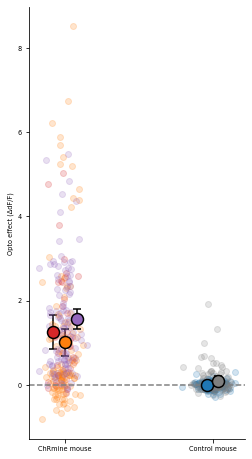

Shapiro-Wilk p = 0.8876734972000122
ChRmine: [1.2539936, 1.0095626, 1.5539417]
Control: [-0.008121542, 0.0961644]
t = 7.407971058550809
p = 0.010390882158935369
1.2724993 0.27266094 1.2539936 1.1317781209945679 1.4039676785469055 0.044021428 0.073741294 0.044021428 0.01794994343072176 0.07009291276335716


In [142]:
########################################################################
##### Figure S7g #####
########################################################################
EpochLegends = ['0mW', '6mW', '16mW', '22mW']
NumPMTopenEpochs = 4
ChRmineCells = [
    [8, 22, 30, 237, 240, 254, 259],
    [34, 49, 56, 61, 74, 96, 117, 136, 141, 150, 153],
    [7, 14, 15, 18, 19, 21, 25, 26, 27, 30, 31, 32, 38, 40, 43, 47, 48, 49, 51, 58, 63, 65, 71, 72, 73, 80, 99, 102, 104],
]

manual = [None, 15, None]
chrmine = []
for si, subject in enumerate(OptoValidation[0]):
    redCells = ChRmineCells[si]
    chP, chN, All = PlotOptoResponse(subject, EpochLegends, NumPMTopenEpochs, redCells, 
                manualEpoch=manual[si])
    chrmine.append(All) 
manual = [None, None] 
control = []
for si, subject in enumerate(OptoValidation[1]):
    chP, chN, All = PlotOptoResponse(subject, EpochLegends, NumPMTopenEpochs, 
                manualEpoch=manual[si])
    control.append(All)    
chrmine = np.array(chrmine, dtype=object)
control = np.array(control, dtype=object)

jitter = 0.06
rng = np.random.default_rng(10)

chrmine_mean_x = [-0.08, 0, 0.08]
control_mean_x = [0.96, 1.04]
plt.figure(figsize=(3,6))
set_plot(plt.axes([0, 0, 1, 1]))

colors_chr = ['tab:red', 'tab:orange', 'tab:purple']
colors_c = ['tab:blue', 'tab:gray']

# ChRmine mice
for i,data in enumerate(chrmine):
    x = rng.normal(0, jitter, len(data))
    plt.plot(x, data, 'o', color=colors_chr[i], alpha=0.2)
    mean = np.mean(data)
    sem = stats.sem(data)
    plt.errorbar(chrmine_mean_x[i], mean, yerr=2*sem,fmt='o',color=colors_chr[i],ecolor='black',markersize=12,markeredgecolor='black',
                 markeredgewidth=1.5, capsize=4, elinewidth=1.5)
# Control mice
for i,data in enumerate(control):
    x = rng.normal(1, jitter, len(data))
    plt.plot(x, data, 'o', color=colors_c[i], alpha=0.2)
    mean = np.mean(data)
    sem = 2*stats.sem(data)
    plt.errorbar(control_mean_x[i], mean, yerr=2*sem, fmt='o', color=colors_c[i],ecolor='black',markersize=12,markeredgecolor='black',
                 markeredgewidth=1.5, capsize=4, elinewidth=1.5)
plt.xticks([0, 1], ['ChRmine mouse', 'Control mouse'])
plt.ylabel('Opto effect (ΔdF/F)')
plt.axhline(0, color='gray', linestyle='--')
plt.show()

# statistical test results
# ChRmine mouse averages
chrmine_avg = []
for chR in chrmine:
    chrmine_avg.append(np.mean(chR))
stat, p = stats.shapiro(chrmine_avg)
print("Shapiro-Wilk p =", p)
# Control mouse averages
control_avg = []
for crtl in control:
    control_avg.append(np.mean(crtl))
# Welch's t-test
t, p = stats.ttest_ind(chrmine_avg,control_avg,equal_var=False)

print("ChRmine:", chrmine_avg)
print("Control:", control_avg)
print("t =", t)
print("p =", p)
mean,std,median,Q1,Q3,mean_2,std_2,median_2,Q1_2,Q3_2=stats_info(chrmine_avg,control_avg)
print(mean,std,median,Q1,Q3,mean_2,std_2,median_2,Q1_2,Q3_2)

In [143]:
########################################################################
##### Source data: Figure S7g #####
########################################################################

source_rows = []

EpochLegends = ['0mW', '6mW', '16mW', '22mW']
NumPMTopenEpochs = 4

ChRmineCells = [
    [8, 22, 30, 237, 240, 254, 259],
    [34, 49, 56, 61, 74, 96, 117, 136, 141, 150, 153],
    [7, 14, 15, 18, 19, 21, 25, 26, 27, 30, 31, 32,
     38, 40, 43, 47, 48, 49, 51, 58, 63, 65, 71, 72,
     73, 80, 99, 102, 104],
]

manual_chrmine = [None, 15, None]
manual_control = [None, None]


########################################################################
##### ChRmine mice #####
########################################################################

for si, subject in enumerate(OptoValidation[0]):

    redCells = ChRmineCells[si]

    chP, chN, All = PlotOptoResponse(
        subject,
        EpochLegends,
        NumPMTopenEpochs,
        redCells,
        manualEpoch=manual_chrmine[si]
    )

    mouse_mean = np.nanmean(All)

    for neuron_i, value in enumerate(All):

        source_rows.append({
            'Mouse_ID': subject,
            'Experimental_group': 'ChRmine',
            'Neuron_index_within_output': neuron_i,
            'Optogenetic_effect_delta_dF_over_F': value,
            'Mouse_mean_optogenetic_effect': mouse_mean
        })


########################################################################
##### No-opsin control mice #####
########################################################################

for si, subject in enumerate(OptoValidation[1]):

    chP, chN, All = PlotOptoResponse(
        subject,
        EpochLegends,
        NumPMTopenEpochs,
        manualEpoch=manual_control[si]
    )

    mouse_mean = np.nanmean(All)

    for neuron_i, value in enumerate(All):

        source_rows.append({
            'Mouse_ID': subject,
            'Experimental_group': 'No-opsin control',
            'Neuron_index_within_output': neuron_i,
            'Optogenetic_effect_delta_dF_over_F': value,
            'Mouse_mean_optogenetic_effect': mouse_mean
        })


########################################################################
##### Save source data #####
########################################################################

FigS7g_source = pd.DataFrame(source_rows)

FigS7g_source.to_csv(
    'FigS7g_source_data.csv',
    index=False
)

ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  0.015625
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 21.0 , p_val:  2.276522317826996e-06
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 23.0 , p_val:  1.288098763609539e-07
ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  0.0009765625
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  1.7179713663538132e-09
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 1177.0 , p_val:  7.956098890679025e-11
ChRmine+ dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 0.0 , p_val:  2.5630832507250074e-06
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 13.0 , p_val:  4.0991347364324454e-14
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 13.0 , p_val:  5.778702053925596e-19
ChRmine+ dF/F(0 mW vs 22 mW): [T-test] t_val: 13.957429804916812 , p_val:  0.005094021111711385
ChRmine- dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 4696.0 , p_val:  0.3623666992345096
All neurons dF/F(0 mW vs 22 mW): [Wilcoxon] r_val: 4876.0 , p_va

## Figure S10: Jaws Opto Validation

Auditory-responsive dF/F(0 mW vs 22 mW): [T-test] t_val: -7.055696098765139 , p_val:  2.1109027018552686e-05
Auditory-nonresponsive dF/F(0 mW vs 22 mW): [T-test] t_val: -1.8576093535341434 , p_val:  0.0755365008447564
All neurons dF/F(0 mW vs 22 mW): [T-test] t_val: -4.210062332687886 , p_val:  0.0001625821084856192


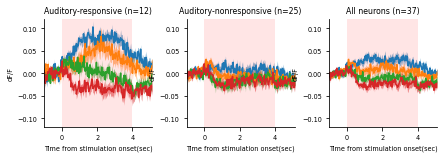

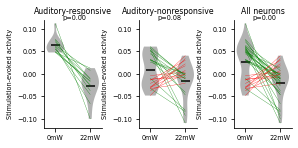

In [144]:
########################################################################
##### Figure S10b-c #####
########################################################################

Subject = OptoValidation[2][0]
EpochLegends = ['0mW', '6mW', '17mW', '22mW']
NumPMTopenEpochs = len(EpochLegends)
redCells=Aud_responsive(Subject, EpochLegends, NumPMTopenEpochs) 
AudP, AudN, All= PlotOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells=redCells,
                ylims1=[-0.12, 0.12], ylims2=[-0.12, 0.12], Plot=True, 
                CellLabels = ['Auditory-responsive', 'Auditory-nonresponsive']) 

results= StatOptoResponse(Subject, EpochLegends, NumPMTopenEpochs, redCells=redCells,
                ylims1=[-0.12, 0.12], ylims2=[-0.12, 0.12], Plot=True, 
                CellLabels = ['Auditory-responsive', 'Auditory-nonresponsive']) 
    
df = pd.DataFrame(results)
df.to_csv('statistical_results_figS10a.csv', index=False)

In [145]:
########################################################################
##### Source data: Figure S10b-c #####
########################################################################

Subject = OptoValidation[2][0]

EpochLegends = ['0mW', '6mW', '17mW', '22mW']
NumPMTopenEpochs = len(EpochLegends)

# ------------------------------------------------------------
# Identify auditory-responsive neurons exactly as in the figure
# ------------------------------------------------------------

auditory_responsive_cells = Aud_responsive(
    Subject,
    EpochLegends,
    NumPMTopenEpochs
)

auditory_responsive_cells = np.asarray(
    auditory_responsive_cells,
    dtype=int
)


# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

neural_data, FramePulses, EpochNum, FrameRate, bleach_info = \
    read_OPTOcell_data(Subject)


# ------------------------------------------------------------
# Stimulation timing
# Same calculations used by PlotOptoResponse()
# ------------------------------------------------------------

pre_stim_time = 1
post_stim_time = 6.1

packetTime = (
    (
        float(bleach_info['bleachTime']) +
        float(bleach_info['bleachIdleTime'])
    )
    * (float(bleach_info['bleachIteration']) - 1)
    +
    float(bleach_info['bleachTime'])
    +
    float(bleach_info['outDelayTime'])
) / 1000

stim_duration = packetTime

post_stim_length = int(
    post_stim_time * FrameRate
)

pre_stim_length = int(
    pre_stim_time * FrameRate
)

baseline_length = pre_stim_length

stim_end = int(
    (pre_stim_time + stim_duration) * FrameRate
)


# ------------------------------------------------------------
# Find beginning of stimulation packets
# ------------------------------------------------------------

packets = (
    np.flatnonzero(
        FramePulses[1:] - FramePulses[:-1]
        > 0.1 * FrameRate
    ) + 1
)

packets = np.concatenate(
    ([0], packets)
)


# ------------------------------------------------------------
# Extract neuron-level responses
# ------------------------------------------------------------

AllCellSig = []
stimEvokedResponse = []

all_cells = np.flatnonzero(
    neural_data['iscell'][:, 0]
)

for cell in range(neural_data['iscell'].shape[0]):

    CellSig = []
    delta = []

    f = neural_data['F'][cell]

    for epoch in range(NumPMTopenEpochs):

        BigSig = []
        j = 0

        for pi in packets:

            if (
                EpochNum[pi] == epoch
                and j < 15
            ):

                stim_frame = int(
                    FramePulses[pi]
                )

                inds = (
                    np.arange(
                        -pre_stim_length,
                        post_stim_length
                    )
                    + stim_frame
                )

                f0 = np.mean(
                    f[
                        stim_frame - baseline_length:
                        stim_frame
                    ]
                )

                signal = (
                    f[inds] - f0
                ) / f0

                # Same exclusion used by PlotOptoResponse:
                # first 3 stimulation trials omitted
                if j > 2:
                    BigSig.append(signal)

                j += 1

        BigSig = np.asarray(BigSig)

        meanSig = np.nanmean(
            BigSig,
            axis=0
        )

        baseline_mean = np.nanmean(
            meanSig[:baseline_length]
        )

        stim_mean = np.nanmean(
            meanSig[
                baseline_length:stim_end
            ]
        )

        CellSig.append(meanSig)

        delta.append(
            stim_mean - baseline_mean
        )

    AllCellSig.append(
        np.asarray(CellSig)
    )

    stimEvokedResponse.append(
        np.asarray(delta)
    )


AllCellSig = np.asarray(AllCellSig)

stimEvokedResponse = np.asarray(
    stimEvokedResponse
)


# ------------------------------------------------------------
# Time vector
# ------------------------------------------------------------

time = (
    np.arange(AllCellSig.shape[-1])
    / FrameRate
    - pre_stim_time
)

# Match PlotOptoResponse convention exactly
time = time - time[pre_stim_length]


########################################################################
##### Figure S10b source data: ΔF/F traces #####
########################################################################

trace_rows = []

for cell in all_cells:

    if cell in auditory_responsive_cells:
        cell_type = 'Auditory-responsive'
    else:
        cell_type = 'Auditory-nonresponsive'

    for epoch, power in enumerate(EpochLegends):

        trace = AllCellSig[
            cell,
            epoch,
            :
        ]

        for t, value in zip(
                time,
                trace):

            trace_rows.append({
                'Mouse_ID': Subject,
                'Cell_index': int(cell),
                'Cell_type': cell_type,
                'Light_power': power,
                'Time_from_stimulation_onset_sec': t,
                'dF_over_F0': value
            })


FigS10b_source = pd.DataFrame(
    trace_rows
)

FigS10b_source.to_csv(
    'FigS10b_source_data.csv',
    index=False
)


########################################################################
##### Figure S10c source data: stimulation-evoked activity #####
########################################################################

response_rows = []

for cell in all_cells:

    if cell in auditory_responsive_cells:
        cell_type = 'Auditory-responsive'
    else:
        cell_type = 'Auditory-nonresponsive'

    opto_effect = (
        stimEvokedResponse[cell, -1]
        - stimEvokedResponse[cell, 0]
    )

    for epoch, power in enumerate(EpochLegends):

        response_rows.append({
            'Mouse_ID': Subject,
            'Cell_index': int(cell),
            'Cell_type': cell_type,
            'Light_power': power,
            'Stimulation_evoked_activity_dF_over_F0':
                stimEvokedResponse[cell, epoch],
            'Optogenetic_effect_22mW_minus_0mW':
                opto_effect
        })


FigS10c_source = pd.DataFrame(
    response_rows
)

FigS10c_source.to_csv(
    'FigS10c_source_data.csv',
    index=False
)


print(
    f'Auditory-responsive neurons: '
    f'{len(auditory_responsive_cells)}'
)

print(
    f'Auditory-nonresponsive neurons: '
    f'{len(all_cells) - len(auditory_responsive_cells)}'
)

Auditory-responsive neurons: 12
Auditory-nonresponsive neurons: 25


## Figure S11: Jaws cFOs Validation

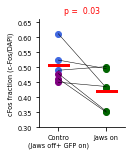

In [146]:
########################################################################
##### Figure S11 #####
########################################################################
df =  pd.read_csv(Path(cFos,"CfosJawsValidation.csv"))

# Pool multiple ROIs from the same group, mouse and brain side
summary = (
    df.groupby(["Group", "MouseID", "Side"], as_index=False)
      .agg({
          "Num Detections": "sum",
          "Num Fos": "sum",
      })
)

# Fraction of DAPI cells that are c-Fos+
summary["cFos_fraction"] = (
    summary["Num Fos"] /
    summary["Num Detections"]
)


colors = [
    ['royalblue', 'darkgreen'],
    ['purple', 'darkgreen'],
]

fig = plt.figure(figsize=np.array([1.2, 1.5])*1)
axi = plt.axes((0, 0, 1, 1))
set_plot(axi)


Frac = []
for group in [1, 2]:
    fractions = []
    for side in ["L", "R"]:
        fraction = summary.loc[(summary["Group"] == group) & (summary["Side"] == side), "cFos_fraction"].to_numpy() #c-Fos+ fraction
        x = int(0) if side=="L" else int(1)    
        plt.plot(x*np.ones(len(fraction),), fraction, '.', color=colors[group-1][x], markersize=12)
        if len(fractions)==0:
            fractions = fraction
        else:
            fractions = np.vstack((fractions,fraction))
    plt.plot(fractions, color='black', linewidth=0.5)
    Frac.append(fractions)
    
Frac = np.array(Frac) 

for i, frac in enumerate(Frac):
    plt.plot([i-0.2, i+0.2], [np.nanmean(frac),np.nanmean(frac)], linewidth=3, color='red')

x = Frac[:,0]
y = Frac[:,1]
test=twoSampleTest(x, y, alternative='greater')
p = test['p']
plt.title(f'p = {p: 1.2f}', color='red')
plt.xticks(range(2), labels=[f'Contro\n(Jaws off+ GFP on)', 'Jaws on'])
plt.ylabel('cFos fraction (c-Fos/DAPI)')
plt.xlim(-0.4, 1.4)
plt.ylim(0.3, 0.66)
plt.savefig('Fig11c_JawsCFOS.svg')

In [147]:
########################################################################
##### Source data: Figure S11 #####
########################################################################

FigS11_source = summary.copy()

# Add descriptive condition corresponding to the plotted x-axis
FigS11_source['Condition'] = FigS11_source['Side'].map({
    'L': 'Control',
    'R': 'Jaws on'
})

# Use clearer public-facing column names
FigS11_source = FigS11_source.rename(columns={
    'MouseID': 'Mouse_ID',
    'Num Detections': 'Total_DAPI_cells',
    'Num Fos': 'cFos_positive_cells',
    'cFos_fraction': 'cFos_positive_fraction_of_DAPI_cells'
})

FigS11_source = FigS11_source[
    [
        'Mouse_ID',
        'Group',
        'Side',
        'Condition',
        'Total_DAPI_cells',
        'cFos_positive_cells',
        'cFos_positive_fraction_of_DAPI_cells'
    ]
]

FigS11_source.to_csv(
    'FigS11_source_data.csv',
    index=False
)